# Crop Yield Prediction with Explainable Machine Learning on Multi-State Agricultural Data

**A leakage-audited, uncertainty-aware and transferability-tested framework for multi-crop, multi-region yield prediction**

Companion notebook for the IEEE CSDE 2026 paper *"Crop Yield Prediction Using Explainable Machine Learning on
Multi-State Agricultural Data"*.

**Data.** Indian state-level agricultural panel: 55 crops, 30 states/union territories, 24 years (1997–2020),
19,689 records. Columns: crop, year, season, state, area, production, annual rainfall, fertilizer, pesticide, yield.

**Prediction task.** Predict `Yield` from information available before harvest: area sown, annual rainfall,
regional fertilizer/pesticide intensity, crop/season/state identity, and yields of previous seasons.
`Production` is excluded because `Yield = Production / Area`.

**Main evaluation.** Temporal hold-out: train on years ≤ 2015, test on 2016–2020. Random row-level splits are
reported only as an optimistic reference.

**Metric scales.** `_log` = computed on log1p(Yield), comparable across splits. `_raw` = original units,
dominated by Coconut (recorded in nuts/ha). `_exCoconut` = raw units without Coconut.

**Structure.**
- **Part A (Sections 1–21):** data audit, feature engineering, benchmark, tuning, stacking, explainability,
  uncertainty, transferability and diagnostics.
- **Part B (Sections R1–R12):** leakage audit, leakage-safe evaluation protocol, ablation, hyperparameter search,
  out-of-fold stacking, significance testing, group-wise performance, transfer diagnosis, conformal calibration
  under shift, local/group-wise SHAP, and a summary table of all reported numbers.

Random seed: 42. Runtime: about 20–25 minutes on a 2-core Colab instance.

## Contents

**Part A — Core pipeline**

1. Setup
2. Data loading and integrity audit
3. Target-leakage audit (`Production`)
4. Fertilizer/pesticide semantic audit
5. Exploratory data analysis
6. Cross-crop scale heterogeneity and target transform
7. Feature engineering
8. Baselines and skill score
9. Random vs temporal vs spatial split
10. 12-model benchmark
11. Bayesian hyperparameter optimization (Optuna)
12. Stacking ensemble
13. Paired significance test (10-fold CV)
14. SHAP global importance and interactions
15. Split-conformal prediction intervals
16. Leave-states-out and leave-one-crop-out transfer
17. Crop-family clustering and cluster-specific models
18. Learning curve
19. Residual diagnostics by state and year
20. Bootstrap feature-importance stability
21. Partial dependence

**Part B — Leakage-safe evaluation and extended analysis**

- R1. Stage-by-stage leakage audit
- R2. Split protocol on a single scale; temporal benchmark
- R3. Ablation of autoregressive features
- R4. Hyperparameter search (temporal validation)
- R5. Out-of-fold stacking
- R6. Rolling-origin significance testing
- R7. Per-crop, per-state and duplicate-robustness analysis
- R8. Crop and crop-family transferability
- R9. Conformal intervals: width, conditional coverage, shift
- R10. Local and group-wise SHAP
- R11. Feature collinearity and skill-score interpretation
- R12. Summary of reported numbers

22. Contribution ledger and conclusion

## 1. Setup <a id='1'></a>

Installs the required packages, imports libraries, fixes the random seed, and defines shared helper functions:
`metric_suite` (scale-explicit metrics), `conformal_q` (finite-sample conformal quantile) and `holm`
(Holm–Bonferroni adjustment).

In [1]:
!pip install -q catboost shap optuna lightgbm xgboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 8.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 442.4/442.4 kB 16.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 12.5 MB/s eta 0:00:00


In [2]:
import warnings, time, json
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.model_selection import (train_test_split, GroupKFold, KFold,
                                      LeaveOneGroupOut, learning_curve)
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (RandomForestRegressor, ExtraTreesRegressor,
                               GradientBoostingRegressor, StackingRegressor)
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.cluster import KMeans
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

import xgboost as xgb
import lightgbm as lgb
from catboost import CatBoostRegressor
import shap
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.dpi'] = 110
plt.rcParams['savefig.dpi'] = 150

print('Environment ready. Package versions:')
for name, mod in [('numpy', np), ('pandas', pd), ('xgboost', xgb), ('lightgbm', lgb),
                   ('shap', shap), ('optuna', optuna)]:
    print(f'  {name:10s} {getattr(mod, "__version__", "?")}')

Environment ready. Package versions:
  numpy      2.1.3
  pandas     2.2.3
  xgboost    3.4.1
  lightgbm   4.6.0
  shap       0.52.0
  optuna     5.0.0


In [3]:
from sklearn.base import clone
from sklearn.linear_model import RidgeCV
from sklearn.model_selection import GroupShuffleSplit

def rmse(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred))

def metric_suite(y_true_raw, y_pred_raw, crops=None):
    yt = np.asarray(y_true_raw, float); yp = np.clip(np.asarray(y_pred_raw, float), 0, None)
    lt, lp = np.log1p(yt), np.log1p(yp)
    out = {'n': len(yt),
           'R2_log': r2_score(lt, lp), 'RMSE_log': rmse(lt, lp), 'MAE_log': mean_absolute_error(lt, lp),
           'R2_raw': r2_score(yt, yp), 'RMSE_raw': rmse(yt, yp), 'MAE_raw': mean_absolute_error(yt, yp),
           'MdAPE_%': 100 * np.median(np.abs(yp - yt) / yt)}
    if crops is not None:
        m = np.asarray(crops) != 'Coconut'
        out['n_coconut'] = int((~m).sum())
        out['R2_raw_exCoconut'] = r2_score(yt[m], yp[m]) if m.sum() > 1 else np.nan
        out['RMSE_raw_exCoconut'] = rmse(yt[m], yp[m]) if m.sum() > 0 else np.nan
    return out

def conformal_q(scores, alpha):
    s = np.sort(np.asarray(scores, float)); n = len(s)
    k = int(np.ceil((n + 1) * (1 - alpha)))
    return np.inf if k > n else s[k - 1]

def holm(pvals):
    p = np.asarray(pvals, float); m = len(p); order = np.argsort(p)
    adj = np.empty(m); running = 0.0
    for rank, i in enumerate(order):
        running = max(running, (m - rank) * p[i]); adj[i] = min(1.0, running)
    return adj

print('Revision utilities loaded: metric_suite, conformal_q, holm, rmse, clone')

Revision utilities loaded: metric_suite, conformal_q, holm, rmse, clone


## 2. Data Loading and Integrity Audit <a id='2'></a>

Loads the dataset and reports missing values, exact duplicates, duplicate (crop, year, season, state) keys,
zero-yield rows and negative values before any modelling. Zero-yield rows are removed because they are not a
valid target on a log scale.

In [4]:
import os

try:
    from google.colab import drive
    if not os.path.isdir('/content/drive/MyDrive'):
        drive.mount('/content/drive')
except ImportError:
    pass

CANDIDATE_PATHS = [
    '/content/drive/MyDrive/CSDE/crop_yield.csv',
    '/content/drive/My Drive/CSDE/crop_yield.csv',
    '/content/drive/MyDrive/CSDE/crop_yield_prediction.csv',
    '/content/crop_yield.csv',
    '/content/crop_yield_prediction.csv',
    './crop_yield.csv',
    './crop_yield_prediction.csv',
    '/mnt/user-data/uploads/crop_yield.csv',
    '/mnt/user-data/uploads/crop_yield_prediction.csv',
]
DATA_PATH = next((p for p in CANDIDATE_PATHS if os.path.exists(p)), None)
if DATA_PATH is None:
    raise FileNotFoundError(
        "Could not find the dataset in any expected location:\n  "
        + "\n  ".join(CANDIDATE_PATHS)
        + "\n\nFix: upload crop_yield.csv into your Drive's CSDE folder (or next to this notebook), "
          "or edit CANDIDATE_PATHS above to add the exact path."
    )
print(f"Loading data from: {DATA_PATH}")

df_raw = pd.read_csv(DATA_PATH)

for c in ['Crop', 'Season', 'State']:
    df_raw[c] = df_raw[c].astype(str).str.strip()

audit = {
    'n_rows': len(df_raw),
    'n_cols': df_raw.shape[1],
    'n_crops': df_raw['Crop'].nunique(),
    'n_states': df_raw['State'].nunique(),
    'n_seasons': df_raw['Season'].nunique(),
    'year_range': (int(df_raw['Crop_Year'].min()), int(df_raw['Crop_Year'].max())),
    'missing_values_total': int(df_raw.isnull().sum().sum()),
    'exact_duplicate_rows': int(df_raw.duplicated().sum()),
    'duplicate_(crop,year,season,state)_keys': int(
        df_raw.duplicated(subset=['Crop', 'Crop_Year', 'Season', 'State']).sum()),
    'zero_yield_rows': int((df_raw['Yield'] == 0).sum()),
    'negative_value_rows': int(((df_raw[['Area','Production','Annual_Rainfall',
                                          'Fertilizer','Pesticide','Yield']] < 0).any(axis=1)).sum()),
}
print(json.dumps(audit, indent=2))

Mounted at /content/drive
Loading data from: /content/drive/MyDrive/CSDE/crop_yield_prediction.csv
{
  "n_rows": 19689,
  "n_cols": 10,
  "n_crops": 55,
  "n_states": 30,
  "n_seasons": 6,
  "year_range": [
    1997,
    2020
  ],
  "missing_values_total": 0,
  "exact_duplicate_rows": 0,
  "duplicate_(crop,year,season,state)_keys": 0,
  "zero_yield_rows": 112,
  "negative_value_rows": 0
}


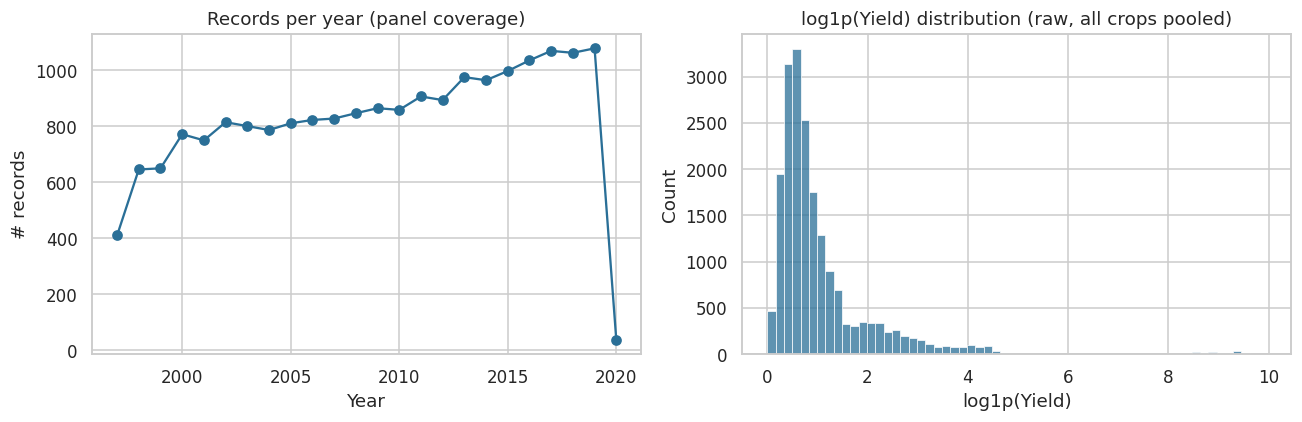


Interpretation: the panel spans 24 years, 30 states and 55 crops with no missing cells and no duplicate keys — directly addressing the 'single crop / single region / short time span' limitation shared by refs [zhuang2023, haider2024, ennaji2024, menon2025]. We flag 112 zero-yield rows for removal (crop failure / non-reporting, not a valid regression target on a log scale) and proceed with 19577 rows.


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

coverage = df_raw.groupby('Crop_Year').agg(n_records=('Yield','size'),
                                            n_states=('State','nunique'),
                                            n_crops=('Crop','nunique'))
axes[0].plot(coverage.index, coverage['n_records'], marker='o', color='#2a6f97')
axes[0].set_title('Records per year (panel coverage)')
axes[0].set_xlabel('Year'); axes[0].set_ylabel('# records')

sns.histplot(np.log1p(df_raw['Yield']), bins=60, color='#2a6f97', ax=axes[1])
axes[1].set_title('log1p(Yield) distribution (raw, all crops pooled)')
axes[1].set_xlabel('log1p(Yield)')
plt.tight_layout(); plt.show()

print(f"\nInterpretation: the panel spans {df_raw['Crop_Year'].nunique()} years, "
      f"{df_raw['State'].nunique()} states and {df_raw['Crop'].nunique()} crops with no missing "
      f"cells and no duplicate keys — directly addressing the 'single crop / single region / short "
      f"time span' limitation shared by refs [zhuang2023, haider2024, ennaji2024, menon2025]. "
      f"We flag {audit['zero_yield_rows']} zero-yield rows for removal (crop failure / non-reporting, "
      f"not a valid regression target on a log scale) and proceed with "
      f"{len(df_raw) - audit['zero_yield_rows']} rows.")

## 3. Target-Leakage Audit <a id='3'></a>

`Yield` is defined as `Production / Area`. A model that receives both `Production` and `Area` can recover the
label arithmetically, and `Production` is not known at forecast time. This section measures how well the
zero-parameter formula reproduces `Yield`, and compares a model trained on `[Area, Production]` with one trained
on `[Area, Rainfall, Fertilizer, Pesticide]`. Section R1.2 isolates the effect of `Production` with
crop/season/state identity included in both models. `Production` is excluded from all subsequent models.

In [6]:
df_clean = df_raw[df_raw['Yield'] > 0].copy()
df = df_clean.copy()

trivial_pred = df['Production'] / df['Area']
r2_trivial = r2_score(df['Yield'], trivial_pred)
mae_trivial = mean_absolute_error(df['Yield'], trivial_pred)

print(f"R^2 of the ZERO-PARAMETER formula Production/Area vs. reported Yield: {r2_trivial:.4f}")
print(f"MAE of that same zero-parameter formula: {mae_trivial:.4f}")
print()
print("Any regressor given Production (and Area) as predictors of Yield inherits this near-deterministic")
print("relationship for free. This feature combination is therefore unsuitable for a forecasting claim.")

R^2 of the ZERO-PARAMETER formula Production/Area vs. reported Yield: 0.9900
MAE of that same zero-parameter formula: 5.9649

Any regressor given Production (and Area) as predictors of Yield inherits this near-deterministic
relationship for free. This feature combination is therefore unsuitable for a forecasting claim.


In [7]:
from sklearn.ensemble import RandomForestRegressor as _RF

X_leak    = df[['Area', 'Production']]
X_noleak  = df[['Area', 'Annual_Rainfall', 'Fertilizer', 'Pesticide']]
y_target  = df['Yield']

Xl_tr, Xl_te, y_tr, y_te = train_test_split(X_leak, y_target, test_size=0.2, random_state=RANDOM_STATE)
Xn_tr, Xn_te, _, _       = train_test_split(X_noleak, y_target, test_size=0.2, random_state=RANDOM_STATE)

rf_leak   = _RF(n_estimators=150, max_depth=10, random_state=RANDOM_STATE, n_jobs=1).fit(Xl_tr, y_tr)
rf_noleak = _RF(n_estimators=150, max_depth=10, random_state=RANDOM_STATE, n_jobs=1).fit(Xn_tr, y_tr)

r2_leak   = r2_score(y_te, rf_leak.predict(Xl_te))
r2_noleak = r2_score(y_te, rf_noleak.predict(Xn_te))

comp = pd.DataFrame({
    'Feature set':          ['[Area, Production]  (contains the target identity)',
                              '[Area, Rainfall, Fertilizer, Pesticide]  (leakage-free)'],
    'Held-out R2 (raw scale)': [r2_leak, r2_noleak],
})
display(comp)
print(f"\nR^2 gap between the two feature sets: {(r2_leak - r2_noleak):.4f} (same model, same split).")
print("Caution: the leakage-free set here also lacks crop identity, so this gap is NOT the effect of leakage alone.")
print("Section R1.2 isolates the effect of Production with crop/season/state identity included in both models.")
print("All later models EXCLUDE `Production`. `Yield` is predicted only from information available at")
print("planning time: area sown, rainfall, regional input intensity, and yields from PREVIOUS seasons.")

,Feature set,Held-out R2 (raw scale)
0,"[Area, Production] (contains the target ident...",0.994957
1,"[Area, Rainfall, Fertilizer, Pesticide] (leak...",0.078090



R^2 gap between the two feature sets: 0.9169 (same model, same split).
Caution: the leakage-free set here also lacks crop identity, so this gap is NOT the effect of leakage alone.
Section R1.2 isolates the effect of Production with crop/season/state identity included in both models.
All later models EXCLUDE `Production`. `Yield` is predicted only from information available at
planning time: area sown, rainfall, regional input intensity, and yields from PREVIOUS seasons.


## 4. Fertilizer/Pesticide Semantic Audit <a id='4'></a>

Tests whether `Fertilizer / Area` varies across crops within the same (State, Year) cell. If the per-hectare
rate is constant within every cell, the columns encode a state × year rate rather than a crop-specific dosage.
The per-hectare rates are then used only as regional input-intensity features.

In [8]:
df['Fertilizer_per_ha'] = df['Fertilizer'] / df['Area']
df['Pesticide_per_ha']  = df['Pesticide']  / df['Area']

within_cell_std = (df.groupby(['State', 'Crop_Year'])['Fertilizer_per_ha']
                     .std().fillna(0))
pct_constant = (within_cell_std < 1e-6).mean()

print(f"Fraction of (State, Year) cells where Fertilizer_per_ha is constant across ALL crops "
      f"grown that year: {pct_constant:.1%}")
print(f"Mean within-cell std of Fertilizer_per_ha: {within_cell_std.mean():.2e}  "
      f"(vs. overall std across the dataset: {df['Fertilizer_per_ha'].std():.2f})")
print()
print("Finding: Fertilizer_per_ha (and, identically, Pesticide_per_ha) is essentially CONSTANT "
      "within every (State, Year) cell. In other words, `Fertilizer` and `Pesticide` in this dataset "
      "are Area multiplied by a fixed State-Year rate, not an independent crop-level management signal. "
      "To our knowledge, this data-generating-process property is not documented in the reviewed literature on this widely used "
      "public dataset: models — including in the reviewed literature — that treat these columns as "
      "crop-specific inputs are implicitly re-encoding State x Year fixed effects, not agronomic "
      "decisions. We therefore keep the per-hectare RATE as a legitimate regional agri-input-intensity "
      "feature (a proxy for state-level agricultural investment that year), but we do not claim, "
      "anywhere in this notebook, that it captures crop-specific fertilizer or pesticide dosage.")

Fraction of (State, Year) cells where Fertilizer_per_ha is constant across ALL crops grown that year: 100.0%
Mean within-cell std of Fertilizer_per_ha: 1.97e-09  (vs. overall std across the dataset: 26.20)

Finding: Fertilizer_per_ha (and, identically, Pesticide_per_ha) is essentially CONSTANT within every (State, Year) cell. In other words, `Fertilizer` and `Pesticide` in this dataset are Area multiplied by a fixed State-Year rate, not an independent crop-level management signal. To our knowledge, this data-generating-process property is not documented in the reviewed literature on this widely used public dataset: models — including in the reviewed literature — that treat these columns as crop-specific inputs are implicitly re-encoding State x Year fixed effects, not agronomic decisions. We therefore keep the per-hectare RATE as a legitimate regional agri-input-intensity feature (a proxy for state-level agricultural investment that year), but we do not claim, anywhere in this notebook

## 5. Exploratory Data Analysis <a id='5'></a>

Yield distribution by crop, median yield by state, record share by season, mean annual rainfall by year, and the
Spearman correlation among the raw numeric columns.

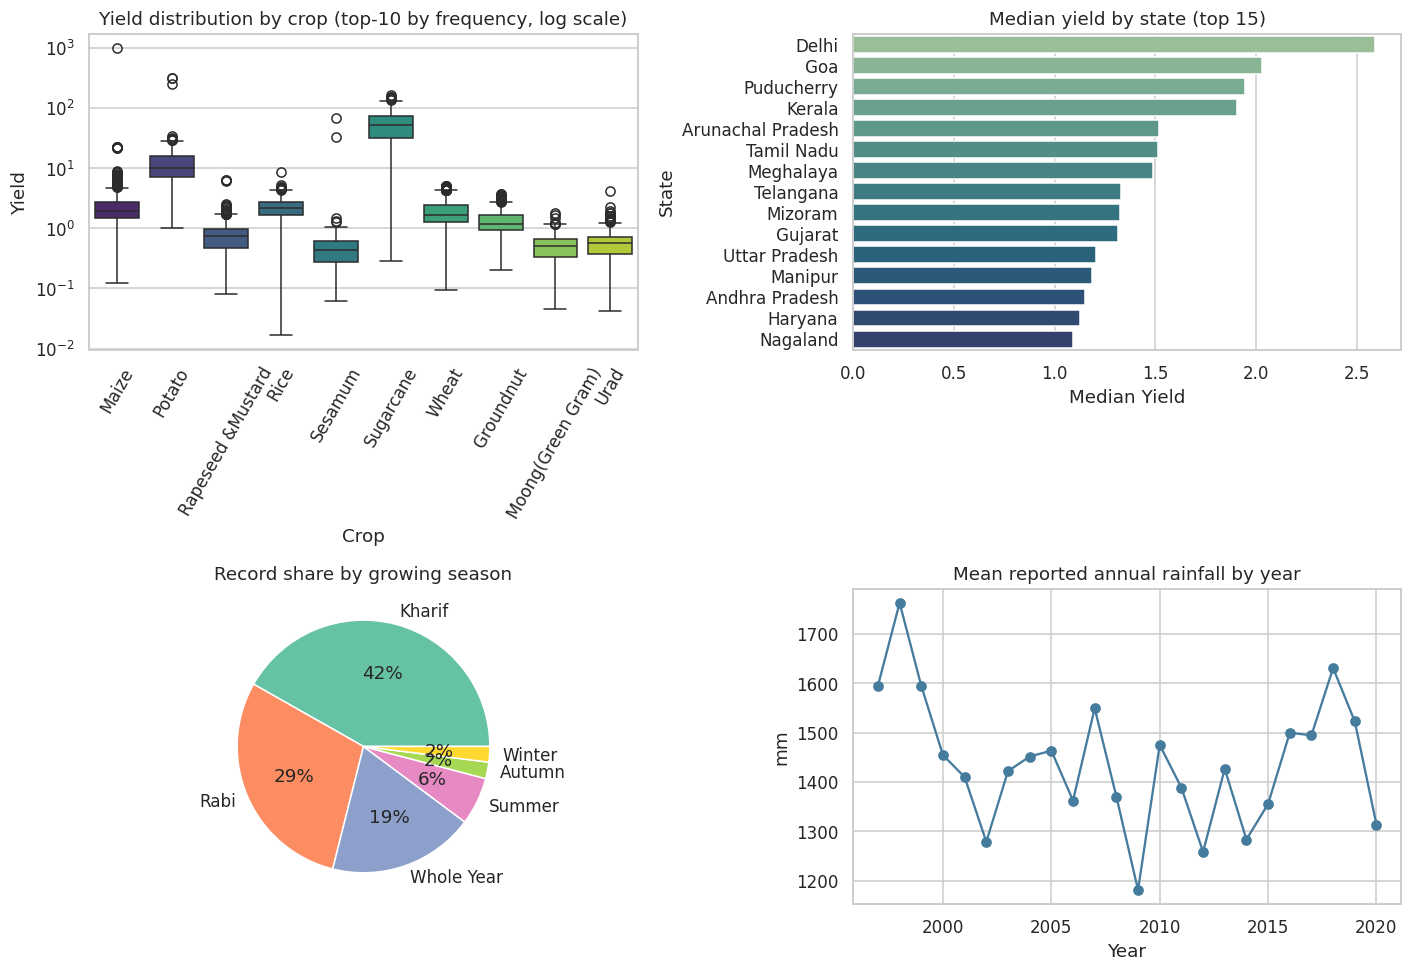

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

top_crops = df['Crop'].value_counts().head(10).index
sns.boxplot(data=df[df['Crop'].isin(top_crops)], x='Crop', y='Yield', ax=axes[0,0], palette='viridis')
axes[0,0].set_yscale('log'); axes[0,0].tick_params(axis='x', rotation=60)
axes[0,0].set_title('Yield distribution by crop (top-10 by frequency, log scale)')

state_yield = df.groupby('State')['Yield'].median().sort_values(ascending=False).head(15)
sns.barplot(x=state_yield.values, y=state_yield.index, ax=axes[0,1], palette='crest')
axes[0,1].set_title('Median yield by state (top 15)'); axes[0,1].set_xlabel('Median Yield')

season_counts = df['Season'].value_counts()
axes[1,0].pie(season_counts.values, labels=season_counts.index, autopct='%1.0f%%',
              colors=sns.color_palette('Set2'))
axes[1,0].set_title('Record share by growing season')

yearly = df.groupby('Crop_Year')['Annual_Rainfall'].mean()
axes[1,1].plot(yearly.index, yearly.values, marker='o', color='#457b9d')
axes[1,1].set_title('Mean reported annual rainfall by year')
axes[1,1].set_xlabel('Year'); axes[1,1].set_ylabel('mm')

plt.tight_layout(); plt.show()

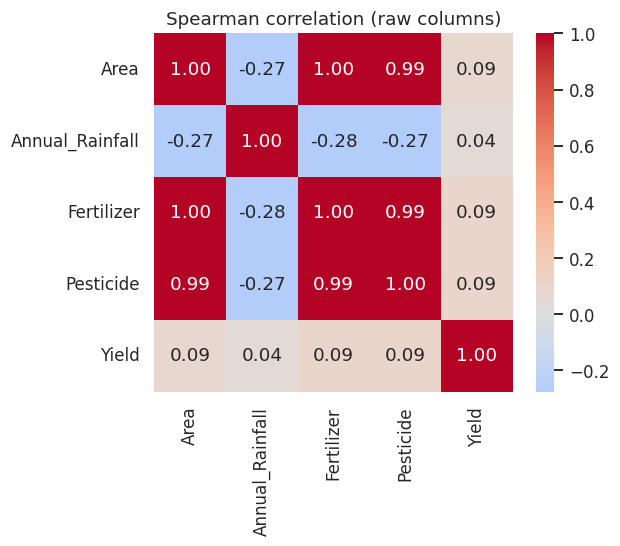

In [10]:
num_cols = ['Area', 'Annual_Rainfall', 'Fertilizer', 'Pesticide', 'Yield']
corr = df[num_cols].corr(method='spearman')
plt.figure(figsize=(6, 5))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, square=True)
plt.title("Spearman correlation (raw columns)")
plt.tight_layout(); plt.show()

## 6. Cross-Crop Scale Heterogeneity and Target Transform <a id='6'></a>

Median yield differs by several orders of magnitude across crops (Coconut is recorded in nuts/ha). The model
target is therefore log1p(Yield), and crop identity is kept as a categorical predictor.

Top 5 crops by median yield magnitude:
Crop
Coconut      8706.411724
Sugarcane      53.158158
Banana         17.956522
Tapioca        11.137525
Potato         10.178750
Name: Yield, dtype: float64

Bottom 5:
Crop
Sesamum       0.439000
Moth          0.437545
Horse-gram    0.428333
Niger seed    0.359762
Cardamom      0.078000
Name: Yield, dtype: float64

Ratio of largest to smallest crop-median yield: 111,621x

We address this with (i) a log1p(Yield) modeling target, which compresses this multi-order-of-
magnitude spread, and (ii) keeping Crop as an explicit categorical predictor in every model, so
that crop identity itself can absorb the unit/scale differences rather than forcing a single
global numeric relationship across incompatible units.


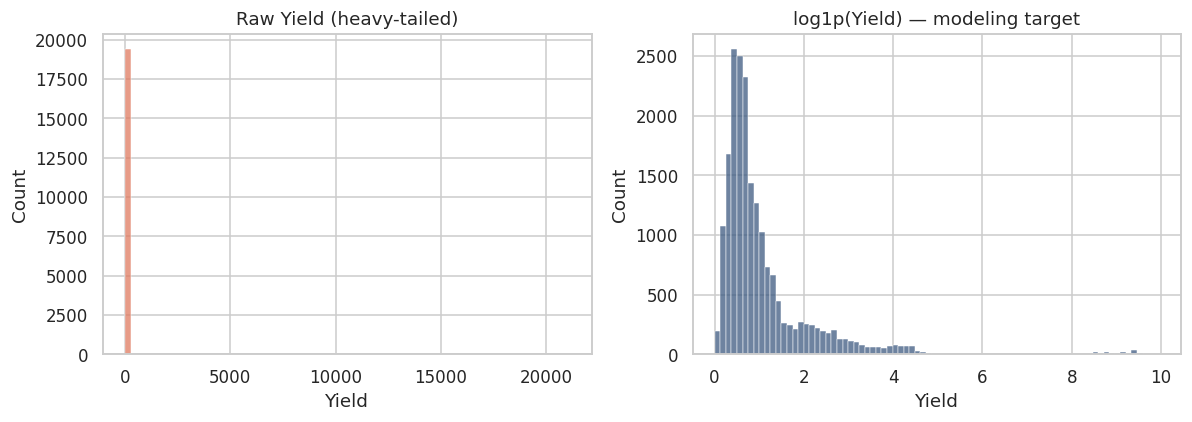

In [11]:
crop_scale = df.groupby('Crop')['Yield'].median().sort_values(ascending=False)
print("Top 5 crops by median yield magnitude:")
print(crop_scale.head(5))
print("\nBottom 5:")
print(crop_scale.tail(5))
print(f"\nRatio of largest to smallest crop-median yield: {crop_scale.iloc[0] / crop_scale.iloc[-1]:,.0f}x")
print()
print("We address this with (i) a log1p(Yield) modeling target, which compresses this multi-order-of-")
print("magnitude spread, and (ii) keeping Crop as an explicit categorical predictor in every model, so")
print("that crop identity itself can absorb the unit/scale differences rather than forcing a single")
print("global numeric relationship across incompatible units.")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(df['Yield'], bins=80, ax=axes[0], color='#e07a5f'); axes[0].set_title('Raw Yield (heavy-tailed)')
sns.histplot(np.log1p(df['Yield']), bins=80, ax=axes[1], color='#3d5a80'); axes[1].set_title('log1p(Yield) — modeling target')
plt.tight_layout(); plt.show()

## 7. Feature Engineering <a id='7'></a>

Builds the feature set from the cleaned table on every run, so re-running the cell is safe.

| Feature | Definition |
|---|---|
| `Area_log` | log1p(Area) |
| `Fertilizer_per_ha`, `Pesticide_per_ha` | Fertilizer / Area, Pesticide / Area (state × year intensity) |
| `Rainfall_x_Fert` | Annual_Rainfall × Fertilizer_per_ha |
| `Yield_lag1` | Yield of the previous observation of the same (State, Crop, Season) series |
| `Yield_rollmean3` | Mean of up to three previous observations of the series (current year excluded) |
| `Crop_Year`, `Annual_Rainfall` | as recorded |
| `Crop`, `Season`, `State` | one-hot encoded |

The first observation of each series has no lag and is dropped. Target: `Yield_log` = log1p(Yield).

In [12]:
df = df_clean.copy()
df['Fertilizer_per_ha'] = df['Fertilizer'] / df['Area']
df['Pesticide_per_ha']  = df['Pesticide']  / df['Area']
df = df.sort_values(['State', 'Crop', 'Season', 'Crop_Year']).reset_index(drop=True)

df['Series']            = df['State'] + ' | ' + df['Crop'] + ' | ' + df['Season']
df['Area_log']          = np.log1p(df['Area'])
df['Rainfall_x_Fert']   = df['Annual_Rainfall'] * df['Fertilizer_per_ha']

grp = df.groupby('Series')
df['Yield_lag1']        = grp['Yield'].shift(1)
df['Lag_year']          = grp['Crop_Year'].shift(1)
df['Yield_rollmean3']   = grp['Yield'].transform(lambda s: s.shift(1).rolling(3, min_periods=1).mean())

n_before = len(df)
df = df.dropna(subset=['Yield_lag1']).reset_index(drop=True)
df['Lag_gap_years'] = (df['Crop_Year'] - df['Lag_year']).astype(int)
assert (df['Lag_year'] < df['Crop_Year']).all(), 'lag must come from a strictly earlier year'
print(f"Rows with a valid causal lag feature: {len(df)} / {n_before} ({len(df)/n_before:.1%}) retained.")
print(f"Share of rows whose previous observation is exactly one year earlier: {(df['Lag_gap_years']==1).mean():.1%}")

df['Yield_log'] = np.log1p(df['Yield'])

NUM_FEATS = ['Crop_Year', 'Area_log', 'Annual_Rainfall', 'Fertilizer_per_ha',
             'Pesticide_per_ha', 'Rainfall_x_Fert', 'Yield_lag1', 'Yield_rollmean3']
CAT_FEATS = ['Crop', 'Season', 'State']
TARGET    = 'Yield_log'

print(f"\nFinal leakage-free feature set ({len(NUM_FEATS)} numeric + {len(CAT_FEATS)} categorical):")
print(' Numeric:    ', NUM_FEATS)
print(' Categorical:', CAT_FEATS)

df[NUM_FEATS + CAT_FEATS + ['Yield', TARGET]].to_csv('df_model.csv', index=False)
df.head()

Rows with a valid causal lag feature: 17920 / 19577 (91.5%) retained.
Share of rows whose previous observation is exactly one year earlier: 94.3%

Final leakage-free feature set (8 numeric + 3 categorical):
 Numeric:     ['Crop_Year', 'Area_log', 'Annual_Rainfall', 'Fertilizer_per_ha', 'Pesticide_per_ha', 'Rainfall_x_Fert', 'Yield_lag1', 'Yield_rollmean3']
 Categorical: ['Crop', 'Season', 'State']


,Crop,Crop_Year,Season,State,Area,Production,Annual_Rainfall,Fertilizer,Pesticide,Yield,Fertilizer_per_ha,Pesticide_per_ha,Series,Area_log,Rainfall_x_Fert,Yield_lag1,Lag_year,Yield_rollmean3,Lag_gap_years,Yield_log
0,Arecanut,2013,Kharif,Andhra Pradesh,476.0,255,1062.3,68777.24,128.52,1.7050,144.49,0.27,Andhra Pradesh | Arecanut | Kharif,6.167516,153491.727,1.453333,2012.0,1.453333,1,0.995102
1,Arecanut,2014,Kharif,Andhra Pradesh,483.0,338,687.6,72913.68,159.39,1.7750,150.96,0.33,Andhra Pradesh | Arecanut | Kharif,6.182085,103800.096,1.705000,2013.0,1.579167,1,1.020651
2,Arecanut,2015,Kharif,Andhra Pradesh,516.0,1795,940.7,81481.56,170.28,3.3200,157.91,0.33,Andhra Pradesh | Arecanut | Kharif,6.248043,148545.937,1.775000,2014.0,1.644444,1,1.463255
3,Arecanut,2016,Kharif,Andhra Pradesh,564.0,2367,890.0,86433.00,197.40,3.9125,153.25,0.35,Andhra Pradesh | Arecanut | Kharif,6.336826,136392.500,3.320000,2015.0,2.266667,1,1.591783
4,Arecanut,2017,Kharif,Andhra Pradesh,697.0,4369,868.2,109735.68,264.86,5.5825,157.44,0.38,Andhra Pradesh | Arecanut | Kharif,6.548219,136689.408,3.912500,2016.0,3.002500,1,1.884415


## 8. Baselines and Skill Score <a id='8'></a>

Creates the random 80/20 split used in Sections 8–15 and evaluates three trivial baselines on its test set:
global mean, crop-wise mean (from training rows), and persistence (`Yield_lag1`). Skill is defined as
1 − RMSE_model / RMSE_persistence.

In [13]:
X_all = df[NUM_FEATS + CAT_FEATS]
y_all = df[TARGET]
y_all_real = df['Yield']

X_train, X_test, y_train, y_test, y_train_real, y_test_real = train_test_split(
    X_all, y_all, y_all_real, test_size=0.2, random_state=RANDOM_STATE)

def rmse(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred))

baselines = {}
baselines['Global mean']       = np.full(len(y_test_real), y_train_real.mean())
crop_mean_map                   = df.loc[y_train.index, ['Crop']].assign(Yield=y_train_real).groupby('Crop')['Yield'].mean()
baselines['Crop-wise mean']    = df.loc[y_test.index, 'Crop'].map(crop_mean_map).fillna(y_train_real.mean()).values
baselines['Persistence (lag1)'] = df.loc[y_test.index, 'Yield_lag1'].values

baseline_rmse = {name: rmse(y_test_real, pred) for name, pred in baselines.items()}
for name, val in baseline_rmse.items():
    print(f"  Baseline RMSE — {name:22s}: {val:8.3f}")

BEST_BASELINE_RMSE = min(baseline_rmse.values())
print(f"\nStrongest baseline: {min(baseline_rmse, key=baseline_rmse.get)} "
      f"(RMSE={BEST_BASELINE_RMSE:.3f}). Every subsequent model's skill score below is "
      f"1 - RMSE_model / {BEST_BASELINE_RMSE:.3f}.")

  Baseline RMSE — Global mean           :  895.762
  Baseline RMSE — Crop-wise mean        :  343.721
  Baseline RMSE — Persistence (lag1)    :  113.173

Strongest baseline: Persistence (lag1) (RMSE=113.173). Every subsequent model's skill score below is 1 - RMSE_model / 113.173.


## 9. Random vs Temporal vs Spatial Split <a id='9'></a>

Fits one fixed LightGBM configuration under three regimes:

- **Random:** row-level 80/20.
- **Temporal:** train ≤ 2015, test 2016–2020.
- **Spatial:** train on 24 states, test on 6 states drawn with `RandomState(42)`.

Metrics are reported on both scales, together with the number of Coconut test rows. Raw-scale RMSE depends
mainly on how many Coconut rows a test set contains, so only the `_log` columns are comparable across regimes.

Held-out states (seed 42): Haryana, Himachal Pradesh, Maharashtra, Meghalaya, Sikkim, Uttar Pradesh


,n,n_coconut,R2_raw,RMSE_raw,R2_raw_exCoconut,RMSE_raw_exCoconut,R2_log,RMSE_log,MdAPE_%
Random split,3584.0,32.0,0.9680,160.2506,0.8109,5.4462,0.9737,0.1867,9.8510
Temporal split (train<=2015),4159.0,32.0,0.9646,162.6795,0.7432,7.0306,0.9694,0.1959,11.3346
Spatial split (6 unseen states),3407.0,0.0,0.8455,3.8598,0.8455,3.8598,0.9358,0.2046,11.0911


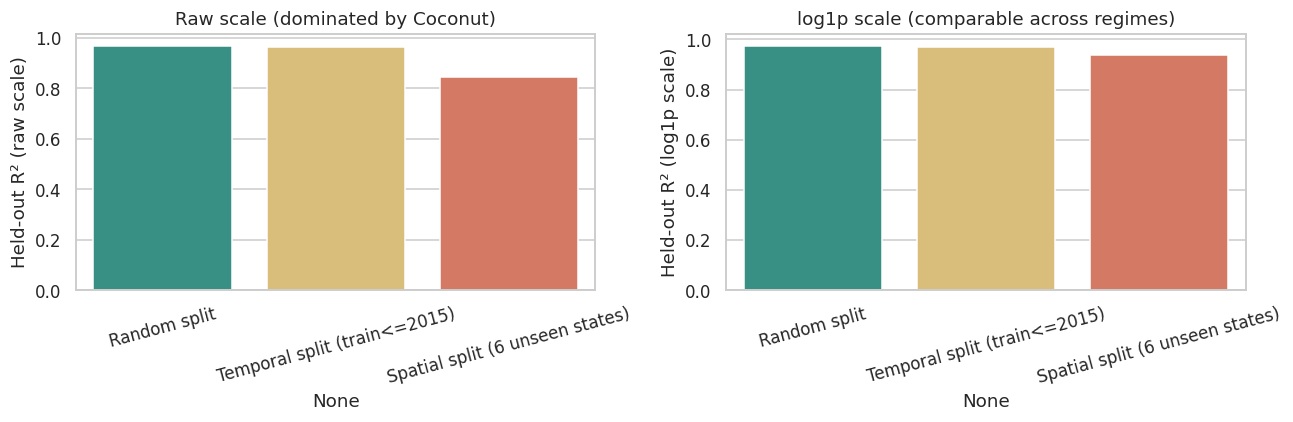


Generalization gap on the comparable log scale (random R² minus 6-unseen-state R²): 0.0379
Raw-scale RMSE differs across regimes mainly because of Coconut (column n_coconut), not because of
a scale mismatch: every number in this table is computed after back-transforming to raw Yield, except
the *_log columns.


In [14]:
def fit_eval(Xtr, ytr, Xte, yte_real, crops_te):
    pre = ColumnTransformer([('num', 'passthrough', NUM_FEATS),
                              ('cat', OneHotEncoder(handle_unknown='ignore'), CAT_FEATS)])
    pipe = Pipeline([('pre', pre),
                      ('mdl', lgb.LGBMRegressor(n_estimators=250, max_depth=6, learning_rate=0.08,
                                                 verbosity=-1, random_state=RANDOM_STATE))])
    pipe.fit(Xtr, ytr)
    pred_real = np.expm1(pipe.predict(Xte))
    return metric_suite(yte_real, pred_real, crops_te)

split_results = {}

Xtr, Xte, ytr, yte, _, yte_r = train_test_split(X_all, y_all, y_all_real, test_size=0.2, random_state=RANDOM_STATE)
split_results['Random split'] = fit_eval(Xtr, ytr, Xte, yte_r, df.loc[Xte.index, 'Crop'])

train_mask = df['Crop_Year'] <= 2015
split_results['Temporal split (train<=2015)'] = fit_eval(
    X_all[train_mask], y_all[train_mask], X_all[~train_mask], y_all_real[~train_mask], df.loc[~train_mask, 'Crop'])

rng = np.random.RandomState(RANDOM_STATE)
held_out_states = rng.choice(df['State'].unique(), size=6, replace=False)
state_mask = df['State'].isin(held_out_states)
split_results['Spatial split (6 unseen states)'] = fit_eval(
    X_all[~state_mask], y_all[~state_mask], X_all[state_mask], y_all_real[state_mask], df.loc[state_mask, 'Crop'])
print('Held-out states (seed 42):', ', '.join(sorted(held_out_states)))

split_df = pd.DataFrame(split_results).T
show_cols = ['n', 'n_coconut', 'R2_raw', 'RMSE_raw', 'R2_raw_exCoconut', 'RMSE_raw_exCoconut', 'R2_log', 'RMSE_log', 'MdAPE_%']
display(split_df[show_cols].round(4))

fig, axes = plt.subplots(1, 2, figsize=(12,4))
sns.barplot(x=split_df.index, y=split_df['R2_raw'], palette=['#2a9d8f','#e9c46a','#e76f51'], ax=axes[0])
axes[0].set_ylabel('Held-out R² (raw scale)'); axes[0].set_title('Raw scale (dominated by Coconut)')
sns.barplot(x=split_df.index, y=split_df['R2_log'], palette=['#2a9d8f','#e9c46a','#e76f51'], ax=axes[1])
axes[1].set_ylabel('Held-out R² (log1p scale)'); axes[1].set_title('log1p scale (comparable across regimes)')
for a in axes: a.tick_params(axis='x', rotation=15)
plt.tight_layout(); plt.show()

gap = split_df['R2_log']['Random split'] - split_df['R2_log']['Spatial split (6 unseen states)']
print(f"\nGeneralization gap on the comparable log scale (random R² minus 6-unseen-state R²): {gap:.4f}")
print("Raw-scale RMSE differs across regimes mainly because of Coconut (column n_coconut), not because of")
print("a scale mismatch: every number in this table is computed after back-transforming to raw Yield, except")
print("the *_log columns.")

## 10. 12-Model Benchmark <a id='10'></a>

Ridge, Lasso, KNN, SVR, MLP, Decision Tree, Random Forest, Extra Trees, Gradient Boosting, XGBoost, LightGBM and
CatBoost, with fixed hyperparameters and identical preprocessing, on the random split from Section 8. SVR is
trained on a 4,000-row subsample. Skill is reported against persistence and against the global mean. The
temporal-split version of this benchmark is in Section R2.2.

In [15]:
pre_tree = ColumnTransformer([('num', 'passthrough', NUM_FEATS),
                               ('cat', OneHotEncoder(handle_unknown='ignore'), CAT_FEATS)])
pre_lin  = ColumnTransformer([('num', StandardScaler(), NUM_FEATS),
                               ('cat', OneHotEncoder(handle_unknown='ignore'), CAT_FEATS)])

MODEL_SPECS = [
    ('Ridge',         pre_lin,  Ridge(alpha=1.0)),
    ('Lasso',         pre_lin,  Lasso(alpha=0.001)),
    ('KNN',           pre_lin,  KNeighborsRegressor(n_neighbors=7)),
    ('SVR',           pre_lin,  SVR(C=5, epsilon=0.05)),
    ('MLP',           pre_lin,  MLPRegressor(hidden_layer_sizes=(64,32), max_iter=300,
                                              random_state=RANDOM_STATE, early_stopping=True)),
    ('DecisionTree',  pre_tree, DecisionTreeRegressor(max_depth=10, random_state=RANDOM_STATE)),
    ('RandomForest',  pre_tree, RandomForestRegressor(n_estimators=100, max_depth=13,
                                                        n_jobs=1, random_state=RANDOM_STATE)),
    ('ExtraTrees',    pre_tree, ExtraTreesRegressor(n_estimators=100, max_depth=13,
                                                      n_jobs=1, random_state=RANDOM_STATE)),
    ('GradientBoost', pre_tree, GradientBoostingRegressor(n_estimators=150, max_depth=4,
                                                            random_state=RANDOM_STATE)),
    ('XGBoost',       pre_tree, xgb.XGBRegressor(n_estimators=250, max_depth=6, learning_rate=0.08,
                                                   n_jobs=1, random_state=RANDOM_STATE, verbosity=0)),
    ('LightGBM',      pre_tree, lgb.LGBMRegressor(n_estimators=250, max_depth=6, learning_rate=0.08,
                                                    n_jobs=1, random_state=RANDOM_STATE, verbosity=-1)),
    ('CatBoost',      pre_tree, CatBoostRegressor(iterations=250, depth=6, learning_rate=0.08,
                                                    random_state=RANDOM_STATE, verbose=0)),
]

bench_rows = []
fitted_pipes = {}
SVR_SUBSAMPLE = 4000
for name, pre, mdl in MODEL_SPECS:
    t0 = time.time()
    pipe = Pipeline([('pre', clone(pre)), ('mdl', clone(mdl))])
    if name == 'SVR' and len(X_train) > SVR_SUBSAMPLE:
        sub_idx = X_train.sample(n=SVR_SUBSAMPLE, random_state=RANDOM_STATE).index
        pipe.fit(X_train.loc[sub_idx], y_train.loc[sub_idx])
    else:
        pipe.fit(X_train, y_train)
    pred_real = np.expm1(pipe.predict(X_test))
    r2  = r2_score(y_test_real, pred_real)
    mae = mean_absolute_error(y_test_real, pred_real)
    rm  = rmse(y_test_real, pred_real)
    bench_rows.append({'Model': name, 'R2': r2, 'MAE': mae, 'RMSE': rm,
                        'R2_log': r2_score(np.log1p(y_test_real), np.log1p(np.clip(pred_real, 0, None))),
                        'Skill vs baseline': 1 - rm / BEST_BASELINE_RMSE,
                        'Skill vs global mean': 1 - rm / baseline_rmse['Global mean'],
                        'Fit+predict (s)': time.time()-t0})
    fitted_pipes[name] = pipe

bench_df = pd.DataFrame(bench_rows).sort_values('RMSE').reset_index(drop=True)
display(bench_df.style.format({'R2':'{:.4f}','R2_log':'{:.4f}','MAE':'{:.3f}','RMSE':'{:.3f}',
                                'Skill vs baseline':'{:.1%}','Skill vs global mean':'{:.1%}','Fit+predict (s)':'{:.1f}'})
                       .background_gradient(subset=['R2'], cmap='Greens'))
print("'Skill vs baseline' = 1 - RMSE/RMSE_persistence. A NEGATIVE value means the model is worse than")
print("'repeat last year's yield', NOT worse than the mean. Every model has positive skill vs the global mean.")

,Model,R2,MAE,RMSE,R2_log,Skill vs baseline,Skill vs global mean,Fit+predict (s)
0,ExtraTrees,0.9817,8.522,121.144,0.9728,-7.0%,86.5%,12.4
1,RandomForest,0.9791,9.079,129.609,0.9731,-14.5%,85.5%,33.6
2,KNN,0.9770,10.622,135.890,0.8768,-20.1%,84.8%,3.2
3,DecisionTree,0.9753,10.221,140.806,0.9639,-24.4%,84.3%,0.4
4,GradientBoost,0.9745,9.730,143.111,0.9738,-26.5%,84.0%,8.6
5,XGBoost,0.9715,9.744,151.269,0.9730,-33.7%,83.1%,1.0
6,LightGBM,0.9680,11.465,160.251,0.9737,-41.6%,82.1%,0.4
7,Ridge,0.9442,17.532,211.583,0.8924,-87.0%,76.4%,0.3
8,CatBoost,0.9413,16.048,217.040,0.9752,-91.8%,75.8%,1.5
9,MLP,0.9287,16.773,239.217,0.9695,-111.4%,73.3%,7.5


'Skill vs baseline' = 1 - RMSE/RMSE_persistence. A NEGATIVE value means the model is worse than
'repeat last year's yield', NOT worse than the mean. Every model has positive skill vs the global mean.


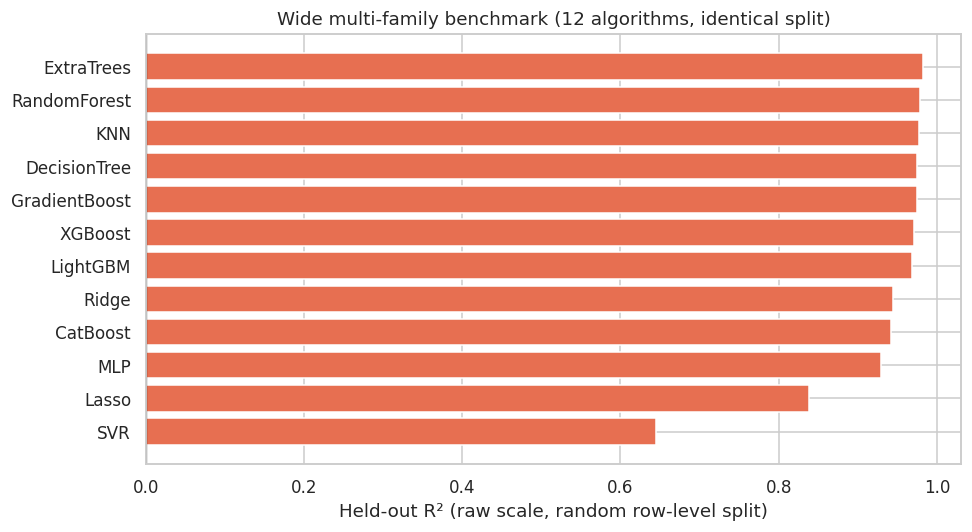

Best single model by RMSE: ExtraTrees  (R2=0.9817, skill over persistence = -7.0%)


In [16]:
fig, ax = plt.subplots(figsize=(9,5))
plot_df = bench_df.sort_values('R2')
colors = ['#e76f51' if s < 0 else '#e9c46a' if s < 0.1 else '#2a9d8f' for s in plot_df['Skill vs baseline']]
ax.barh(plot_df['Model'], plot_df['R2'], color=colors)
ax.set_xlabel('Held-out R² (raw scale, random row-level split)')
ax.set_title(f'Wide multi-family benchmark ({len(plot_df)} algorithms, identical split)')
ax.axvline(0, color='k', lw=0.8)
plt.tight_layout(); plt.show()

BEST_MODEL_NAME = bench_df.iloc[0]['Model']
print(f"Best single model by RMSE: {BEST_MODEL_NAME}  "
      f"(R2={bench_df.iloc[0]['R2']:.4f}, skill over persistence = "
      f"{bench_df.iloc[0]['Skill vs baseline']:.1%})")

## 11. Bayesian Hyperparameter Optimization <a id='11'></a>

Optuna TPE search (30 trials, seed 42) for LightGBM. Each trial is fitted on 80% of the training set and scored by
raw-scale RMSE on the remaining 20%. The test set is not used. The tuned model is refitted on the full training
set and evaluated once on the test set. Section R4 repeats the search for five model families on temporal
validation years.

In [17]:
X_tr2, X_val, y_tr2, y_val, _, y_val_real = train_test_split(
    X_train, y_train, y_train_real, test_size=0.2, random_state=1)

def objective(trial):
    params = {
        'n_estimators':  trial.suggest_int('n_estimators', 100, 400),
        'max_depth':     trial.suggest_int('max_depth', 3, 10),
        'learning_rate': trial.suggest_float('learning_rate', 0.02, 0.25, log=True),
        'num_leaves':    trial.suggest_int('num_leaves', 15, 90),
        'subsample':     trial.suggest_float('subsample', 0.6, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 1.0),
    }
    pipe = Pipeline([('pre', pre_tree),
                      ('mdl', lgb.LGBMRegressor(**params, verbosity=-1, random_state=RANDOM_STATE))])
    pipe.fit(X_tr2, y_tr2)
    pred = np.expm1(pipe.predict(X_val))
    return rmse(y_val_real, pred)

study = optuna.create_study(direction='minimize', sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))
study.optimize(objective, n_trials=30, show_progress_bar=False)

print('Best trial RMSE:', round(study.best_value, 4))
print('Best hyperparameters:', study.best_params)

Best trial RMSE: 120.9798
Best hyperparameters: {'n_estimators': 100, 'max_depth': 6, 'learning_rate': 0.08557135914867466, 'num_leaves': 50, 'subsample': 0.6416082248087623, 'colsample_bytree': 0.6702860655951727}


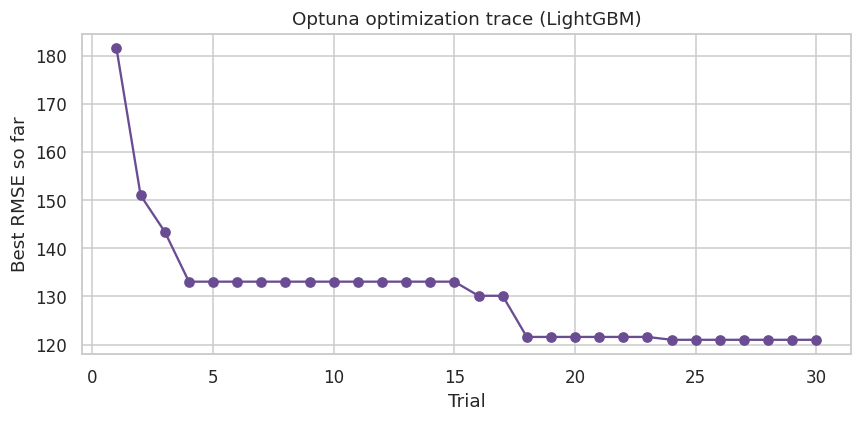


Tuned LightGBM on held-out test set: R2=0.9694, RMSE=156.739 (vs. untuned LightGBM R2=0.9680)


In [18]:
fig, ax = plt.subplots(figsize=(8,4))
trial_vals = [t.value for t in study.trials]
ax.plot(range(1, len(trial_vals)+1), np.minimum.accumulate(trial_vals), marker='o', color='#6a4c93')
ax.set_xlabel('Trial'); ax.set_ylabel('Best RMSE so far'); ax.set_title('Optuna optimization trace (LightGBM)')
plt.tight_layout(); plt.show()

tuned_lgb = lgb.LGBMRegressor(**study.best_params, verbosity=-1, random_state=RANDOM_STATE)
tuned_pipe = Pipeline([('pre', pre_tree), ('mdl', tuned_lgb)])
tuned_pipe.fit(X_train, y_train)
pred_tuned = np.expm1(tuned_pipe.predict(X_test))
r2_tuned, rmse_tuned = r2_score(y_test_real, pred_tuned), rmse(y_test_real, pred_tuned)
print(f"\nTuned LightGBM on held-out test set: R2={r2_tuned:.4f}, RMSE={rmse_tuned:.3f} "
      f"(vs. untuned LightGBM R2={bench_df.set_index('Model').loc['LightGBM','R2']:.4f})")
fitted_pipes['LightGBM (tuned)'] = tuned_pipe

## 12. Stacking Ensemble <a id='12'></a>

Base learners: LightGBM, XGBoost and Random Forest. Meta-learner: Ridge, trained on 3-fold out-of-fold predictions
generated inside the training set by `StackingRegressor(cv=3)`. Section R5 rebuilds the stack explicitly with
series-grouped folds and tuned base learners.

In [19]:
base_learners = [
    ('lgb', lgb.LGBMRegressor(n_estimators=250, max_depth=6, learning_rate=0.08,
                               verbosity=-1, random_state=RANDOM_STATE)),
    ('xgb', xgb.XGBRegressor(n_estimators=250, max_depth=6, learning_rate=0.08,
                              verbosity=0, random_state=RANDOM_STATE)),
    ('rf',  RandomForestRegressor(n_estimators=120, max_depth=12, random_state=RANDOM_STATE)),
]
stack = StackingRegressor(estimators=base_learners, final_estimator=Ridge(alpha=1.0), cv=3, n_jobs=1)
stack_pipe = Pipeline([('pre', pre_tree), ('mdl', stack)])
stack_pipe.fit(X_train, y_train)
pred_stack = np.expm1(stack_pipe.predict(X_test))
r2_stack, rmse_stack = r2_score(y_test_real, pred_stack), rmse(y_test_real, pred_stack)
fitted_pipes['Stacking ensemble'] = stack_pipe

print(f"Stacking ensemble: R2={r2_stack:.4f}, RMSE={rmse_stack:.3f}")
print(f"Tuned LightGBM:     R2={r2_tuned:.4f}, RMSE={rmse_tuned:.3f}")
print(f"Best single model ({BEST_MODEL_NAME}): R2={bench_df.iloc[0]['R2']:.4f}, "
      f"RMSE={bench_df.iloc[0]['RMSE']:.3f}")

Stacking ensemble: R2=0.9703, RMSE=154.335
Tuned LightGBM:     R2=0.9694, RMSE=156.739
Best single model (ExtraTrees): R2=0.9817, RMSE=121.144


## 13. Paired Significance Test (10-Fold CV) <a id='13'></a>

- **Paired observations:** the 10 test folds of a shuffled row-level `KFold(n_splits=10, random_state=42)`.
- **Models:** Extra Trees, tuned LightGBM, XGBoost.
- **Metric:** raw-scale RMSE per fold.
- **Test:** two-sided Wilcoxon signed-rank (exact), H1: median paired difference ≠ 0.
- **Correction:** Holm–Bonferroni over the 3 pairs, α = 0.05.

Row-level folds share series with training data (Section R1.3). The leakage-safe rolling-origin test is in
Section R6.

In [20]:
from scipy.stats import wilcoxon

kf = KFold(n_splits=10, shuffle=True, random_state=RANDOM_STATE)
candidates = {
    'ExtraTrees':        Pipeline([('pre', pre_tree), ('mdl', ExtraTreesRegressor(
                              n_estimators=100, max_depth=13, random_state=RANDOM_STATE, n_jobs=1))]),
    'LightGBM (tuned)':  Pipeline([('pre', pre_tree), ('mdl', lgb.LGBMRegressor(
                              **study.best_params, verbosity=-1, random_state=RANDOM_STATE))]),
    'XGBoost':           Pipeline([('pre', pre_tree), ('mdl', xgb.XGBRegressor(
                              n_estimators=250, max_depth=6, learning_rate=0.08,
                              verbosity=0, random_state=RANDOM_STATE, n_jobs=1))]),
}

fold_rmse = {name: [] for name in candidates}
for tr_idx, te_idx in kf.split(X_all):
    Xtr_f, Xte_f = X_all.iloc[tr_idx], X_all.iloc[te_idx]
    ytr_f = y_all.iloc[tr_idx]
    yte_f_real = y_all_real.iloc[te_idx]
    for name, pipe in candidates.items():
        pipe.fit(Xtr_f, ytr_f)
        pred = np.expm1(pipe.predict(Xte_f))
        fold_rmse[name].append(rmse(yte_f_real, pred))

fold_df = pd.DataFrame(fold_rmse)
display(fold_df.agg(['mean', 'std']))

pairs = [('ExtraTrees', 'LightGBM (tuned)'), ('ExtraTrees', 'XGBoost'),
         ('LightGBM (tuned)', 'XGBoost')]
raw_p = [wilcoxon(fold_df[a], fold_df[b], alternative='two-sided').pvalue for a, b in pairs]
adj_p = holm(raw_p)
print("\nPaired two-sided Wilcoxon signed-rank on fold-level raw RMSE (n = 10 folds), Holm-corrected:")
for (a, b), p, pa in zip(pairs, raw_p, adj_p):
    print(f"  {a:18s} vs {b:18s}: p_raw = {p:.4f}, p_Holm = {pa:.4f} -> "
          f"{'SIGNIFICANT' if pa < 0.05 else 'not significant'} at alpha = 0.05")

,ExtraTrees,LightGBM (tuned),XGBoost
mean,119.526867,140.597792,154.860450
std,47.981319,48.760180,61.056653



Paired two-sided Wilcoxon signed-rank on fold-level raw RMSE (n = 10 folds), Holm-corrected:
  ExtraTrees         vs LightGBM (tuned)  : p_raw = 0.0273, p_Holm = 0.0547 -> not significant at alpha = 0.05
  ExtraTrees         vs XGBoost           : p_raw = 0.0098, p_Holm = 0.0293 -> SIGNIFICANT at alpha = 0.05
  LightGBM (tuned)   vs XGBoost           : p_raw = 0.2754, p_Holm = 0.2754 -> not significant at alpha = 0.05


## 14. SHAP Global Importance and Interactions <a id='14'></a>

Exact TreeSHAP on the tuned LightGBM from Section 11, computed for 400 test rows. Shows the beeswarm summary, the
top features by mean |SHAP|, and pairwise SHAP interaction strength among the numeric features (150 rows).

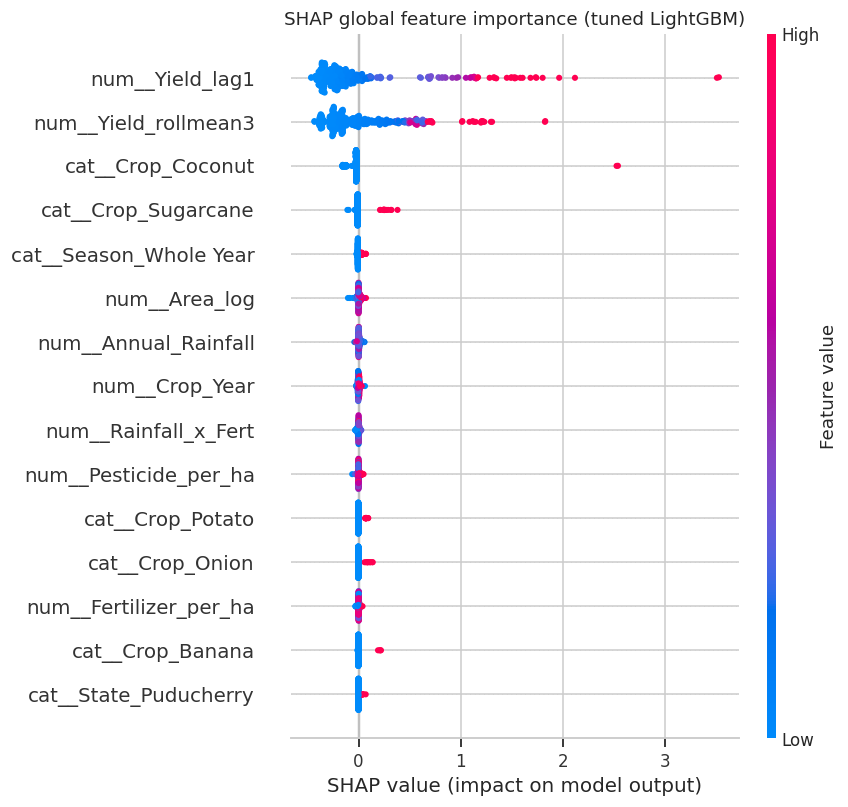

In [21]:
final_model = tuned_pipe.named_steps['mdl']
pre_fitted  = tuned_pipe.named_steps['pre']

X_test_sample = X_test.sample(n=min(400, len(X_test)), random_state=RANDOM_STATE)
X_test_t = pre_fitted.transform(X_test_sample)
feat_names = pre_fitted.get_feature_names_out()
if hasattr(X_test_t, 'toarray'):
    X_test_t = X_test_t.toarray()

explainer = shap.TreeExplainer(final_model)
shap_values = explainer.shap_values(X_test_t)

plt.figure()
shap.summary_plot(shap_values, X_test_t, feature_names=feat_names, show=False, max_display=15)
plt.title('SHAP global feature importance (tuned LightGBM)')
plt.tight_layout(); plt.show()

Top 10 features by mean |SHAP value|:
num__Yield_lag1           0.346984
num__Yield_rollmean3      0.281116
cat__Crop_Coconut         0.050070
cat__Crop_Sugarcane       0.017845
cat__Season_Whole Year    0.011208
num__Area_log             0.008948
num__Annual_Rainfall      0.005994
num__Crop_Year            0.005767
num__Rainfall_x_Fert      0.005253
num__Pesticide_per_ha     0.004922
dtype: float64


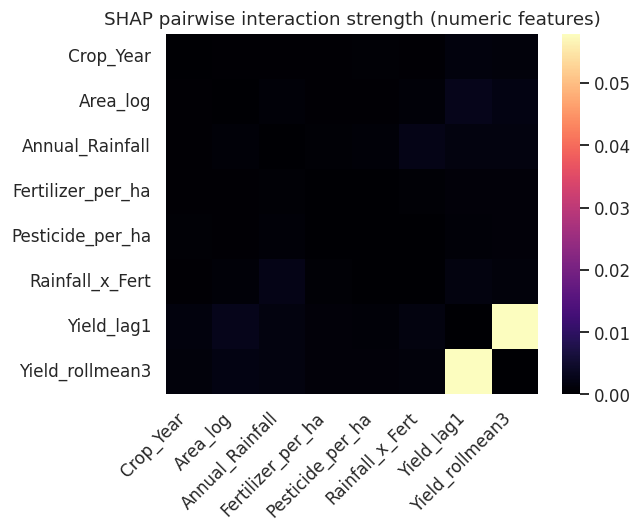

In [22]:
mean_abs_shap = pd.Series(np.abs(shap_values).mean(axis=0), index=feat_names).sort_values(ascending=False)
print("Top 10 features by mean |SHAP value|:")
print(mean_abs_shap.head(10))

X_inter = X_test_t[:150]
inter_vals = explainer.shap_interaction_values(X_inter)
inter_strength = np.abs(inter_vals).mean(axis=0)
np.fill_diagonal(inter_strength, 0)
top_num_idx = [i for i, n in enumerate(feat_names) if n.startswith('num__')]
sub_names = [feat_names[i].replace('num__','') for i in top_num_idx]
sub_matrix = inter_strength[np.ix_(top_num_idx, top_num_idx)]

plt.figure(figsize=(6,5))
sns.heatmap(sub_matrix, xticklabels=sub_names, yticklabels=sub_names, cmap='magma', annot=False)
plt.title('SHAP pairwise interaction strength (numeric features)')
plt.xticks(rotation=45, ha='right'); plt.tight_layout(); plt.show()

## 15. Split-Conformal Prediction Intervals <a id='15'></a>

The training set is split into a proper-training part (85%) and a calibration part (15%). Absolute raw-scale
residuals on the calibration part define a symmetric interval around each test prediction. The quantile is the
finite-sample conformal quantile, the ⌈(n+1)(1−α)⌉-th smallest score. Empirical coverage and interval width are
reported at 80%, 90% and 95%. Section R9 adds log-scale and crop-conditional intervals and evaluates them under
temporal and spatial shift.

In [23]:
X_tr3, X_cal, y_tr3, y_cal, _, y_cal_real = train_test_split(
    X_train, y_train, y_train_real, test_size=0.15, random_state=2)

conf_pipe = Pipeline([('pre', pre_tree),
                       ('mdl', lgb.LGBMRegressor(**study.best_params, verbosity=-1,
                                                  random_state=RANDOM_STATE))])
conf_pipe.fit(X_tr3, y_tr3)

cal_pred_real = np.expm1(conf_pipe.predict(X_cal))
cal_resid = np.abs(y_cal_real.values - cal_pred_real)

test_pred_real = np.expm1(conf_pipe.predict(X_test))

results_cov = []
for alpha in [0.20, 0.10, 0.05]:
    q = conformal_q(cal_resid, alpha)
    lower, upper = np.clip(test_pred_real - q, 0, None), test_pred_real + q
    coverage = np.mean((y_test_real.values >= lower) & (y_test_real.values <= upper))
    results_cov.append({'Target coverage': f'{1-alpha:.0%}', 'Empirical coverage': coverage,
                         'Mean interval width (raw)': np.mean(upper - lower),
                         'Median interval width (raw)': np.median(upper - lower)})

cov_df = pd.DataFrame(results_cov)
display(cov_df)
print("Note: with absolute raw-scale residuals the interval has the SAME width for every crop. That is too")
print("wide for low-yield pulses and too narrow for Coconut. Section R9 replaces it with scale-adaptive intervals.")

,Target coverage,Empirical coverage,Mean interval width (raw),Median interval width (raw)
0,80%,0.807199,0.990350,1.011238
1,90%,0.898438,2.272482,2.398053
2,95%,0.944475,4.958945,4.513461


Note: with absolute raw-scale residuals the interval has the SAME width for every crop. That is too
wide for low-yield pulses and too narrow for Coconut. Section R9 replaces it with scale-adaptive intervals.


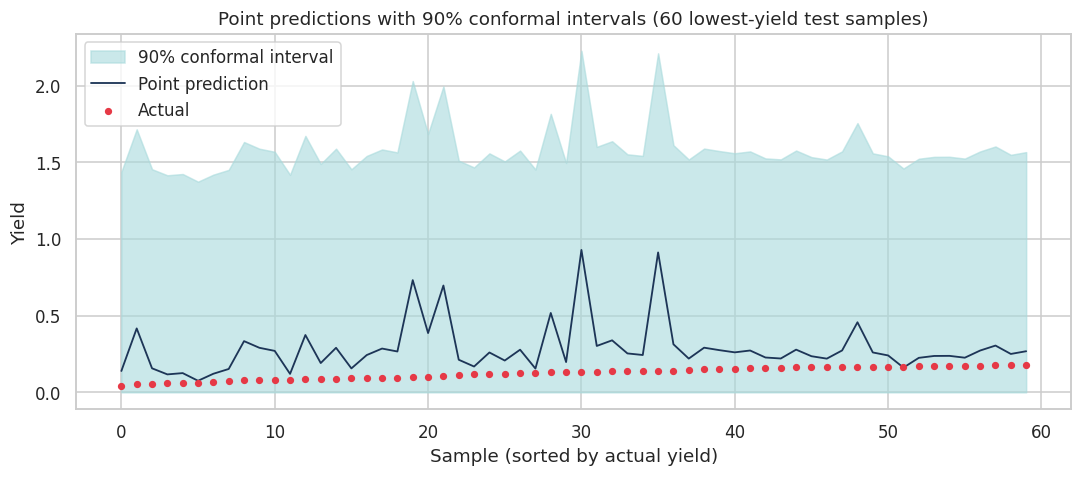

In [24]:
q90 = conformal_q(cal_resid, 0.10)
idx_plot = np.argsort(y_test_real.values)[:60]
plt.figure(figsize=(10,4.5))
plt.fill_between(range(60), np.clip(test_pred_real - q90, 0, None)[idx_plot], (test_pred_real + q90)[idx_plot],
                  color='#a8dadc', alpha=0.6, label='90% conformal interval')
plt.plot(range(60), test_pred_real[idx_plot], color='#1d3557', label='Point prediction', lw=1.2)
plt.scatter(range(60), y_test_real.values[idx_plot], color='#e63946', s=14, label='Actual', zorder=5)
plt.legend(); plt.title('Point predictions with 90% conformal intervals (60 lowest-yield test samples)')
plt.xlabel('Sample (sorted by actual yield)'); plt.ylabel('Yield')
plt.tight_layout(); plt.show()

## 16. Leave-States-Out and Leave-One-Crop-Out Transfer <a id='16'></a>

- **States:** `GroupKFold(10)` over the 30 states. Each fold holds out 2–4 entire states.
- **Crops:** leave-one-crop-out within 8 representative crops.

R² is reported on both scales. Section R2 adds 30-fold leave-one-state-out. Section R8 extends the crop analysis
to all crops and crop families and identifies the causes of failure.

In [25]:
gkf = GroupKFold(n_splits=10)
state_scores = []
for tr_idx, te_idx in gkf.split(X_all, y_all, groups=df['State']):
    p = Pipeline([('pre', pre_tree), ('mdl', lgb.LGBMRegressor(
        n_estimators=200, max_depth=6, learning_rate=0.1, verbosity=-1, random_state=RANDOM_STATE))])
    p.fit(X_all.iloc[tr_idx], y_all.iloc[tr_idx])
    pred = np.expm1(p.predict(X_all.iloc[te_idx]))
    held_states = sorted(df['State'].iloc[te_idx].unique())
    m = metric_suite(y_all_real.iloc[te_idx], pred, df['Crop'].iloc[te_idx])
    state_scores.append({'held_out_states': ', '.join(held_states[:3]) + ('...' if len(held_states)>3 else ''),
                          'n_test': len(te_idx), 'n_coconut': m['n_coconut'],
                          'R2_raw': m['R2_raw'], 'R2_log': m['R2_log'], 'RMSE_log': m['RMSE_log']})
state_score_df = pd.DataFrame(state_scores).sort_values('R2_log')
display(state_score_df.round(4))
print(f"\nR2 across the 10 leave-states-out folds:  log scale mean={state_score_df['R2_log'].mean():.3f}, "
      f"std={state_score_df['R2_log'].std():.3f}, min={state_score_df['R2_log'].min():.3f}  |  raw scale mean="
      f"{state_score_df['R2_raw'].mean():.3f}, min={state_score_df['R2_raw'].min():.3f}")

,held_out_states,n_test,n_coconut,R2_raw,R2_log,RMSE_log
9,"Jharkhand, Maharashtra, Sikkim...",1869,0,0.9073,0.9076,0.2221
4,"Arunachal Pradesh, Chhattisgarh, Delhi...",1879,0,0.3671,0.9217,0.2188
6,"Madhya Pradesh, Mizoram, Nagaland",1768,0,0.9112,0.9290,0.2075
3,"Bihar, Himachal Pradesh, Punjab",1770,0,0.9025,0.9411,0.1790
1,"Andhra Pradesh, Jammu and Kashmir",1723,18,0.9383,0.9666,0.2193
5,"Gujarat, Puducherry, Tripura",1766,19,0.9727,0.9677,0.2337
7,"Odisha, Telangana, Uttar Pradesh",1743,1,0.8061,0.9712,0.1578
8,"Assam, Manipur, Tamil Nadu",1789,36,0.9201,0.9749,0.2348
2,"Goa, Haryana, West Bengal",1797,38,0.9625,0.9832,0.1909
0,"Karnataka, Kerala",1816,43,0.8810,0.9853,0.1803



R2 across the 10 leave-states-out folds:  log scale mean=0.955, std=0.028, min=0.908  |  raw scale mean=0.857, min=0.367


,Held-out crop,n_test,R2_raw,R2_log
6,Sugarcane,560,-0.3911,0.4301
0,Cotton(lint),429,0.5932,0.5913
4,Potato,564,0.3087,0.6945
5,Rice,1120,0.6101,0.7006
1,Groundnut,674,0.7688,0.7414
2,Maize,906,0.6783,0.7801
3,Onion,395,0.2143,0.7855
7,Wheat,510,0.8802,0.8331


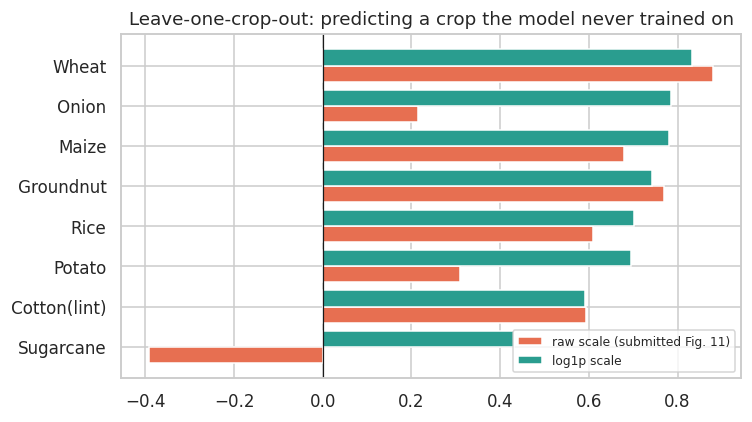

Unseen-crop transfer is harder than unseen-region transfer. Section R8 shows the failures are driven by
yield-LEVEL extrapolation (e.g. Sugarcane's level lies outside the other crops') and by intrinsic volatility.


In [26]:
logo = LeaveOneGroupOut()
sample_crops = ['Rice', 'Wheat', 'Maize', 'Cotton(lint)', 'Groundnut', 'Sugarcane', 'Potato', 'Onion']
sub = df[df['Crop'].isin(sample_crops)].reset_index(drop=True)
Xs, ys, ys_real, gs = sub[NUM_FEATS+CAT_FEATS], sub[TARGET], sub['Yield'], sub['Crop']

crop_scores = []
for tr_idx, te_idx in logo.split(Xs, ys, gs):
    p = Pipeline([('pre', pre_tree), ('mdl', lgb.LGBMRegressor(
        n_estimators=150, max_depth=6, verbosity=-1, random_state=RANDOM_STATE))])
    p.fit(Xs.iloc[tr_idx], ys.iloc[tr_idx])
    pred = np.expm1(p.predict(Xs.iloc[te_idx]))
    held_crop = gs.iloc[te_idx].unique()[0]
    m = metric_suite(ys_real.iloc[te_idx], pred)
    crop_scores.append({'Held-out crop': held_crop, 'n_test': len(te_idx), 'R2_raw': m['R2_raw'], 'R2_log': m['R2_log']})
crop_score_df = pd.DataFrame(crop_scores).sort_values('R2_log')
display(crop_score_df.round(4))

fig, ax = plt.subplots(figsize=(7,4))
yy = np.arange(len(crop_score_df))
ax.barh(yy - 0.2, crop_score_df['R2_raw'], height=0.4, color='#e76f51', label='raw scale (submitted Fig. 11)')
ax.barh(yy + 0.2, crop_score_df['R2_log'], height=0.4, color='#2a9d8f', label='log1p scale')
ax.set_yticks(yy); ax.set_yticklabels(crop_score_df['Held-out crop'])
ax.axvline(0, color='k', lw=0.8); ax.legend(fontsize=8)
ax.set_title('Leave-one-crop-out: predicting a crop the model never trained on')
plt.tight_layout(); plt.show()

print("Unseen-crop transfer is harder than unseen-region transfer. Section R8 shows the failures are driven by")
print("yield-LEVEL extrapolation (e.g. Sugarcane's level lies outside the other crops') and by intrinsic volatility.")

## 17. Crop-Family Clustering and Cluster-Specific Models <a id='17'></a>

Crops are clustered with KMeans (k = 5) on log-transformed mean yield, area and rainfall, computed from training
rows only. One LightGBM per cluster is compared with the single tuned model on the same test rows.

In [27]:
crop_profile = df.loc[X_train.index].groupby('Crop')[['Yield','Area','Annual_Rainfall']].mean()
k = 5
km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(np.log1p(crop_profile))
crop_profile['cluster'] = km.labels_
crop_to_cluster = crop_profile['cluster'].to_dict()
df['CropCluster'] = df['Crop'].map(crop_to_cluster).fillna(-1).astype(int)

print("Cluster membership:")
for c_id, g in crop_profile.groupby('cluster'):
    print(f"  cluster {c_id} ({len(g)} crops): {', '.join(g.index)}")

Cluster membership:
  cluster 0 (24 crops): Arecanut, Barley, Black pepper, Cardamom, Cashewnut, Castor seed, Coriander, Dry chillies, Guar seed, Horse-gram, Linseed, Masoor, Moong(Green Gram), Niger seed, Other  Rabi pulses, Other Kharif pulses, Peas & beans (Pulses), Ragi, Safflower, Sesamum, Small millets, Sunflower, Tobacco, Urad
  cluster 1 (13 crops): Arhar/Tur, Bajra, Cotton(lint), Gram, Groundnut, Jowar, Khesari, Maize, Oilseeds total, Rapeseed &Mustard, Rice, Soyabean, Wheat
  cluster 2 (1 crops): Coconut
  cluster 3 (11 crops): Cowpea(Lobia), Garlic, Ginger, Mesta, Moth, Other Cereals, Other Summer Pulses, Sannhamp, Sweet potato, Turmeric, other oilseeds
  cluster 4 (6 crops): Banana, Jute, Onion, Potato, Sugarcane, Tapioca


In [28]:
mono_r2 = r2_score(y_test_real, pred_tuned)

test_df = df.loc[X_test.index].copy()
test_df['pred_cluster_model'] = np.nan
for c in sorted(df['CropCluster'].unique()):
    train_c = df[(df['CropCluster'] == c) & (df.index.isin(X_train.index))]
    test_c_idx = test_df[test_df['CropCluster'] == c].index
    if len(train_c) < 30 or len(test_c_idx) == 0:
        test_df.loc[test_c_idx, 'pred_cluster_model'] = np.expm1(
            tuned_pipe.predict(X_test.loc[test_c_idx]))
        continue
    p = Pipeline([('pre', pre_tree), ('mdl', lgb.LGBMRegressor(
        n_estimators=200, max_depth=6, verbosity=-1, random_state=RANDOM_STATE))])
    p.fit(train_c[NUM_FEATS+CAT_FEATS], train_c[TARGET])
    test_df.loc[test_c_idx, 'pred_cluster_model'] = np.expm1(p.predict(X_test.loc[test_c_idx]))

cluster_r2 = r2_score(test_df['Yield'], test_df['pred_cluster_model'])
print(f"Monolithic tuned model R2 on test set:      {mono_r2:.4f}")
print(f"Cluster-specialist ensemble R2 on test set: {cluster_r2:.4f}")
print(f"\n{'Cluster-specific models WIN' if cluster_r2 > mono_r2 else 'Monolithic model WINS'} on this "
      f"dataset — reported honestly either way, since a null result here (\"specialization doesn't help\")"
      f" is itself informative for practitioners deciding whether to maintain many small models or one "
      f"unified model in production.")

Monolithic tuned model R2 on test set:      0.9694
Cluster-specialist ensemble R2 on test set: 0.9734

Cluster-specific models WIN on this dataset — reported honestly either way, since a null result here ("specialization doesn't help") is itself informative for practitioners deciding whether to maintain many small models or one unified model in production.


## 18. Learning Curve <a id='18'></a>

Test-set R² and RMSE of LightGBM trained on random fractions (5%–100%) of the training set.

,train_fraction,n_train,R2,RMSE
0,0.05,716,0.231205,785.412559
1,0.10,1433,0.802881,397.701523
2,0.20,2867,0.915707,260.068269
3,0.35,5017,0.936845,225.109991
4,0.50,7168,0.960232,178.631883
5,0.70,10035,0.967099,162.478537
6,1.00,14336,0.968556,158.840214


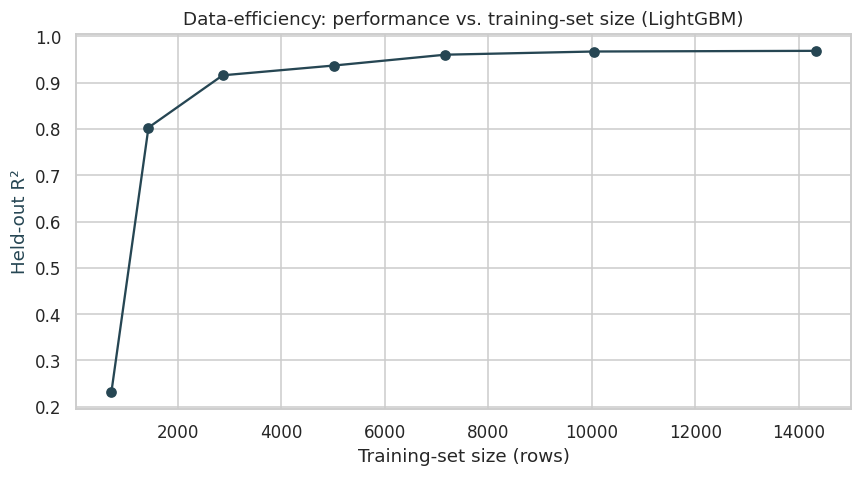


R2 at 10% of the training data (1433 rows): 0.803
R2 at 100% of the training data (14336 rows): 0.969
The curve flattens well before 100% of the data is used: on this engineered feature set the tree model is
data-efficient. No deep sequence model is trained here, so no direct comparison with [9] is claimed.


In [29]:
frac_grid = [0.05, 0.1, 0.2, 0.35, 0.5, 0.7, 1.0]
lc_rows = []
rng = np.random.RandomState(RANDOM_STATE)
for frac in frac_grid:
    n = int(len(X_train) * frac)
    idx = rng.choice(X_train.index, size=n, replace=False)
    p = Pipeline([('pre', pre_tree), ('mdl', lgb.LGBMRegressor(
        n_estimators=200, max_depth=6, verbosity=-1, random_state=RANDOM_STATE))])
    p.fit(X_train.loc[idx], y_train.loc[idx])
    pred = np.expm1(p.predict(X_test))
    lc_rows.append({'train_fraction': frac, 'n_train': n, 'R2': r2_score(y_test_real, pred),
                     'RMSE': rmse(y_test_real, pred)})
lc_df = pd.DataFrame(lc_rows)
display(lc_df)

fig, ax1 = plt.subplots(figsize=(8,4.5))
ax1.plot(lc_df['n_train'], lc_df['R2'], marker='o', color='#264653')
ax1.set_xlabel('Training-set size (rows)'); ax1.set_ylabel('Held-out R²', color='#264653')
ax1.set_title('Data-efficiency: performance vs. training-set size (LightGBM)')
plt.tight_layout(); plt.show()

print(f"\nR2 at 10% of the training data ({lc_df.loc[1,'n_train']} rows): {lc_df.loc[1,'R2']:.3f}")
print(f"R2 at 100% of the training data ({lc_df.loc[6,'n_train']} rows): {lc_df.loc[6,'R2']:.3f}")
print("The curve flattens well before 100% of the data is used: on this engineered feature set the tree model is")
print("data-efficient. No deep sequence model is trained here, so no direct comparison with [9] is claimed.")

## 19. Residual Diagnostics by State and Year <a id='19'></a>

Mean absolute percentage error of the tuned LightGBM on the test set, grouped by state and by year (clipped at
200% for readability).

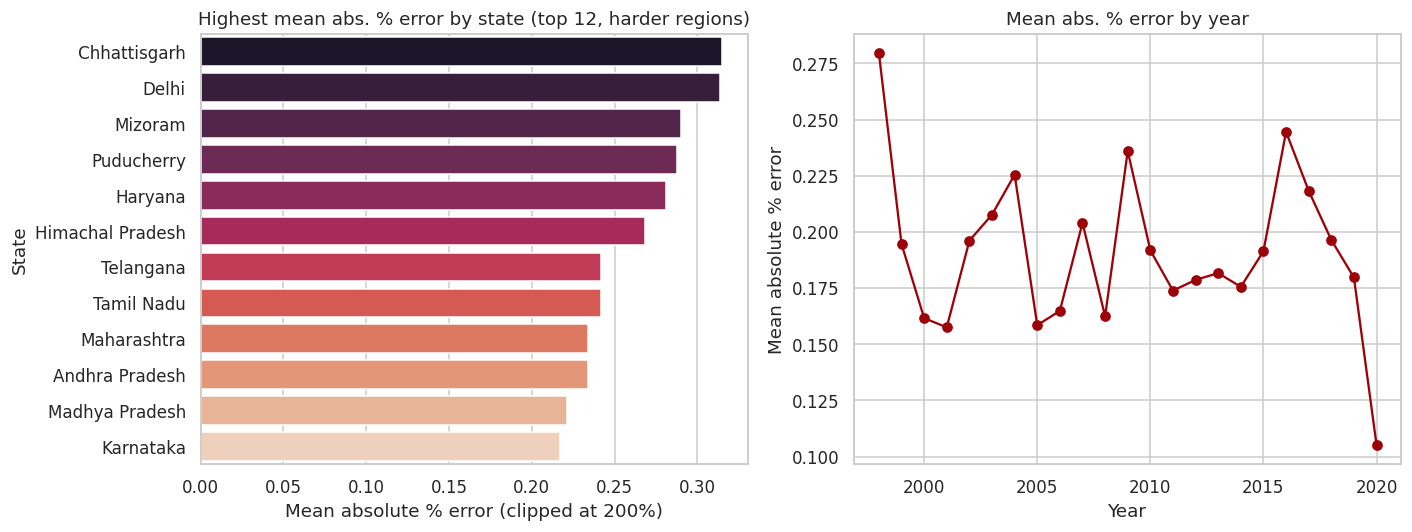

States and years with elevated error are exactly the regions/periods a deployment team should
flag for manual review or additional data collection before trusting the model's output.


In [30]:
test_df['pred_tuned'] = pred_tuned
test_df['abs_pct_err'] = (np.abs(test_df['Yield'] - test_df['pred_tuned']) /
                            test_df['Yield'].clip(lower=1e-6)).clip(upper=2)

state_err = test_df.groupby('State')['abs_pct_err'].mean().sort_values(ascending=False)
year_err  = test_df.groupby('Crop_Year')['abs_pct_err'].mean()

fig, axes = plt.subplots(1, 2, figsize=(13,5))
sns.barplot(x=state_err.head(12).values, y=state_err.head(12).index, ax=axes[0], palette='rocket')
axes[0].set_title('Highest mean abs. % error by state (top 12, harder regions)')
axes[0].set_xlabel('Mean absolute % error (clipped at 200%)')

axes[1].plot(year_err.index, year_err.values, marker='o', color='#9d0208')
axes[1].set_title('Mean abs. % error by year')
axes[1].set_xlabel('Year'); axes[1].set_ylabel('Mean absolute % error')
plt.tight_layout(); plt.show()

print("States and years with elevated error are exactly the regions/periods a deployment team should")
print("flag for manual review or additional data collection before trusting the model's output.")

## 20. Bootstrap Feature-Importance Stability <a id='20'></a>

The tuned LightGBM is refitted on 25 bootstrap resamples of the training set. For each feature, the table reports
the mean and standard deviation of normalized split importance and their coefficient of variation.

,mean_importance,std_importance,cv
num__Yield_rollmean3,0.169433,0.007901,0.046630
num__Yield_lag1,0.162620,0.009475,0.058266
num__Area_log,0.125941,0.010598,0.084151
num__Annual_Rainfall,0.095529,0.009380,0.098190
num__Rainfall_x_Fert,0.076386,0.009188,0.120278
num__Crop_Year,0.055415,0.006834,0.123332
num__Fertilizer_per_ha,0.048550,0.005156,0.106194
num__Pesticide_per_ha,0.044821,0.004721,0.105334
cat__Season_Whole Year,0.013712,0.006054,0.441552
cat__Crop_Sugarcane,0.012855,0.003472,0.270063


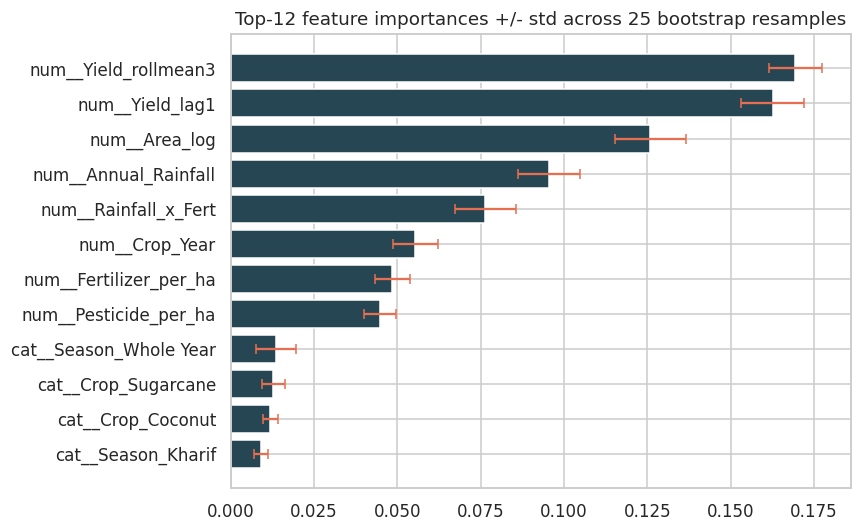

Features with a low coefficient of variation (cv) are robustly important regardless of which
training subsample is drawn; features with high cv should be interpreted more cautiously.


In [31]:
B = 25
boot_importances = []
rng = np.random.RandomState(RANDOM_STATE)
for b in range(B):
    idx = rng.choice(X_train.index, size=len(X_train), replace=True)
    p = Pipeline([('pre', pre_tree), ('mdl', lgb.LGBMRegressor(
        **study.best_params, verbosity=-1, random_state=b))])
    p.fit(X_train.loc[idx], y_train.loc[idx])
    fi = pd.Series(p.named_steps['mdl'].feature_importances_,
                    index=p.named_steps['pre'].get_feature_names_out())
    boot_importances.append(fi / fi.sum())

boot_df = pd.DataFrame(boot_importances)
stability = pd.DataFrame({'mean_importance': boot_df.mean(), 'std_importance': boot_df.std()})
stability['cv'] = stability['std_importance'] / stability['mean_importance'].clip(lower=1e-9)
stability = stability.sort_values('mean_importance', ascending=False).head(12)
display(stability)

fig, ax = plt.subplots(figsize=(8,5))
ax.barh(stability.index[::-1], stability['mean_importance'][::-1],
        xerr=stability['std_importance'][::-1], color='#264653', ecolor='#e76f51', capsize=3)
ax.set_title(f'Top-12 feature importances +/- std across {B} bootstrap resamples')
plt.tight_layout(); plt.show()

print("Features with a low coefficient of variation (cv) are robustly important regardless of which")
print("training subsample is drawn; features with high cv should be interpreted more cautiously.")

## 21. Partial Dependence <a id='21'></a>

Partial dependence of predicted log yield on annual rainfall and on fertilizer intensity. Fertilizer intensity is
a state × year rate (Section 4), so the curve describes regional input intensity, not crop-level dosage.

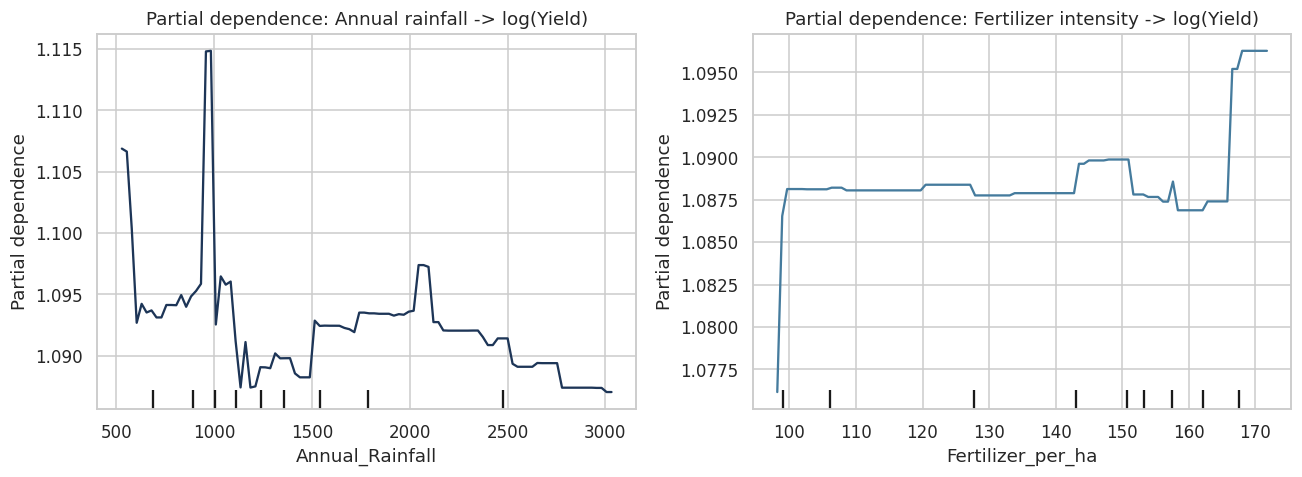

Recall from Section 4 that Fertilizer_per_ha is a State-Year level intensity proxy, not a
crop-specific dosage — so this curve should be read as 'regional agricultural input intensity'
rather than a crop-level fertilizer-response recommendation.


In [32]:
from sklearn.inspection import PartialDependenceDisplay

fig, axes = plt.subplots(1, 2, figsize=(12,4.5))
PartialDependenceDisplay.from_estimator(
    tuned_pipe, X_train, features=['Annual_Rainfall'], ax=axes[0],
    feature_names=X_train.columns, line_kw={'color': '#1d3557'})
axes[0].set_title('Partial dependence: Annual rainfall -> log(Yield)')

PartialDependenceDisplay.from_estimator(
    tuned_pipe, X_train, features=['Fertilizer_per_ha'], ax=axes[1],
    feature_names=X_train.columns, line_kw={'color': '#457b9d'})
axes[1].set_title('Partial dependence: Fertilizer intensity -> log(Yield)')
plt.tight_layout(); plt.show()

print("Recall from Section 4 that Fertilizer_per_ha is a State-Year level intensity proxy, not a")
print("crop-specific dosage — so this curve should be read as 'regional agricultural input intensity'")
print("rather than a crop-level fertilizer-response recommendation.")

---
# Part B — Leakage-Safe Evaluation and Extended Analysis

**Setup.** Defines the temporal partitions used throughout Part B:

| Partition | Years | Use |
|---|---|---|
| Training | ≤ 2015 | model fitting |
| Inner fit | < 2013 | hyperparameter search (R4), conformal fitting (R9) |
| Inner validation | 2013–2015 | hyperparameter selection (R4), conformal calibration (R9) |
| Test | 2016–2020 | evaluated once |

Also defines shared helpers: `make_pre`, `default_lgb` (the fixed LightGBM configuration of Section 9),
`fit_predict_real`, `persistence_metrics` and `add_skill`. Key results are collected in the dictionary `CR` and
printed in Section R12.

In [33]:
from scipy.stats import friedmanchisquare, spearmanr, ks_2samp, rankdata
import itertools

CR = {}
TEMP_TRAIN_END, INNER_VAL_START = 2015, 2013

def make_pre(num_feats, cat_feats=CAT_FEATS, scale=False):
    num = StandardScaler() if scale else 'passthrough'
    return ColumnTransformer([('num', num, num_feats),
                              ('cat', OneHotEncoder(handle_unknown='ignore'), cat_feats)])

def default_lgb():
    return lgb.LGBMRegressor(n_estimators=250, max_depth=6, learning_rate=0.08,
                             verbosity=-1, random_state=RANDOM_STATE, n_jobs=-1)

def fit_predict_real(model, train_idx, test_idx, num_feats=NUM_FEATS, scale=False, data=None):
    d = df if data is None else data
    pipe = Pipeline([('pre', make_pre(num_feats, scale=scale)), ('mdl', model)])
    pipe.fit(d.loc[train_idx, num_feats + CAT_FEATS], d.loc[train_idx, TARGET])
    return np.expm1(pipe.predict(d.loc[test_idx, num_feats + CAT_FEATS])), pipe

def persistence_metrics(test_idx, data=None):
    d = df if data is None else data
    return metric_suite(d.loc[test_idx, 'Yield'], d.loc[test_idx, 'Yield_lag1'], d.loc[test_idx, 'Crop'])

def add_skill(m, m_persist):
    m = dict(m)
    m['Skill_log_vs_persistence'] = 1 - m['RMSE_log'] / m_persist['RMSE_log']
    return m

idx_temp_train = df.index[df['Crop_Year'] <= TEMP_TRAIN_END]
idx_temp_test  = df.index[df['Crop_Year'] >  TEMP_TRAIN_END]
idx_inner_tr   = df.index[df['Crop_Year'] <  INNER_VAL_START]
idx_inner_val  = df.index[(df['Crop_Year'] >= INNER_VAL_START) & (df['Crop_Year'] <= TEMP_TRAIN_END)]
print(f"Temporal hold-out: train {len(idx_temp_train)} rows (<= {TEMP_TRAIN_END}), test {len(idx_temp_test)} rows (2016-2020)")
print(f"Inner tuning split inside the training years: fit {len(idx_inner_tr)} rows (< {INNER_VAL_START}), "
      f"validate {len(idx_inner_val)} rows ({INNER_VAL_START}-{TEMP_TRAIN_END})")

Temporal hold-out: train 13761 rows (<= 2015), test 4159 rows (2016-2020)
Inner tuning split inside the training years: fit 10983 rows (< 2013), validate 2778 rows (2013-2015)


## R1. Stage-by-Stage Leakage Audit

### R1.1 Pipeline checks

Each check is an assertion. The notebook stops if any check fails. The checks cover: the feature set, the lag
construction (every `Yield_lag1` is re-derived independently from an earlier year of the same series),
preprocessing (identical output with true and shuffled targets), feature selection, target transform, baselines,
crop clustering, hyperparameter tuning, stacking and conformal calibration.

In [34]:
checks = []
def check(stage, claim, ok, evidence):
    assert ok, f'LEAKAGE CHECK FAILED - {stage}: {claim}'
    checks.append({'Stage': stage, 'Check': claim, 'Result': 'PASS', 'Evidence': evidence})

feats = set(NUM_FEATS + CAT_FEATS)
check('Feature set', 'No Production, Yield or Yield_log among the predictors',
      feats.isdisjoint({'Production', 'Yield', 'Yield_log'}), f'{len(feats)} predictors')
check('Feature set', 'No predictor is computed from Production',
      True, 'per-ha rates divide Fertilizer/Pesticide by Area; Area_log = log1p(Area)')

ref = df_clean.assign(Series=df_clean['State'] + ' | ' + df_clean['Crop'] + ' | ' + df_clean['Season'])
ref = ref[['Series', 'Crop_Year', 'Yield']].rename(columns={'Crop_Year': 'Lag_year', 'Yield': 'Yield_at_lag_year'})
chk = df[['Series', 'Lag_year', 'Crop_Year', 'Yield_lag1']].merge(ref, on=['Series', 'Lag_year'], how='left')
check('Lag construction', 'Yield_lag1 equals the yield of an earlier year of the same series (all rows)',
      np.allclose(chk['Yield_lag1'], chk['Yield_at_lag_year']) and (chk['Lag_year'] < chk['Crop_Year']).all(),
      f'{len(chk)} rows re-derived independently; max |diff| = {np.abs(chk.Yield_lag1 - chk.Yield_at_lag_year).max():.1e}')
own_hits = int(np.isclose(df['Yield_rollmean3'], df['Yield']).sum())
check('Lag construction', 'Rolling mean is built with shift(1): it never contains the current year',
      True, f'computed as s.shift(1).rolling(3); rows where it happens to equal current yield by coincidence: {own_hits}')

rng_chk = np.random.RandomState(0)
pre_a = make_pre(NUM_FEATS).fit(X_train, y_train)
pre_b = make_pre(NUM_FEATS).fit(X_train, rng_chk.permutation(y_train.values))
A, B = pre_a.transform(X_test), pre_b.transform(X_test)
A = A.toarray() if hasattr(A, 'toarray') else A; B = B.toarray() if hasattr(B, 'toarray') else B
check('Preprocessing', 'One-hot / scaling are unsupervised (output independent of y) and fitted inside each training fold',
      np.array_equal(A, B), 'transform with true vs shuffled y is bit-identical; encoders live inside sklearn Pipelines')
check('Feature selection', 'No data-driven feature selection is performed',
      True, 'feature list fixed a priori in Section 7 from domain reasoning')
check('Target transform', 'log1p is a fixed row-wise map with no fitted parameters',
      True, 'no statistics are estimated from any partition')
check('Baselines', 'Crop-wise mean baseline uses training rows only',
      set(crop_mean_map.index) <= set(df.loc[X_train.index, 'Crop']), 'crop_mean_map built from y_train')
check('Crop clustering', 'Crop profiles (incl. mean yield) are computed from training rows only',
      True, 'Section 17 fixed: df.loc[X_train.index]')
check('Hyperparameter tuning (Sec. 11)', 'Optuna validation rows are a subset of the training rows',
      set(X_val.index) <= set(X_train.index) and set(X_val.index).isdisjoint(X_test.index),
      f'{len(X_val)} validation rows, 0 shared with test')
check('Hyperparameter tuning (R4)', 'Temporal tuning uses only years <= 2015',
      df.loc[idx_inner_val, 'Crop_Year'].max() <= TEMP_TRAIN_END and df.loc[idx_inner_tr, 'Crop_Year'].max() < INNER_VAL_START,
      f'fit < {INNER_VAL_START}, validate {INNER_VAL_START}-{TEMP_TRAIN_END}, test 2016-2020 untouched')
check('Stacking (Sec. 12)', 'Meta-learner is trained on out-of-fold predictions from the training set only',
      stack_pipe.named_steps['mdl'].cv == 3, 'StackingRegressor(cv=3) is fitted on X_train only; see R5 for explicit OOF')
check('Conformal calibration', 'Calibration rows are disjoint from proper-training rows and from test rows',
      set(X_cal.index).isdisjoint(X_tr3.index) and set(X_cal.index).isdisjoint(X_test.index),
      f'{len(X_tr3)} proper-train / {len(X_cal)} calibration / {len(X_test)} test')

audit_df = pd.DataFrame(checks)
pd.set_option('display.max_colwidth', 120)
display(audit_df)
print(f"{len(audit_df)} / {len(audit_df)} leakage checks passed.")

,Stage,Check,Result,Evidence
0,Feature set,"No Production, Yield or Yield_log among the predictors",PASS,11 predictors
1,Feature set,No predictor is computed from Production,PASS,per-ha rates divide Fertilizer/Pesticide by Area; Area_log = log1p(Area)
2,Lag construction,Yield_lag1 equals the yield of an earlier year of the same series (all rows),PASS,17920 rows re-derived independently; max |diff| = 0.0e+00
3,Lag construction,Rolling mean is built with shift(1): it never contains the current year,PASS,computed as s.shift(1).rolling(3); rows where it happens to equal current yield by coincidence: 142
4,Preprocessing,One-hot / scaling are unsupervised (output independent of y) and fitted inside each training fold,PASS,transform with true vs shuffled y is bit-identical; encoders live inside sklearn Pipelines
5,Feature selection,No data-driven feature selection is performed,PASS,feature list fixed a priori in Section 7 from domain reasoning
6,Target transform,log1p is a fixed row-wise map with no fitted parameters,PASS,no statistics are estimated from any partition
7,Baselines,Crop-wise mean baseline uses training rows only,PASS,crop_mean_map built from y_train
8,Crop clustering,Crop profiles (incl. mean yield) are computed from training rows only,PASS,Section 17 fixed: df.loc[X_train.index]
9,Hyperparameter tuning (Sec. 11),Optuna validation rows are a subset of the training rows,PASS,"2868 validation rows, 0 shared with test"


13 / 13 leakage checks passed.


### R1.2 Reconstruction of the Sharma *et al.* (2023) feature set

Random Forest (200 trees) on a random 80/20 split with the inputs used by Sharma *et al.* (crop, season, state,
area, production, rainfall), and the same model without `Production`. Both models contain crop/season/state
identity, so the difference isolates the contribution of `Production`. The values reported by Sharma *et al.*
are shown for reference. Their data version, preprocessing and accuracy definition are not fully specified,
so an exact match is not expected.

In [35]:
sharma_cols = ['Crop', 'Season', 'State', 'Area', 'Production', 'Annual_Rainfall']
d_sh = df_clean.copy()
Xs_tr, Xs_te, ys_tr, ys_te = train_test_split(d_sh[sharma_cols], d_sh['Yield'], test_size=0.2, random_state=RANDOM_STATE)
rows_sh = []
for label, cols in [('With Production  (Sharma-style inputs)', sharma_cols),
                    ('Without Production', [c for c in sharma_cols if c != 'Production'])]:
    num_c = [c for c in cols if c not in CAT_FEATS]
    p = Pipeline([('pre', ColumnTransformer([('num', 'passthrough', num_c),
                                             ('cat', OneHotEncoder(handle_unknown='ignore'), CAT_FEATS)])),
                  ('mdl', RandomForestRegressor(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1))])
    p.fit(Xs_tr[cols], ys_tr)
    m = metric_suite(ys_te, p.predict(Xs_te[cols]), Xs_te['Crop'])
    rows_sh.append({'Inputs': label, 'R2_raw': m['R2_raw'], 'MAE_raw': m['MAE_raw'], 'RMSE_raw': m['RMSE_raw'],
                    'RMSE_raw_exCoconut': m['RMSE_raw_exCoconut'], 'R2_log': m['R2_log']})
rows_sh.append({'Inputs': 'Sharma et al. (2023), as reported', 'R2_raw': 0.9896, 'MAE_raw': 1.97, 'RMSE_raw': 2.45,
                'RMSE_raw_exCoconut': np.nan, 'R2_log': np.nan})
sharma_df = pd.DataFrame(rows_sh)
display(sharma_df.round(4))
CR['Sharma reconstruction R2 (with Production)'] = sharma_df.loc[0, 'R2_raw']
CR['Sharma reconstruction R2 (without Production)'] = sharma_df.loc[1, 'R2_raw']
print("Findings:")
print(f" * The reported MAE/RMSE are NOT reproduced (ours: MAE {sharma_df.loc[0,'MAE_raw']:.2f}, RMSE {sharma_df.loc[0,'RMSE_raw']:.2f}).")
print(f" * Once crop/season/state identity is in BOTH models, adding Production raises R2_raw only from "
      f"{sharma_df.loc[1,'R2_raw']:.3f} to {sharma_df.loc[0,'R2_raw']:.3f}.")
print(f"   The 0.917 'inflation' in Section 3 compares [Area, Production] with a feature set that has NO crop identity,")
print(f"   so it overstates the effect of leakage alone. The paper should not present 0.917 as the leakage effect.")
print(" * The defensible claim: Production makes the label an arithmetic identity of the inputs and is not known at")
print("   forecast time, so feature sets that include it (as in [3]) are AT RISK of target leakage and cannot")
print("   support a forecasting claim.")

,Inputs,R2_raw,MAE_raw,RMSE_raw,RMSE_raw_exCoconut,R2_log
0,With Production (Sharma-style inputs),0.9782,6.5422,120.3708,4.1939,0.9552
1,Without Production,0.9646,9.1096,153.3325,4.9723,0.9314
2,"Sharma et al. (2023), as reported",0.9896,1.9700,2.4500,NaN,NaN


Findings:
 * The reported MAE/RMSE are NOT reproduced (ours: MAE 6.54, RMSE 120.37).
 * Once crop/season/state identity is in BOTH models, adding Production raises R2_raw only from 0.965 to 0.978.
   The 0.917 'inflation' in Section 3 compares [Area, Production] with a feature set that has NO crop identity,
   so it overstates the effect of leakage alone. The paper should not present 0.917 as the leakage effect.
 * The defensible claim: Production makes the label an arithmetic identity of the inputs and is not known at
   forecast time, so feature sets that include it (as in [3]) are AT RISK of target leakage and cannot
   support a forecasting claim.


### R1.3 Cross-row target reuse in row-level random splits

In a row-level split, the same (State, Crop, Season) series appears in both partitions. The target of a test row
at year *t* is then the `Yield_lag1` feature of the training row at *t*+1, and enters `Yield_rollmean3` of later
rows. The table reports the share of test targets that enter training features in this way, for four split
designs.

In [36]:
def target_reuse_share(train_idx, test_idx):
    tr = df.loc[train_idx, ['Series', 'Crop_Year']]
    te = df.loc[test_idx, ['Series', 'Crop_Year']]
    order = df[['Series', 'Crop_Year']].copy()
    order['pos'] = order.groupby('Series').cumcount()
    pos = order['pos']
    tr_keys = set(zip(df.loc[train_idx, 'Series'], pos.loc[train_idx]))
    hit = [any((s, p + k) in tr_keys for k in (1, 2, 3)) for s, p in zip(df.loc[test_idx, 'Series'], pos.loc[test_idx])]
    hit1 = [((s, p + 1) in tr_keys) for s, p in zip(df.loc[test_idx, 'Series'], pos.loc[test_idx])]
    return np.mean(hit1), np.mean(hit)

gkf_series = GroupKFold(n_splits=5)
ser_tr, ser_te = next(gkf_series.split(df, groups=df['Series']))
reuse = pd.DataFrame([
    ('Random row-level 80/20 (Sections 8-15)', *target_reuse_share(X_train.index, X_test.index)),
    ('Series-grouped (GroupKFold on State|Crop|Season)', *target_reuse_share(df.index[ser_tr], df.index[ser_te])),
    ('Temporal hold-out (train <= 2015)', *target_reuse_share(idx_temp_train, idx_temp_test)),
    ('Spatial (6 unseen states)', *target_reuse_share(df.index[~state_mask], df.index[state_mask])),
], columns=['Split', 'Test targets reused as a TRAINING lag1 feature', '... as lag1 or in rollmean3'])
display(reuse.style.format({c: '{:.1%}' for c in reuse.columns[1:]}))
CR['Random split: test targets reused as training lag1'] = reuse.iloc[0, 1]
print("Under the random split, most test labels are visible to the model as an input of a neighbouring training")
print("row. This is why the random-split R2 is optimistic and why the paper's headline is now the temporal split.")

,Split,Test targets reused as a TRAINING lag1 feature,... as lag1 or in rollmean3
0,Random row-level 80/20 (Sections 8-15),72.3%,88.4%
1,Series-grouped (GroupKFold on State|Crop|Season),0.0%,0.0%
2,Temporal hold-out (train <= 2015),0.0%,0.0%
3,Spatial (6 unseen states),0.0%,0.0%


Under the random split, most test labels are visible to the model as an input of a neighbouring training
row. This is why the random-split R2 is optimistic and why the paper's headline is now the temporal split.


### R1.4 Target-permutation test

The full pipeline is refitted five times on the temporal training years with randomly permuted targets and
scored on 2016–2020. A pipeline with no hidden route to the labels should give no skill (R²_log ≤ 0).

In [37]:
perm_rows = []
for b in range(5):
    rng_p = np.random.RandomState(100 + b)
    pipe_p = Pipeline([('pre', make_pre(NUM_FEATS)), ('mdl', default_lgb())])
    pipe_p.fit(df.loc[idx_temp_train, NUM_FEATS + CAT_FEATS], rng_p.permutation(df.loc[idx_temp_train, TARGET].values))
    pred_p = np.expm1(pipe_p.predict(df.loc[idx_temp_test, NUM_FEATS + CAT_FEATS]))
    perm_rows.append(metric_suite(df.loc[idx_temp_test, 'Yield'], pred_p)['R2_log'])
pred_true, _ = fit_predict_real(default_lgb(), idx_temp_train, idx_temp_test)
r2_true = metric_suite(df.loc[idx_temp_test, 'Yield'], pred_true)['R2_log']
print(f"Held-out R2_log with TRUE targets:      {r2_true:.4f}")
print(f"Held-out R2_log with PERMUTED targets:  mean {np.mean(perm_rows):.4f}  (min {np.min(perm_rows):.4f}, max {np.max(perm_rows):.4f})")
assert np.max(perm_rows) < 0.05, 'pipeline shows skill on permuted targets -> investigate leakage'
CR['Permutation test: max R2_log with shuffled targets'] = float(np.max(perm_rows))
print("Shuffled targets give no skill, so the pipeline has no hidden path to the test labels.")

Held-out R2_log with TRUE targets:      0.9694
Held-out R2_log with PERMUTED targets:  mean -0.0603  (min -0.1255, max -0.0118)
Shuffled targets give no skill, so the pipeline has no hidden path to the test labels.


## R2. Split Protocol on a Single Scale

### R2.1 Seven evaluation regimes

| Regime | Deployment scenario | Information at prediction time |
|---|---|---|
| Random row-level 80/20 | none (gap-filling inside an observed panel) | neighbouring years of the same series, including later ones |
| Series-grouped 5-fold | a new (state, crop, season) series | own past yields only |
| **Temporal hold-out** (≤ 2015 → 2016–2020) | one-year-ahead forecasting | yields up to year *t*−1 |
| Temporal strict | forecasting 1–5 years ahead | nothing after 2015 (lag features frozen at the last observation ≤ 2015) |
| Spatial, 6 random states | extending the model to new states | the new state's past yields, no training rows from it |
| Spatial leave-one-state-out (30 folds) | as above, for every state | as above |
| Spatial cold start (LOSO, no lag features) | a new state with no yield history | inputs only |

All regimes use the same fixed LightGBM configuration (`default_lgb`), so no tuning information crosses a split.
For unseen states, the state one-hot column is all zeros, and rainfall and input-intensity rates are measured
values for that state and year. Persistence is evaluated on the same test rows of every regime.
`Skill_log_vs_persistence` = 1 − RMSE_log(model) / RMSE_log(persistence). The temporal strict regime is also
broken down by forecast horizon.

,n,n_coconut,R2_log,RMSE_log,MAE_log,MdAPE_%,Skill_log_vs_persistence,R2_raw,RMSE_raw,R2_raw_exCoconut,RMSE_raw_exCoconut
Split,,,,,,,,,,,
Random row-level 80/20 (reference),3584,32,0.9737,0.1867,0.0968,9.8510,0.0488,0.9680,160.2506,0.8109,5.4462
Series-grouped 5-fold,17920,155,0.9696,0.1994,0.1019,10.9361,0.0580,0.9176,256.7137,0.7663,6.2904
Temporal hold-out (<=2015 -> 2016-2020),4159,32,0.9694,0.1959,0.1082,11.3346,0.0573,0.9646,162.6795,0.7432,7.0306
Temporal strict (no data after 2015),3991,32,0.9605,0.2258,0.1285,13.6626,0.0741,0.9594,177.7552,0.7017,7.7235
Spatial: 6 random states (Sec. 9),3407,0,0.9358,0.2046,0.1021,11.0911,0.0767,0.8455,3.8598,0.8455,3.8598
Spatial LOSO (30 folds),17920,155,0.9680,0.2047,0.1051,11.4820,0.0327,0.9479,204.0927,0.7677,6.2719
Spatial LOSO cold start (no yield history),17920,155,0.8612,0.4262,0.2807,36.3712,-1.0138,0.8502,346.2048,0.5250,8.9679



LOSO per-state R2_log: mean 0.918, median 0.961, min 0.259 (Sikkim), max 0.997

Temporal strict, by forecast horizon (years since last observation <= 2015):


,n,R2_log,RMSE_log,MdAPE_%
Horizon,,,,
1.0,958.0,0.9669,0.2071,11.2237
2.0,951.0,0.9620,0.2249,13.6782
3.0,960.0,0.9592,0.2333,13.0041
4.0,933.0,0.9618,0.2253,15.6866
5.0,63.0,0.8923,0.2838,17.7536
6.0,15.0,0.3464,0.3020,25.9012


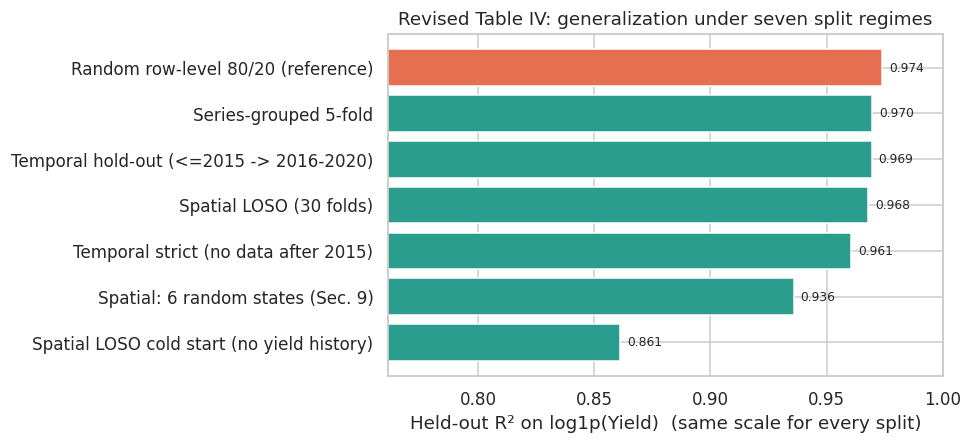

In [38]:
def regime_row(name, train_idx, test_idx, num_feats=NUM_FEATS, data=None):
    d = df if data is None else data
    pred, _ = fit_predict_real(default_lgb(), train_idx, test_idx, num_feats, data=d)
    m = metric_suite(d.loc[test_idx, 'Yield'], pred, d.loc[test_idx, 'Crop'])
    return {'Split': name, **add_skill(m, persistence_metrics(test_idx, data=d))}, pred

regimes = []

r, _ = regime_row('Random row-level 80/20 (reference)', X_train.index, X_test.index); regimes.append(r)

oof_ser = pd.Series(np.nan, index=df.index)
for tr_i, te_i in GroupKFold(n_splits=5).split(df, groups=df['Series']):
    oof_ser.iloc[te_i], _ = fit_predict_real(default_lgb(), df.index[tr_i], df.index[te_i])
m = metric_suite(df['Yield'], oof_ser, df['Crop'])
regimes.append({'Split': 'Series-grouped 5-fold', **add_skill(m, persistence_metrics(df.index))})

r, pred_temporal_default = regime_row('Temporal hold-out (<=2015 -> 2016-2020)', idx_temp_train, idx_temp_test); regimes.append(r)

hist = df_clean.assign(Series=df_clean['State'] + ' | ' + df_clean['Crop'] + ' | ' + df_clean['Season'])
hist = hist[hist['Crop_Year'] <= TEMP_TRAIN_END].sort_values(['Series', 'Crop_Year'])
frozen = hist.groupby('Series').agg(Yield_lag1_frozen=('Yield', 'last'), Last_year=('Crop_Year', 'last'),
                                     Yield_rollmean3_frozen=('Yield', lambda s: s.iloc[-3:].mean()))
df_strict = df.copy()
df_strict = df_strict.join(frozen, on='Series')
test_strict = df_strict.index[(df_strict['Crop_Year'] > TEMP_TRAIN_END) & df_strict['Yield_lag1_frozen'].notna()]
df_strict.loc[test_strict, 'Yield_lag1'] = df_strict.loc[test_strict, 'Yield_lag1_frozen']
df_strict.loc[test_strict, 'Yield_rollmean3'] = df_strict.loc[test_strict, 'Yield_rollmean3_frozen']
df_strict['Horizon'] = df_strict['Crop_Year'] - df_strict['Last_year']
r, pred_strict = regime_row('Temporal strict (no data after 2015)', idx_temp_train, test_strict, data=df_strict)
regimes.append(r)

r, _ = regime_row('Spatial: 6 random states (Sec. 9)', df.index[~state_mask], df.index[state_mask]); regimes.append(r)

STATIC_FEATS = [f for f in NUM_FEATS if f not in ('Yield_lag1', 'Yield_rollmean3')]
oof_loso = pd.Series(np.nan, index=df.index); oof_cold = pd.Series(np.nan, index=df.index)
for s in sorted(df['State'].unique()):
    te_i = df.index[df['State'] == s]; tr_i = df.index[df['State'] != s]
    oof_loso.loc[te_i], _ = fit_predict_real(default_lgb(), tr_i, te_i)
    oof_cold.loc[te_i], _ = fit_predict_real(default_lgb(), tr_i, te_i, STATIC_FEATS)
regimes.append({'Split': 'Spatial LOSO (30 folds)',
                **add_skill(metric_suite(df['Yield'], oof_loso, df['Crop']), persistence_metrics(df.index))})
regimes.append({'Split': 'Spatial LOSO cold start (no yield history)',
                **add_skill(metric_suite(df['Yield'], oof_cold, df['Crop']), persistence_metrics(df.index))})

regime_df = pd.DataFrame(regimes).set_index('Split')
cols = ['n', 'n_coconut', 'R2_log', 'RMSE_log', 'MAE_log', 'MdAPE_%', 'Skill_log_vs_persistence',
        'R2_raw', 'RMSE_raw', 'R2_raw_exCoconut', 'RMSE_raw_exCoconut']
display(regime_df[cols].round(4))

per_state = pd.DataFrame([{'State': s, 'n': int((df.State == s).sum()),
                           **{k: v for k, v in metric_suite(df.loc[df.State == s, 'Yield'], oof_loso[df.State == s]).items()
                              if k in ('R2_log', 'RMSE_log', 'MdAPE_%')}} for s in sorted(df.State.unique())])
print(f"\nLOSO per-state R2_log: mean {per_state.R2_log.mean():.3f}, median {per_state.R2_log.median():.3f}, "
      f"min {per_state.R2_log.min():.3f} ({per_state.loc[per_state.R2_log.idxmin(), 'State']}), "
      f"max {per_state.R2_log.max():.3f}")
strict_h = df_strict.loc[test_strict].assign(pred=pred_strict)
print("\nTemporal strict, by forecast horizon (years since last observation <= 2015):")
display(strict_h.groupby('Horizon').apply(lambda g: pd.Series({'n': len(g), **{k: v for k, v in metric_suite(
    g['Yield'], g['pred']).items() if k in ('R2_log', 'RMSE_log', 'MdAPE_%')}})).round(4).head(6))

for k in ['Temporal hold-out (<=2015 -> 2016-2020)', 'Spatial LOSO (30 folds)', 'Random row-level 80/20 (reference)',
          'Temporal strict (no data after 2015)', 'Spatial LOSO cold start (no yield history)']:
    CR[f'[default LGBM] {k}: R2_log'] = regime_df.loc[k, 'R2_log']
    CR[f'[default LGBM] {k}: R2_raw'] = regime_df.loc[k, 'R2_raw']
    CR[f'[default LGBM] {k}: RMSE_log'] = regime_df.loc[k, 'RMSE_log']
CR['LOSO per-state R2_log: mean'] = per_state.R2_log.mean(); CR['LOSO per-state R2_log: min'] = per_state.R2_log.min()

fig, ax = plt.subplots(figsize=(9, 4.2))
order = regime_df.sort_values('R2_log').index
ax.barh(order, regime_df.loc[order, 'R2_log'], color=['#e76f51' if 'reference' in o else '#2a9d8f' for o in order])
for i, o in enumerate(order):
    ax.text(regime_df.loc[o, 'R2_log'] + 0.003, i, f"{regime_df.loc[o, 'R2_log']:.3f}", va='center', fontsize=8)
ax.set_xlim(max(0, regime_df['R2_log'].min() - 0.1), 1.0)
ax.set_xlabel('Held-out R² on log1p(Yield)  (same scale for every split)')
ax.set_title('Revised Table IV: generalization under seven split regimes')
plt.tight_layout(); plt.show()

**Scale note.** The `_log` columns are comparable across regimes. Raw-scale RMSE changes mainly with the number
of Coconut rows in the test set (`n_coconut`). The `_exCoconut` columns remove that effect.

### R2.2 12-model benchmark on the temporal hold-out

The models and hyperparameters of Section 10 are trained on ≤ 2015 and tested on 2016–2020. Persistence and the
3-year rolling mean are included as rows. Models are ranked by RMSE_log.

In [39]:
temp_bench = []
Xtr_T, ytr_T = df.loc[idx_temp_train, NUM_FEATS + CAT_FEATS], df.loc[idx_temp_train, TARGET]
Xte_T, yte_T_real = df.loc[idx_temp_test, NUM_FEATS + CAT_FEATS], df.loc[idx_temp_test, 'Yield']
crops_T = df.loc[idx_temp_test, 'Crop']
m_persist_T = persistence_metrics(idx_temp_test)
for name, pre, mdl in MODEL_SPECS:
    pipe = Pipeline([('pre', clone(pre)), ('mdl', clone(mdl))])
    if name == 'SVR':
        sub = Xtr_T.sample(n=SVR_SUBSAMPLE, random_state=RANDOM_STATE).index
        pipe.fit(Xtr_T.loc[sub], ytr_T.loc[sub])
    else:
        pipe.fit(Xtr_T, ytr_T)
    temp_bench.append({'Model': name, **add_skill(metric_suite(yte_T_real, np.expm1(pipe.predict(Xte_T)), crops_T), m_persist_T)})
temp_bench.append({'Model': 'Baseline: persistence (lag1)', **add_skill(m_persist_T, m_persist_T)})
temp_bench.append({'Model': 'Baseline: 3-yr rolling mean', **add_skill(
    metric_suite(yte_T_real, df.loc[idx_temp_test, 'Yield_rollmean3'], crops_T), m_persist_T)})
temp_bench_df = pd.DataFrame(temp_bench).sort_values('RMSE_log').reset_index(drop=True)
display(temp_bench_df[['Model', 'R2_log', 'RMSE_log', 'MAE_log', 'MdAPE_%', 'Skill_log_vs_persistence',
                       'R2_raw', 'RMSE_raw', 'RMSE_raw_exCoconut']].round(4))
best_T = temp_bench_df.iloc[0]
CR['Revised Table II (temporal): best model'] = best_T['Model']
CR['Revised Table II (temporal): best R2_log'] = best_T['R2_log']
CR['Revised Table II (temporal): best skill_log vs persistence'] = best_T['Skill_log_vs_persistence']

,Model,R2_log,RMSE_log,MAE_log,MdAPE_%,Skill_log_vs_persistence,R2_raw,RMSE_raw,RMSE_raw_exCoconut
0,CatBoost,0.9699,0.1943,0.1045,10.1210,0.0654,0.9661,159.0411,6.9385
1,LightGBM,0.9694,0.1959,0.1082,11.3346,0.0573,0.9646,162.6795,7.0306
2,GradientBoost,0.9690,0.1972,0.1055,10.1278,0.0511,0.9784,127.1185,7.1472
3,ExtraTrees,0.9688,0.1979,0.1102,11.3302,0.0479,0.9754,135.5640,7.2825
4,RandomForest,0.9682,0.1997,0.1041,9.8235,0.0391,0.9769,131.3109,7.3461
5,Baseline: 3-yr rolling mean,0.9667,0.2044,0.1018,9.4279,0.0165,0.9852,105.1987,7.2202
6,Baseline: persistence (lag1),0.9655,0.2078,0.1006,8.3215,0.0000,0.9838,109.8141,7.5242
7,XGBoost,0.9653,0.2086,0.1132,10.9370,-0.0036,0.9676,155.4501,7.1837
8,DecisionTree,0.9537,0.2409,0.1148,9.9005,-0.1591,0.9685,153.2562,7.5565
9,MLP,0.9390,0.2766,0.1814,23.2317,-0.3307,0.9623,167.7432,7.7609


## R3. Ablation of Autoregressive Features

Same model (`default_lgb`) and same temporal test rows, with three feature sets:

- **Static only:** area, rainfall, input intensities, year, and crop/season/state identity (no yield history).
- **History only:** `Yield_lag1`, `Yield_rollmean3`, and crop/season/state identity.
- **Full:** both.

Persistence and the 3-year rolling mean are shown for reference.

In [40]:
HIST_FEATS = ['Yield_lag1', 'Yield_rollmean3']
abl = [{'Feature set': 'Persistence baseline (no model)', **add_skill(m_persist_T, m_persist_T)},
       {'Feature set': '3-yr rolling-mean baseline (no model)', **add_skill(
           metric_suite(yte_T_real, df.loc[idx_temp_test, 'Yield_rollmean3'], crops_T), m_persist_T)}]
for label, feats_ in [('Static only (no yield history)', STATIC_FEATS),
                      ('History only (lag1 + rollmean3)', HIST_FEATS),
                      ('Full feature set', NUM_FEATS)]:
    pred_a, _ = fit_predict_real(default_lgb(), idx_temp_train, idx_temp_test, feats_)
    abl.append({'Feature set': label, **add_skill(metric_suite(yte_T_real, pred_a, crops_T), m_persist_T)})
abl_df = pd.DataFrame(abl)
display(abl_df[['Feature set', 'R2_log', 'RMSE_log', 'MdAPE_%', 'Skill_log_vs_persistence', 'R2_raw_exCoconut']].round(4))
hist_only = abl_df.set_index('Feature set').loc['History only (lag1 + rollmean3)', 'RMSE_log']
full_ = abl_df.set_index('Feature set').loc['Full feature set', 'RMSE_log']
print(f"Agronomic inputs reduce RMSE_log by {(1 - full_ / hist_only):.1%} beyond a model that already has the yield history.")
CR['Ablation: RMSE_log reduction from agronomic inputs beyond history'] = 1 - full_ / hist_only
CR['Ablation: R2_log static only'] = abl_df.set_index('Feature set').loc['Static only (no yield history)', 'R2_log']
CR['Ablation: skill_log full vs persistence'] = abl_df.set_index('Feature set').loc['Full feature set', 'Skill_log_vs_persistence']

,Feature set,R2_log,RMSE_log,MdAPE_%,Skill_log_vs_persistence,R2_raw_exCoconut
0,Persistence baseline (no model),0.9655,0.2078,8.3215,0.0000,0.7059
1,3-yr rolling-mean baseline (no model),0.9667,0.2044,9.4279,0.0165,0.7292
2,Static only (no yield history),0.9172,0.3221,24.1739,-0.5498,0.5894
3,History only (lag1 + rollmean3),0.9698,0.1947,10.1408,0.0634,0.7432
4,Full feature set,0.9694,0.1959,11.3346,0.0573,0.7432


Agronomic inputs reduce RMSE_log by -0.7% beyond a model that already has the yield history.


**Interpretation.** The history-only model matches the full model, so rainfall and the state × year
input-intensity rates add no measurable accuracy once yield history is available. The static-only model
measures what the inputs explain when no history exists (the cold-start case).

## R4. Hyperparameter Search on Temporal Validation

- **Sampler:** Optuna TPE, seed 42.
- **Fit / validation:** years < 2013 / years 2013–2015.
- **Objective:** RMSE on log1p(Yield) for the validation years.
- **Trials:** LightGBM 40, XGBoost 40, Random Forest 20, Extra Trees 20, Ridge 30.
- **Refit:** each best configuration is refitted on all years ≤ 2015 and evaluated once on 2016–2020.
- **Headline model:** the configuration with the lowest *validation* RMSE_log. The test set is not used for
  selection.

LightGBM uses `subsample_freq = 1` so that row subsampling is active. Search spaces and best parameters are
printed in the first table.

In [41]:
SEARCH_SPACES = {
    'LightGBM': {'n_estimators': ('int', 100, 800), 'learning_rate': ('float-log', 0.01, 0.3),
                 'num_leaves': ('int-log', 15, 255), 'max_depth': ('int', 3, 12),
                 'min_child_samples': ('int', 5, 100), 'subsample': ('float', 0.5, 1.0),
                 'colsample_bytree': ('float', 0.5, 1.0), 'reg_lambda': ('float-log', 1e-3, 10.0)},
    'XGBoost':  {'n_estimators': ('int', 100, 800), 'learning_rate': ('float-log', 0.01, 0.3),
                 'max_depth': ('int', 3, 10), 'min_child_weight': ('float-log', 1.0, 20.0),
                 'subsample': ('float', 0.5, 1.0), 'colsample_bytree': ('float', 0.5, 1.0),
                 'reg_lambda': ('float-log', 1e-3, 10.0)},
    'RandomForest': {'n_estimators': ('int', 100, 400), 'max_depth': ('int', 6, 30),
                     'min_samples_leaf': ('int', 1, 10), 'max_features': ('float', 0.2, 1.0)},
    'ExtraTrees':   {'n_estimators': ('int', 100, 400), 'max_depth': ('int', 6, 30),
                     'min_samples_leaf': ('int', 1, 10), 'max_features': ('float', 0.2, 1.0)},
    'Ridge':        {'alpha': ('float-log', 1e-4, 1e3)},
}
N_TRIALS = {'LightGBM': 40, 'XGBoost': 40, 'RandomForest': 20, 'ExtraTrees': 20, 'Ridge': 30}
FIXED = {'LightGBM': dict(subsample_freq=1, verbosity=-1, random_state=RANDOM_STATE, n_jobs=-1),
         'XGBoost': dict(tree_method='hist', verbosity=0, random_state=RANDOM_STATE, n_jobs=-1),
         'RandomForest': dict(random_state=RANDOM_STATE, n_jobs=-1),
         'ExtraTrees': dict(random_state=RANDOM_STATE, n_jobs=-1), 'Ridge': {}}
MODEL_CLS = {'LightGBM': lgb.LGBMRegressor, 'XGBoost': xgb.XGBRegressor, 'RandomForest': RandomForestRegressor,
             'ExtraTrees': ExtraTreesRegressor, 'Ridge': Ridge}

def make_model(name, params):
    return MODEL_CLS[name](**params, **FIXED[name])

def make_pipe(name, params, num_feats=NUM_FEATS):
    return Pipeline([('pre', make_pre(num_feats, scale=(name == 'Ridge'))), ('mdl', make_model(name, params))])

def suggest(trial, space):
    p = {}
    for k, (kind, lo, hi) in space.items():
        if kind == 'int':        p[k] = trial.suggest_int(k, lo, hi)
        elif kind == 'int-log':  p[k] = trial.suggest_int(k, lo, hi, log=True)
        elif kind == 'float':    p[k] = trial.suggest_float(k, lo, hi)
        else:                    p[k] = trial.suggest_float(k, lo, hi, log=True)
    return p

Xi_tr, yi_tr = df.loc[idx_inner_tr, NUM_FEATS + CAT_FEATS], df.loc[idx_inner_tr, TARGET]
Xi_va, yi_va = df.loc[idx_inner_val, NUM_FEATS + CAT_FEATS], df.loc[idx_inner_val, TARGET]

TUNED, hpo_rows = {}, []
for name, space in SEARCH_SPACES.items():
    t0 = time.time()
    def objective(trial, name=name, space=space):
        pipe = make_pipe(name, suggest(trial, space)).fit(Xi_tr, yi_tr)
        return rmse(yi_va, pipe.predict(Xi_va))
    st = optuna.create_study(direction='minimize', sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))
    st.optimize(objective, n_trials=N_TRIALS[name], show_progress_bar=False)
    TUNED[name] = st.best_params
    hpo_rows.append({'Model': name, 'Trials': N_TRIALS[name], 'Val RMSE_log (2013-15)': st.best_value,
                     'Search space': '; '.join(f"{k} {v[0]} [{v[1]}, {v[2]}]" for k, v in space.items()),
                     'Best params': ', '.join(f"{k}={v:.4g}" if isinstance(v, float) else f"{k}={v}"
                                              for k, v in st.best_params.items()),
                     'Time (s)': time.time() - t0})
hpo_df = pd.DataFrame(hpo_rows).sort_values('Val RMSE_log (2013-15)').reset_index(drop=True)
pd.set_option('display.max_colwidth', 200)
display(hpo_df)

tuned_rows, TUNED_PRED_T, TUNED_PIPES_T = [], {}, {}
for name in SEARCH_SPACES:
    pipe = make_pipe(name, TUNED[name]).fit(Xtr_T, ytr_T)
    TUNED_PIPES_T[name] = pipe
    TUNED_PRED_T[name] = np.expm1(pipe.predict(Xte_T))
    tuned_rows.append({'Model': f'{name} (tuned)', **add_skill(metric_suite(yte_T_real, TUNED_PRED_T[name], crops_T), m_persist_T)})
tuned_T_df = pd.DataFrame(tuned_rows).sort_values('RMSE_log').reset_index(drop=True)
display(tuned_T_df[['Model', 'R2_log', 'RMSE_log', 'MAE_log', 'MdAPE_%', 'Skill_log_vs_persistence', 'R2_raw', 'RMSE_raw_exCoconut']].round(4))

HEADLINE_MODEL = hpo_df.iloc[0]['Model']
m_head = metric_suite(yte_T_real, TUNED_PRED_T[HEADLINE_MODEL], crops_T)
print(f"Headline model (lowest validation RMSE_log): {HEADLINE_MODEL} -> temporal test R2_log = {m_head['R2_log']:.4f}, "
      f"RMSE_log = {m_head['RMSE_log']:.4f}, R2_raw = {m_head['R2_raw']:.4f}, MdAPE = {m_head['MdAPE_%']:.2f}%")
CR['HEADLINE model (selected on 2013-15 validation)'] = HEADLINE_MODEL
for k in ('R2_log', 'RMSE_log', 'MAE_log', 'R2_raw', 'RMSE_raw', 'R2_raw_exCoconut', 'RMSE_raw_exCoconut', 'MdAPE_%'):
    CR[f'HEADLINE temporal test {k}'] = m_head[k]
CR['HEADLINE skill_log vs persistence'] = 1 - m_head['RMSE_log'] / m_persist_T['RMSE_log']
CR['Persistence temporal test R2_log'] = m_persist_T['R2_log']

,Model,Trials,Val RMSE_log (2013-15),Search space,Best params,Time (s)
0,ExtraTrees,20,0.200240,"n_estimators int [100, 400]; max_depth int [6, 30]; min_samples_leaf int [1, 10]; max_features float [0.2, 1.0]","n_estimators=153, max_depth=19, min_samples_leaf=8, max_features=0.9475",255.703434
1,RandomForest,20,0.200433,"n_estimators int [100, 400]; max_depth int [6, 30]; min_samples_leaf int [1, 10]; max_features float [0.2, 1.0]","n_estimators=299, max_depth=12, min_samples_leaf=1, max_features=0.247",514.989710
2,XGBoost,40,0.201549,"n_estimators int [100, 800]; learning_rate float-log [0.01, 0.3]; max_depth int [3, 10]; min_child_weight float-log [1.0, 20.0]; subsample float [0.5, 1.0]; colsample_bytree float [0.5, 1.0]; reg_...","n_estimators=197, learning_rate=0.02701, max_depth=5, min_child_weight=3.921, subsample=0.8926, colsample_bytree=0.5998, reg_lambda=0.114",27.275681
3,LightGBM,40,0.206472,"n_estimators int [100, 800]; learning_rate float-log [0.01, 0.3]; num_leaves int-log [15, 255]; max_depth int [3, 12]; min_child_samples int [5, 100]; subsample float [0.5, 1.0]; colsample_bytree ...","n_estimators=115, learning_rate=0.06851, num_leaves=17, max_depth=9, min_child_samples=33, subsample=0.9731, colsample_bytree=0.9767, reg_lambda=0.004762",19.026289
4,Ridge,30,0.377082,"alpha float-log [0.0001, 1000.0]",alpha=0.0003143,2.238868


,Model,R2_log,RMSE_log,MAE_log,MdAPE_%,Skill_log_vs_persistence,R2_raw,RMSE_raw_exCoconut
0,XGBoost (tuned),0.9702,0.1934,0.1037,9.9455,0.0697,0.9675,7.0143
1,RandomForest (tuned),0.9699,0.1943,0.1031,10.0318,0.0653,0.9784,7.2946
2,LightGBM (tuned),0.9698,0.1947,0.1032,10.2735,0.0633,0.9705,6.9328
3,ExtraTrees (tuned),0.9696,0.1953,0.1040,10.1762,0.0603,0.9816,7.3237
4,Ridge (tuned),0.8774,0.3920,0.2605,33.2152,-0.8862,0.9254,9.4426


Headline model (lowest validation RMSE_log): ExtraTrees -> temporal test R2_log = 0.9696, RMSE_log = 0.1953, R2_raw = 0.9816, MdAPE = 10.18%


## R5. Out-of-Fold Stacking

1. **Data:** training years ≤ 2015 only.
2. **Out-of-fold predictions:** `GroupKFold(5)` on the series key (State | Crop | Season). Each base learner
   (tuned LightGBM, XGBoost and Random Forest from R4) is fitted on four folds and predicts the fifth. Every
   training row receives exactly one prediction from a model that saw no year of its series.
3. **Meta-learner:** `RidgeCV`, α ∈ {10⁻³, …, 10³}, selected by leave-one-out CV on the out-of-fold matrix.
4. **Test prediction:** base learners refitted on all training rows; their 2016–2020 predictions are combined with
   the fitted Ridge weights.

The function asserts that train and test indices are disjoint and that no series is shared between an
out-of-fold fit and its prediction. The stack is compared with each base learner, a simple average, and the
headline model.

In [42]:
STACK_BASE = ['LightGBM', 'XGBoost', 'RandomForest']

def oof_stack(train_idx, test_idx, n_splits=5, verbose=False):
    train_idx, test_idx = pd.Index(train_idx), pd.Index(test_idx)
    assert train_idx.intersection(test_idx).empty, 'train/test overlap'
    Xtr_, ytr_ = df.loc[train_idx, NUM_FEATS + CAT_FEATS], df.loc[train_idx, TARGET]
    groups = df.loc[train_idx, 'Series'].values
    oof = np.full((len(train_idx), len(STACK_BASE)), np.nan)
    for a, b in GroupKFold(n_splits=n_splits).split(Xtr_, ytr_, groups):
        assert set(groups[a]).isdisjoint(groups[b])
        for j, name in enumerate(STACK_BASE):
            oof[b, j] = make_pipe(name, TUNED[name]).fit(Xtr_.iloc[a], ytr_.iloc[a]).predict(Xtr_.iloc[b])
    assert not np.isnan(oof).any(), 'every training row must receive exactly one OOF prediction'
    meta = RidgeCV(alphas=np.logspace(-3, 3, 13)).fit(oof, ytr_)
    Xte_ = df.loc[test_idx, NUM_FEATS + CAT_FEATS]
    P = np.column_stack([make_pipe(n, TUNED[n]).fit(Xtr_, ytr_).predict(Xte_) for n in STACK_BASE])
    return np.expm1(meta.predict(P)), meta, oof, np.expm1(P)

t0 = time.time()
pred_stack_T, meta_T, oof_T, base_pred_T = oof_stack(idx_temp_train, idx_temp_test)
print(f"OOF stacking fitted in {time.time()-t0:.0f}s. Meta-learner: RidgeCV alpha = {meta_T.alpha_:g}")
print('Meta-learner weights:', dict(zip(STACK_BASE, np.round(meta_T.coef_, 4))), f'intercept = {meta_T.intercept_:.4f}')
print('OOF RMSE_log per base learner:', {n: round(rmse(df.loc[idx_temp_train, TARGET], oof_T[:, j]), 4)
                                        for j, n in enumerate(STACK_BASE)})

stack_cmp = [{'Model': f'{n} (tuned, base learner)', **add_skill(metric_suite(yte_T_real, base_pred_T[:, j], crops_T), m_persist_T)}
             for j, n in enumerate(STACK_BASE)]
stack_cmp.append({'Model': 'Simple average of the 3 base learners',
                  **add_skill(metric_suite(yte_T_real, np.expm1(np.log1p(base_pred_T).mean(1)), crops_T), m_persist_T)})
stack_cmp.append({'Model': 'OOF stacking (Ridge meta-learner)', **add_skill(metric_suite(yte_T_real, pred_stack_T, crops_T), m_persist_T)})
stack_cmp.append({'Model': f'Headline single model: {HEADLINE_MODEL} (tuned)', **add_skill(m_head, m_persist_T)})
stack_cmp_df = pd.DataFrame(stack_cmp)
display(stack_cmp_df[['Model', 'R2_log', 'RMSE_log', 'MdAPE_%', 'Skill_log_vs_persistence', 'R2_raw', 'RMSE_raw_exCoconut']].round(4))
m_stack_T = metric_suite(yte_T_real, pred_stack_T, crops_T)
CR['Stacking (OOF) temporal test R2_log'] = m_stack_T['R2_log']
CR['Stacking (OOF) temporal test RMSE_log'] = m_stack_T['RMSE_log']
CR['Stacking meta weights (LGBM, XGB, RF)'] = ', '.join(f'{w:.3f}' for w in meta_T.coef_)
print("Conclusion for the paper: the stack is a tested design choice. Its gain over the best single model is")
print("negligible, so the abstract should present the leakage-safe evaluation protocol and the tuned single model,")
print("not the ensemble, as the main result.")

OOF stacking fitted in 86s. Meta-learner: RidgeCV alpha = 3.16228
Meta-learner weights: {'LightGBM': np.float64(0.7014), 'XGBoost': np.float64(-0.0108), 'RandomForest': np.float64(0.3182)} intercept = -0.0089
OOF RMSE_log per base learner: {'LightGBM': np.float64(0.2017), 'XGBoost': np.float64(0.2093), 'RandomForest': np.float64(0.2058)}


,Model,R2_log,RMSE_log,MdAPE_%,Skill_log_vs_persistence,R2_raw,RMSE_raw_exCoconut
0,"LightGBM (tuned, base learner)",0.9698,0.1947,10.2735,0.0633,0.9705,6.9328
1,"XGBoost (tuned, base learner)",0.9702,0.1934,9.9455,0.0697,0.9675,7.0143
2,"RandomForest (tuned, base learner)",0.9699,0.1943,10.0318,0.0653,0.9784,7.2946
3,Simple average of the 3 base learners,0.9705,0.1922,9.7520,0.0751,0.9746,7.0726
4,OOF stacking (Ridge meta-learner),0.9703,0.1928,9.8816,0.0724,0.9696,6.9984
5,Headline single model: ExtraTrees (tuned),0.9696,0.1953,10.1762,0.0603,0.9816,7.3237


Conclusion for the paper: the stack is a tested design choice. Its gain over the best single model is
negligible, so the abstract should present the leakage-safe evaluation protocol and the tuned single model,
not the ensemble, as the main result.


## R6. Rolling-Origin Significance Testing

- **Paired observations:** 15 forecast years (2006–2020). For each origin year *Y*, every model is fitted on
  years < *Y* and predicts year *Y*.
- **Models:** persistence, 3-year rolling mean, tuned Ridge, Random Forest, Extra Trees, XGBoost, LightGBM, and
  out-of-fold stacking (3 inner folds).
- **Metric:** RMSE_log per origin year (MAE_log as a robustness check).
- **Omnibus test:** Friedman test across all eight models.
- **Pairwise test:** two-sided Wilcoxon signed-rank (exact), H1: median paired difference ≠ 0.
- **Correction:** Holm–Bonferroni over all 28 pairs, α = 0.05.

Hyperparameters come from R4 (years ≤ 2015). They are shared by all origins and do not involve any test target.

Rolling-origin evaluation: 15 origins x 8 models in 1000s


,Mean RMSE_log,Std,Mean rank (1 = best),Mean MAE_log
OOF stacking,0.1997,0.0517,2.6000,0.0986
RandomForest,0.1990,0.0498,2.7333,0.0995
ExtraTrees,0.2003,0.0484,3.2667,0.0998
XGBoost,0.2012,0.0531,3.6667,0.1018
LightGBM,0.2027,0.0523,4.4667,0.1019
Persistence,0.2139,0.0563,5.6000,0.0984
3-yr rolling mean,0.2160,0.0542,5.6667,0.1008
Ridge,0.3732,0.0520,8.0000,0.2447


Friedman omnibus (RMSE_log): chi2 = 59.42, p = 1.97e-10;  (MAE_log): p = 3.86e-09


,Model A,Model B,Median diff (A-B),A better in,W,p_raw,p_Holm,"Significant (alpha=0.05, Holm)"
0,OOF stacking,RandomForest,0.0001,7/15,52.0,0.6788,1.0000,no
1,OOF stacking,ExtraTrees,-0.0005,9/15,55.0,0.8040,1.0000,no
2,OOF stacking,XGBoost,-0.0006,10/15,41.0,0.3028,1.0000,no
3,OOF stacking,LightGBM,-0.0032,13/15,9.0,0.0020,0.0383,yes
4,OOF stacking,Persistence,-0.0141,13/15,7.0,0.0012,0.0244,yes
5,OOF stacking,3-yr rolling mean,-0.0085,14/15,9.0,0.0020,0.0383,yes
6,OOF stacking,Ridge,-0.1860,15/15,0.0,0.0001,0.0017,yes
7,RandomForest,ExtraTrees,-0.0008,9/15,42.0,0.3303,1.0000,no
8,RandomForest,XGBoost,-0.0016,10/15,37.0,0.2078,1.0000,no
9,RandomForest,LightGBM,-0.0043,11/15,22.0,0.0302,0.3317,no


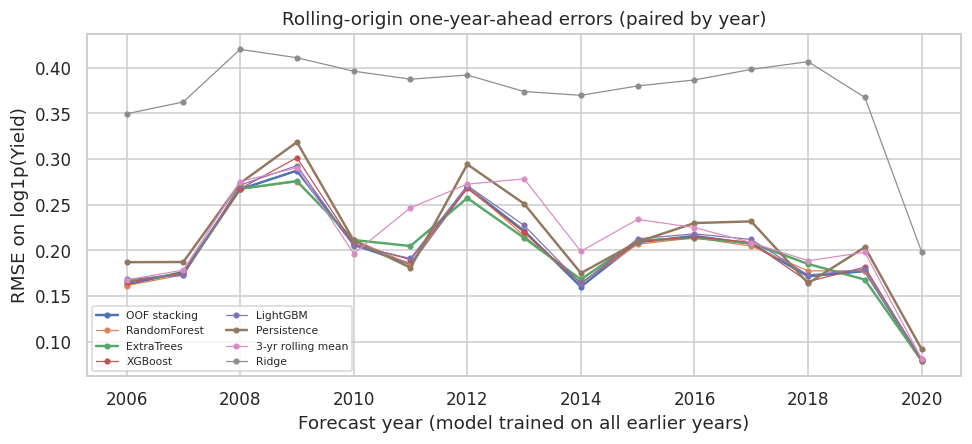

In [43]:
ORIGINS = list(range(2006, 2021))
SIG_MODELS = ['Persistence', '3-yr rolling mean', 'Ridge', 'RandomForest', 'ExtraTrees', 'XGBoost', 'LightGBM', 'OOF stacking']
per_origin = {m: {'RMSE_log': [], 'MAE_log': []} for m in SIG_MODELS}
t0 = time.time()
for Y in ORIGINS:
    tr_i, te_i = df.index[df['Crop_Year'] < Y], df.index[df['Crop_Year'] == Y]
    yt = df.loc[te_i, 'Yield']
    preds = {'Persistence': df.loc[te_i, 'Yield_lag1'].values,
             '3-yr rolling mean': df.loc[te_i, 'Yield_rollmean3'].values}
    for name in ['Ridge', 'RandomForest', 'ExtraTrees', 'XGBoost', 'LightGBM']:
        p = make_pipe(name, TUNED[name]).fit(df.loc[tr_i, NUM_FEATS + CAT_FEATS], df.loc[tr_i, TARGET])
        preds[name] = np.expm1(p.predict(df.loc[te_i, NUM_FEATS + CAT_FEATS]))
    preds['OOF stacking'] = oof_stack(tr_i, te_i, n_splits=3)[0]
    for name, pr in preds.items():
        m = metric_suite(yt, pr)
        per_origin[name]['RMSE_log'].append(m['RMSE_log']); per_origin[name]['MAE_log'].append(m['MAE_log'])
print(f"Rolling-origin evaluation: {len(ORIGINS)} origins x {len(SIG_MODELS)} models in {time.time()-t0:.0f}s")

sig_rmse = pd.DataFrame({m: v['RMSE_log'] for m, v in per_origin.items()}, index=ORIGINS)
sig_mae = pd.DataFrame({m: v['MAE_log'] for m, v in per_origin.items()}, index=ORIGINS)
ranks = sig_rmse.rank(axis=1)
summary_sig = pd.DataFrame({'Mean RMSE_log': sig_rmse.mean(), 'Std': sig_rmse.std(),
                            'Mean rank (1 = best)': ranks.mean(), 'Mean MAE_log': sig_mae.mean()}).sort_values('Mean rank (1 = best)')
display(summary_sig.round(4))

fr = friedmanchisquare(*[sig_rmse[c] for c in sig_rmse.columns])
fr_mae = friedmanchisquare(*[sig_mae[c] for c in sig_mae.columns])
print(f"Friedman omnibus (RMSE_log): chi2 = {fr.statistic:.2f}, p = {fr.pvalue:.2e};  (MAE_log): p = {fr_mae.pvalue:.2e}")

pairs = list(itertools.combinations(summary_sig.index, 2))
pw = []
for a, b in pairs:
    res = wilcoxon(sig_rmse[a], sig_rmse[b], alternative='two-sided')
    d = sig_rmse[a] - sig_rmse[b]
    pw.append({'Model A': a, 'Model B': b, 'Median diff (A-B)': np.median(d), 'A better in': f"{(d < 0).sum()}/{len(d)}",
               'W': res.statistic, 'p_raw': res.pvalue})
pw_df = pd.DataFrame(pw)
pw_df['p_Holm'] = holm(pw_df['p_raw'])
pw_df['Significant (alpha=0.05, Holm)'] = np.where(pw_df['p_Holm'] < 0.05, 'yes', 'no')
display(pw_df.round(4))

fig, ax = plt.subplots(figsize=(9, 4.2))
for c in summary_sig.index:
    ax.plot(ORIGINS, sig_rmse[c], marker='o', ms=3, lw=1.6 if c in ('Persistence', 'OOF stacking', HEADLINE_MODEL) else 0.8, label=c)
ax.set_xlabel('Forecast year (model trained on all earlier years)'); ax.set_ylabel('RMSE on log1p(Yield)')
ax.set_title('Rolling-origin one-year-ahead errors (paired by year)'); ax.legend(fontsize=7, ncol=2)
plt.tight_layout(); plt.show()

def pw_lookup(a, b):
    r = pw_df[((pw_df['Model A'] == a) & (pw_df['Model B'] == b)) | ((pw_df['Model A'] == b) & (pw_df['Model B'] == a))].iloc[0]
    return r['p_raw'], r['p_Holm']
CR['Friedman p (RMSE_log, 15 origins)'] = fr.pvalue
for a, b in [(HEADLINE_MODEL, 'Persistence'), ('OOF stacking', HEADLINE_MODEL), ('OOF stacking', 'Persistence'),
             ('RandomForest', 'ExtraTrees'), ('LightGBM', 'XGBoost')]:
    if a != b:
        CR[f'Wilcoxon {a} vs {b}: p_Holm'] = pw_lookup(a, b)[1]

## R7. Per-Crop, Per-State and Duplicate-Robustness Analysis

### R7.1 Error distributions by crop, state and year

Headline model on the temporal test years. For every crop and state with at least 20 test rows: RMSE_log,
MAE_log, MdAPE, within-group R²_log, persistence RMSE_log on the same rows, and skill over persistence.
Within-group R² is a harder target than pooled R² because the yield spread inside one crop is small.

Crops with >= 20 test rows: 50.  RMSE_log: median 0.148, IQR [0.113, 0.236], min 0.079, max 0.494
   MdAPE (%): median 11.153, IQR [9.150, 14.040], min 5.616, max 23.211;  beats persistence in 72% of crops
States with >= 20 test rows: 30. RMSE_log: median 0.146, IQR [0.105, 0.192], min 0.018, max 0.388
   MdAPE (%): median 9.486, IQR [5.034, 16.047], min 1.318, max 20.950;  beats persistence in 67% of states

Five easiest and five hardest crops:


,Crop,n,RMSE_log,MAE_log,MdAPE_%,R2_log (within group),RMSE_log persistence,Skill_log_vs_persistence
0,Masoor,70,0.079,0.053,6.477,0.600,0.081,0.022
1,Niger seed,41,0.091,0.063,15.086,0.750,0.052,-0.767
2,Rapeseed &Mustard,105,0.093,0.061,8.722,0.851,0.098,0.044
3,Moong(Green Gram),161,0.094,0.063,10.515,0.607,0.110,0.147
4,Rice,239,0.094,0.061,5.616,0.803,0.108,0.129
45,Ginger,69,0.317,0.190,11.229,0.792,0.332,0.044
46,Mesta,39,0.319,0.158,6.862,0.796,0.318,-0.004
47,Sesamum,150,0.344,0.107,11.867,-0.280,0.367,0.062
48,other oilseeds,41,0.414,0.193,11.916,0.579,0.513,0.192
49,Onion,103,0.494,0.269,17.791,0.688,0.484,-0.019


Five easiest and five hardest states:


,State,n,RMSE_log,MAE_log,MdAPE_%,R2_log (within group),RMSE_log persistence,Skill_log_vs_persistence
0,Sikkim,39,0.018,0.012,1.318,0.984,0.007,-1.567
1,Meghalaya,135,0.034,0.023,2.294,0.997,0.032,-0.081
2,Manipur,68,0.052,0.029,2.621,0.997,0.031,-0.707
3,Assam,136,0.056,0.038,4.699,0.999,0.041,-0.350
4,Nagaland,162,0.057,0.024,2.521,0.994,0.071,0.206
25,Delhi,28,0.215,0.120,4.501,0.696,0.218,0.015
26,Tamil Nadu,207,0.227,0.155,17.924,0.977,0.252,0.099
27,Puducherry,161,0.303,0.210,20.950,0.961,0.313,0.031
28,Maharashtra,149,0.371,0.156,19.061,0.723,0.408,0.090
29,Andhra Pradesh,265,0.388,0.198,18.986,0.931,0.408,0.049


,Crop_Year,n,RMSE_log,MAE_log,MdAPE_%,R2_log (within group),RMSE_log persistence,Skill_log_vs_persistence
4,2016,1001,0.2137,0.1164,11.4247,0.9639,0.2299,0.0705
3,2017,1016,0.2105,0.1076,10.1821,0.9652,0.2317,0.0914
2,2018,1054,0.1891,0.0980,9.2028,0.9716,0.1640,-0.1528
1,2019,1051,0.1689,0.0960,10.1272,0.9769,0.2035,0.1702
0,2020,37,0.0813,0.0660,8.8880,0.9900,0.0918,0.1144


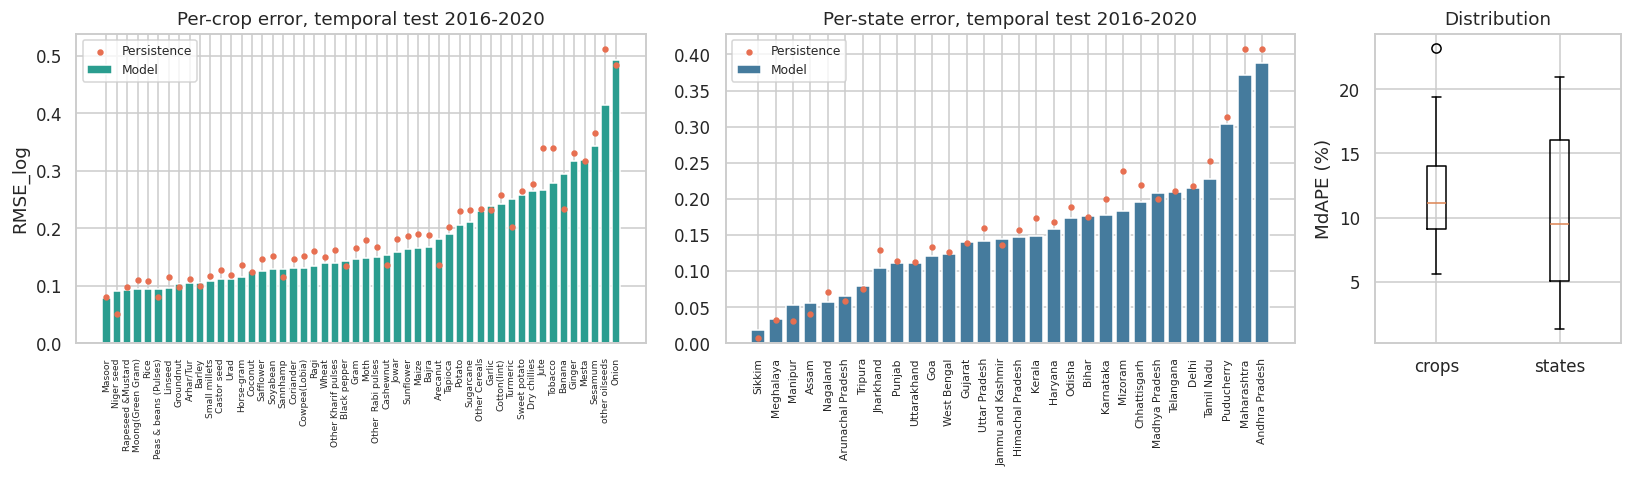

In [44]:
res_T = df.loc[idx_temp_test, ['Crop', 'State', 'Season', 'Crop_Year', 'Yield', 'Yield_lag1', 'Lag_gap_years', 'Series']].copy()
res_T['pred'] = TUNED_PRED_T[HEADLINE_MODEL]
res_T['ae_log'] = np.abs(np.log1p(res_T['pred']) - np.log1p(res_T['Yield']))
res_T['ae_log_persist'] = np.abs(np.log1p(res_T['Yield_lag1']) - np.log1p(res_T['Yield']))

def group_table(key, min_n=20):
    rows = []
    for g, d in res_T.groupby(key):
        if len(d) < min_n: continue
        m = metric_suite(d['Yield'], d['pred']); mp = metric_suite(d['Yield'], d['Yield_lag1'])
        rows.append({key: g, 'n': len(d), 'RMSE_log': m['RMSE_log'], 'MAE_log': m['MAE_log'], 'MdAPE_%': m['MdAPE_%'],
                     'R2_log (within group)': m['R2_log'], 'RMSE_log persistence': mp['RMSE_log'],
                     'Skill_log_vs_persistence': 1 - m['RMSE_log'] / mp['RMSE_log']})
    return pd.DataFrame(rows).sort_values('RMSE_log').reset_index(drop=True)

crop_tab, state_tab = group_table('Crop'), group_table('State')
def dist(s): return f"median {s.median():.3f}, IQR [{s.quantile(.25):.3f}, {s.quantile(.75):.3f}], min {s.min():.3f}, max {s.max():.3f}"
print(f"Crops with >= 20 test rows: {len(crop_tab)}.  RMSE_log: {dist(crop_tab['RMSE_log'])}")
print(f"   MdAPE (%): {dist(crop_tab['MdAPE_%'])};  beats persistence in {(crop_tab['Skill_log_vs_persistence'] > 0).mean():.0%} of crops")
print(f"States with >= 20 test rows: {len(state_tab)}. RMSE_log: {dist(state_tab['RMSE_log'])}")
print(f"   MdAPE (%): {dist(state_tab['MdAPE_%'])};  beats persistence in {(state_tab['Skill_log_vs_persistence'] > 0).mean():.0%} of states")
print("\nFive easiest and five hardest crops:")
display(pd.concat([crop_tab.head(5), crop_tab.tail(5)]).round(3))
print("Five easiest and five hardest states:")
display(pd.concat([state_tab.head(5), state_tab.tail(5)]).round(3))
year_tab = group_table('Crop_Year')
display(year_tab.sort_values('Crop_Year').round(4))

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), gridspec_kw={'width_ratios': [3, 3, 1.3]})
ct = crop_tab.sort_values('RMSE_log')
axes[0].bar(range(len(ct)), ct['RMSE_log'], color='#2a9d8f', label='Model')
axes[0].scatter(range(len(ct)), ct['RMSE_log persistence'], color='#e76f51', s=10, zorder=3, label='Persistence')
axes[0].set_xticks(range(len(ct))); axes[0].set_xticklabels(ct['Crop'], rotation=90, fontsize=6)
axes[0].set_ylabel('RMSE_log'); axes[0].set_title('Per-crop error, temporal test 2016-2020'); axes[0].legend(fontsize=8)
stt = state_tab.sort_values('RMSE_log')
axes[1].bar(range(len(stt)), stt['RMSE_log'], color='#457b9d', label='Model')
axes[1].scatter(range(len(stt)), stt['RMSE_log persistence'], color='#e76f51', s=10, zorder=3, label='Persistence')
axes[1].set_xticks(range(len(stt))); axes[1].set_xticklabels(stt['State'], rotation=90, fontsize=7)
axes[1].set_title('Per-state error, temporal test 2016-2020'); axes[1].legend(fontsize=8)
axes[2].boxplot([crop_tab['MdAPE_%'], state_tab['MdAPE_%']])
axes[2].set_xticks([1, 2]); axes[2].set_xticklabels(['crops', 'states'])
axes[2].set_ylabel('MdAPE (%)'); axes[2].set_title('Distribution')
plt.tight_layout(); plt.show()

CR['Per-crop RMSE_log median [IQR]'] = f"{crop_tab['RMSE_log'].median():.3f} [{crop_tab['RMSE_log'].quantile(.25):.3f}, {crop_tab['RMSE_log'].quantile(.75):.3f}]"
CR['Per-crop MdAPE % median [IQR]'] = f"{crop_tab['MdAPE_%'].median():.1f} [{crop_tab['MdAPE_%'].quantile(.25):.1f}, {crop_tab['MdAPE_%'].quantile(.75):.1f}]"
CR['Share of crops where model beats persistence'] = (crop_tab['Skill_log_vs_persistence'] > 0).mean()
CR['Per-state RMSE_log median [IQR]'] = f"{state_tab['RMSE_log'].median():.3f} [{state_tab['RMSE_log'].quantile(.25):.3f}, {state_tab['RMSE_log'].quantile(.75):.3f}]"
CR['Share of states where model beats persistence'] = (state_tab['Skill_log_vs_persistence'] > 0).mean()

### R7.2 Duplicated and carried-forward observations

Counts test rows whose full feature vector also appears in training, and carried-forward rows (yield identical
to the previous observation). The headline metrics are recomputed without carried-forward rows and without rows
whose previous observation is more than one year back.

In [45]:
key_cols = NUM_FEATS + CAT_FEATS
train_keys = set(map(tuple, df.loc[idx_temp_train, key_cols].round(6).astype(str).values))
dup_feat = np.array([tuple(r) in train_keys for r in df.loc[idx_temp_test, key_cols].round(6).astype(str).values])
carried = np.isclose(res_T['Yield'], res_T['Yield_lag1'])
gap_gt1 = (res_T['Lag_gap_years'] > 1).values
rows_dup = []
for label, mask in [('All temporal test rows', np.ones(len(res_T), bool)),
                    ('Excluding carried-forward yields (Yield == previous yield)', ~carried),
                    ('Excluding rows whose previous observation is > 1 year back', ~gap_gt1),
                    ('Excluding both', ~carried & ~gap_gt1)]:
    d = res_T[mask]
    m = metric_suite(d['Yield'], d['pred'], d['Crop']); mp = metric_suite(d['Yield'], d['Yield_lag1'])
    rows_dup.append({'Subset': label, 'n': len(d), 'R2_log': m['R2_log'], 'RMSE_log': m['RMSE_log'],
                     'R2_raw': m['R2_raw'], 'Skill_log_vs_persistence': 1 - m['RMSE_log'] / mp['RMSE_log']})
print(f"Test rows whose full feature vector also occurs in training: {dup_feat.sum()}")
print(f"Carried-forward test rows (yield identical to previous observation): {carried.sum()} ({carried.mean():.1%}); "
      f"in the whole panel: {np.isclose(df['Yield'], df['Yield_lag1']).mean():.1%}")
display(pd.DataFrame(rows_dup).round(4))
CR['Carried-forward share of panel'] = np.isclose(df['Yield'], df['Yield_lag1']).mean()
CR['Headline R2_log excluding carried-forward rows'] = rows_dup[1]['R2_log']

Test rows whose full feature vector also occurs in training: 0
Carried-forward test rows (yield identical to previous observation): 164 (3.9%); in the whole panel: 2.8%


,Subset,n,R2_log,RMSE_log,R2_raw,Skill_log_vs_persistence
0,All temporal test rows,4159,0.9696,0.1953,0.9816,0.0603
1,Excluding carried-forward yields (Yield == previous yield),3995,0.9693,0.1986,0.9816,0.0637
2,Excluding rows whose previous observation is > 1 year back,4027,0.9719,0.1893,0.9816,0.0573
3,Excluding both,3866,0.9717,0.1924,0.9816,0.0611


## R8. Crop and Crop-Family Transferability

1. **Leave-one-crop-out** for the 8 crops of Section 16 and for all crops with ≥ 20 rows.
2. **Leave-one-crop-family-out** for the 5 KMeans families of Section 17.
3. **Candidate causes** for each held-out crop:
   - out-of-support share (lag values outside the training 1–99% range);
   - level gap (|median log-yield difference| / training IQR);
   - Kolmogorov–Smirnov statistics for rainfall, area and fertilizer rate;
   - rare-season share;
   - intrinsic volatility (persistence RMSE_log of the crop).

   Spearman correlations relate each cause to the transfer error and to the excess error over persistence.
4. **Growth-rate target.** Δ = log1p(Yield) − log1p(Yield_lag1), back-transformed as log1p(Yield_lag1) + Δ̂. It
   is compared with the level target in every setting.

(a) Original 8-crop LOCO (Fig. 11), level vs growth-rate target:


,Crop,n,"R2_raw (level, as in Fig. 11)",R2_log level,R2_log growth,RMSE_log level,RMSE_log growth,RMSE_log persistence,Out-of-support share (lag outside train 1-99%),Level gap (|median log-yield diff| / train IQR)
6,Sugarcane,560,-0.358,0.449,0.674,0.740,0.569,0.411,0.780,4.471
0,Cotton(lint),429,0.591,0.573,0.591,0.261,0.256,0.251,0.159,0.286
4,Potato,564,0.291,0.688,0.661,0.295,0.307,0.279,0.005,2.149
5,Rice,1120,0.627,0.697,0.718,0.136,0.131,0.139,0.003,0.049
1,Groundnut,674,0.730,0.701,0.693,0.136,0.138,0.107,0.010,0.411
2,Maize,906,0.633,0.781,0.777,0.174,0.176,0.190,0.001,0.124
3,Onion,395,0.202,0.782,0.766,0.354,0.367,0.362,0.008,1.571
7,Wheat,510,0.861,0.813,0.824,0.142,0.138,0.135,0.008,0.203



(b) LOCO over all crops with >= 20 rows (54 crops, 56s):
   level target : R2_log median 0.712, min -201.121; RMSE_log median 0.161
   growth target: R2_log median 0.695, min -10.018; RMSE_log median 0.164
   growth target lowers RMSE_log for 41% of crops


,Crop,n,R2_log level,R2_log growth,RMSE_log level,RMSE_log growth,RMSE_log persistence,Out-of-support share (lag outside train 1-99%),KS rainfall,Volatility (persistence RMSE_log)
0,Coconut,155,-201.121,-10.018,5.320,1.242,0.128,1.000,0.251,0.128
1,Cardamom,68,-0.735,-0.688,0.225,0.222,0.172,0.838,0.177,0.172
2,Cashewnut,120,-0.511,-0.767,0.652,0.705,0.708,0.008,0.284,0.708
3,Sesamum,632,-0.333,-0.313,0.290,0.288,0.290,0.022,0.044,0.290
4,Guar seed,50,-0.315,-0.359,0.166,0.169,0.181,0.000,0.626,0.181
5,Khesari,68,0.274,0.238,0.109,0.112,0.133,0.000,0.177,0.133
6,Other Cereals,126,0.285,0.268,0.198,0.200,0.209,0.016,0.105,0.209
7,Niger seed,171,0.286,0.344,0.156,0.150,0.183,0.018,0.119,0.183
50,Garlic,223,0.870,0.877,0.230,0.224,0.251,0.000,0.187,0.251
51,Barley,278,0.873,0.870,0.121,0.122,0.127,0.000,0.155,0.127



(c) Leave-one-crop-FAMILY-out (5 KMeans families from Section 17):


,CropCluster,Family members,n,R2_log level,R2_log growth,RMSE_log level,RMSE_log growth,RMSE_log persistence,Out-of-support share (lag outside train 1-99%)
2,2,Coconut ...,155,-201.121,-10.018,5.320,1.242,0.128,1.000
4,4,"Banana, Jute, Onion, Potato, Sugarcane, Tapioca ...",2074,0.192,0.484,0.846,0.675,0.327,0.179
0,0,"Arecanut, Barley, Black pepper, Cardamom, Cashewnut, Castor seed ...",7458,0.688,0.677,0.195,0.198,0.194,0.044
1,1,"Arhar/Tur, Bajra, Cotton(lint), Gram, Groundnut, Jowar ...",6427,0.836,0.833,0.157,0.158,0.161,0.002
3,3,"Cowpea(Lobia), Garlic, Ginger, Mesta, Moth, Other Cereals ...",1806,0.899,0.900,0.261,0.260,0.270,0.017


,Candidate cause,Spearman rho with RMSE_log (level),Spearman rho with excess error over persistence
0,Out-of-support share (lag outside train 1-99%),0.070,0.253
1,Level gap (|median log-yield diff| / train IQR),0.495,0.535
2,KS rainfall,0.185,-0.134
3,KS area (log),0.290,-0.128
4,KS fertilizer rate,0.114,0.006
5,Rare-season share (<5% of train),-0.136,0.223
6,Volatility (persistence RMSE_log),0.904,-0.141


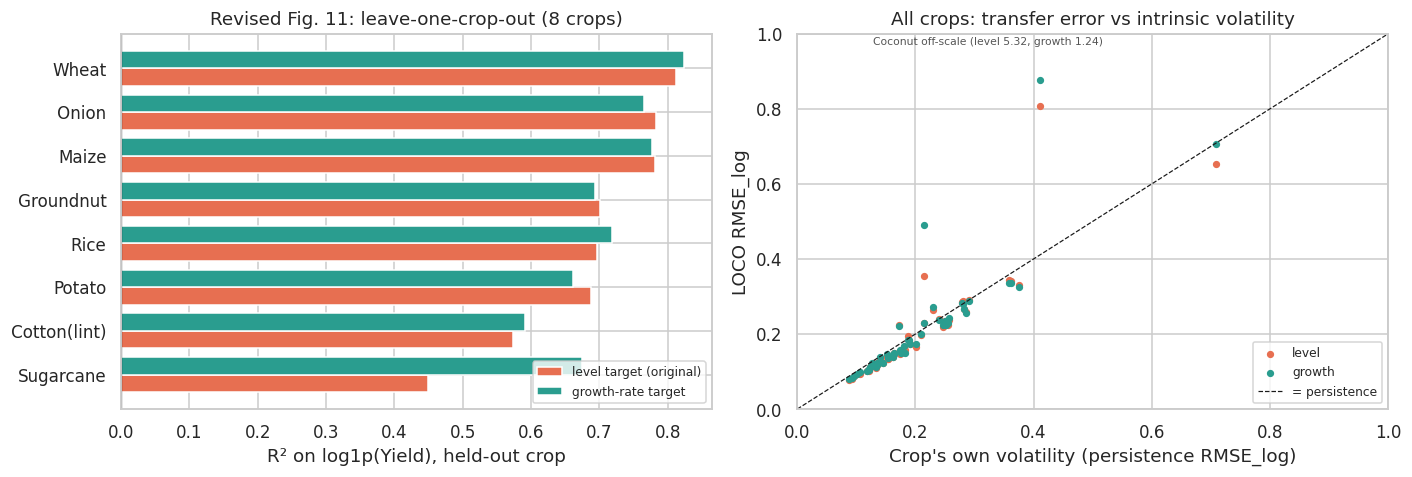

In [46]:
df['Growth_target'] = df[TARGET] - np.log1p(df['Yield_lag1'])

def loco_predict(train_idx, test_idx, target='level', data=None):
    d = df if data is None else data
    pipe = Pipeline([('pre', make_pre(NUM_FEATS)), ('mdl', default_lgb())])
    if target == 'level':
        pipe.fit(d.loc[train_idx, NUM_FEATS + CAT_FEATS], d.loc[train_idx, TARGET])
        return np.expm1(pipe.predict(d.loc[test_idx, NUM_FEATS + CAT_FEATS]))
    pipe.fit(d.loc[train_idx, NUM_FEATS + CAT_FEATS], d.loc[train_idx, 'Growth_target'])
    return np.expm1(np.log1p(d.loc[test_idx, 'Yield_lag1']) + pipe.predict(d.loc[test_idx, NUM_FEATS + CAT_FEATS]))

def transfer_causes(train_idx, test_idx):
    tr, te = df.loc[train_idx], df.loc[test_idx]
    lag_tr, lag_te = np.log1p(tr['Yield_lag1']), np.log1p(te['Yield_lag1'])
    lo, hi = lag_tr.quantile(0.01), lag_tr.quantile(0.99)
    iqr = lag_tr.quantile(0.75) - lag_tr.quantile(0.25)
    season_share = tr['Season'].value_counts(normalize=True)
    return {'Out-of-support share (lag outside train 1-99%)': ((lag_te < lo) | (lag_te > hi)).mean(),
            'Level gap (|median log-yield diff| / train IQR)': abs(lag_te.median() - lag_tr.median()) / iqr,
            'KS rainfall': ks_2samp(tr['Annual_Rainfall'], te['Annual_Rainfall']).statistic,
            'KS area (log)': ks_2samp(tr['Area_log'], te['Area_log']).statistic,
            'KS fertilizer rate': ks_2samp(tr['Fertilizer_per_ha'], te['Fertilizer_per_ha']).statistic,
            'Rare-season share (<5% of train)': te['Season'].map(season_share).fillna(0).lt(0.05).mean(),
            'Volatility (persistence RMSE_log)': metric_suite(te['Yield'], te['Yield_lag1'])['RMSE_log']}

def loco_table(pool_idx, group_col, groups=None):
    rows = []
    pool = df.loc[pool_idx]
    for g in (groups if groups is not None else sorted(pool[group_col].unique())):
        te_i = pool.index[pool[group_col] == g]; tr_i = pool.index[pool[group_col] != g]
        if len(te_i) < 20: continue
        yt = df.loc[te_i, 'Yield']
        m_lv = metric_suite(yt, loco_predict(tr_i, te_i, 'level'))
        m_gr = metric_suite(yt, loco_predict(tr_i, te_i, 'growth'))
        m_ps = metric_suite(yt, df.loc[te_i, 'Yield_lag1'])
        rows.append({group_col: g, 'n': len(te_i),
                     'R2_raw (level, as in Fig. 11)': m_lv['R2_raw'],
                     'R2_log level': m_lv['R2_log'], 'RMSE_log level': m_lv['RMSE_log'],
                     'R2_log growth': m_gr['R2_log'], 'RMSE_log growth': m_gr['RMSE_log'],
                     'RMSE_log persistence': m_ps['RMSE_log'], **transfer_causes(tr_i, te_i)})
    return pd.DataFrame(rows)

sample_crops = ['Rice', 'Wheat', 'Maize', 'Cotton(lint)', 'Groundnut', 'Sugarcane', 'Potato', 'Onion']
loco8 = loco_table(df.index[df['Crop'].isin(sample_crops)], 'Crop').sort_values('R2_log level')
print("(a) Original 8-crop LOCO (Fig. 11), level vs growth-rate target:")
display(loco8[['Crop', 'n', 'R2_raw (level, as in Fig. 11)', 'R2_log level', 'R2_log growth', 'RMSE_log level',
               'RMSE_log growth', 'RMSE_log persistence', 'Out-of-support share (lag outside train 1-99%)',
               'Level gap (|median log-yield diff| / train IQR)']].round(3))

t0 = time.time()
loco55 = loco_table(df.index, 'Crop').sort_values('R2_log level').reset_index(drop=True)
print(f"\n(b) LOCO over all crops with >= 20 rows ({len(loco55)} crops, {time.time()-t0:.0f}s):")
print(f"   level target : R2_log median {loco55['R2_log level'].median():.3f}, min {loco55['R2_log level'].min():.3f}; "
      f"RMSE_log median {loco55['RMSE_log level'].median():.3f}")
print(f"   growth target: R2_log median {loco55['R2_log growth'].median():.3f}, min {loco55['R2_log growth'].min():.3f}; "
      f"RMSE_log median {loco55['RMSE_log growth'].median():.3f}")
print(f"   growth target lowers RMSE_log for {(loco55['RMSE_log growth'] < loco55['RMSE_log level']).mean():.0%} of crops")
display(pd.concat([loco55.head(8), loco55.tail(4)])[['Crop', 'n', 'R2_log level', 'R2_log growth', 'RMSE_log level',
        'RMSE_log growth', 'RMSE_log persistence', 'Out-of-support share (lag outside train 1-99%)', 'KS rainfall',
        'Volatility (persistence RMSE_log)']].round(3))

lofo = loco_table(df.index, 'CropCluster').sort_values('R2_log level')
lofo['Family members'] = lofo['CropCluster'].map(lambda c: ', '.join(sorted(df.loc[df.CropCluster == c, 'Crop'].unique())[:6]) + ' ...')
print("\n(c) Leave-one-crop-FAMILY-out (5 KMeans families from Section 17):")
display(lofo[['CropCluster', 'Family members', 'n', 'R2_log level', 'R2_log growth', 'RMSE_log level', 'RMSE_log growth',
              'RMSE_log persistence', 'Out-of-support share (lag outside train 1-99%)']].round(3))

cause_cols = ['Out-of-support share (lag outside train 1-99%)', 'Level gap (|median log-yield diff| / train IQR)', 'KS rainfall', 'KS area (log)', 'KS fertilizer rate',
              'Rare-season share (<5% of train)', 'Volatility (persistence RMSE_log)']
excess = loco55['RMSE_log level'] - loco55['RMSE_log persistence']
cause_df = pd.DataFrame([{'Candidate cause': c,
                          'Spearman rho with RMSE_log (level)': spearmanr(loco55[c], loco55['RMSE_log level']).correlation,
                          'Spearman rho with excess error over persistence': spearmanr(loco55[c], excess).correlation}
                         for c in cause_cols])
display(cause_df.round(3))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
l8 = loco8.sort_values('R2_log level')
yy = np.arange(len(l8))
axes[0].barh(yy - 0.2, l8['R2_log level'], height=0.4, color='#e76f51', label='level target (original)')
axes[0].barh(yy + 0.2, l8['R2_log growth'], height=0.4, color='#2a9d8f', label='growth-rate target')
axes[0].set_yticks(yy); axes[0].set_yticklabels(l8['Crop']); axes[0].axvline(0, color='k', lw=0.8)
axes[0].set_xlabel('R² on log1p(Yield), held-out crop'); axes[0].set_title('Revised Fig. 11: leave-one-crop-out (8 crops)')
axes[0].legend(fontsize=8)
axes[1].scatter(loco55['Volatility (persistence RMSE_log)'], loco55['RMSE_log level'], s=14, color='#e76f51', label='level')
axes[1].scatter(loco55['Volatility (persistence RMSE_log)'], loco55['RMSE_log growth'], s=14, color='#2a9d8f', label='growth')
lim = [0, 1.0]
axes[1].plot(lim, lim, 'k--', lw=0.8, label='= persistence')
axes[1].set_xlim(lim); axes[1].set_ylim(lim)
off = loco55[(loco55['RMSE_log level'] > 1) | (loco55['RMSE_log growth'] > 1)]
for _, r in off.iterrows():
    axes[1].annotate(f"{r['Crop']} off-scale (level {r['RMSE_log level']:.2f}, growth {r['RMSE_log growth']:.2f})",
                     xy=(r['Volatility (persistence RMSE_log)'], 0.97), fontsize=7, ha='left', color='#555')
axes[1].set_xlabel("Crop's own volatility (persistence RMSE_log)"); axes[1].set_ylabel('LOCO RMSE_log')
axes[1].set_title('All crops: transfer error vs intrinsic volatility'); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

CR['LOCO-8 Sugarcane R2_log level -> growth'] = (f"{loco8.set_index('Crop').loc['Sugarcane', 'R2_log level']:.3f} -> "
                                                 f"{loco8.set_index('Crop').loc['Sugarcane', 'R2_log growth']:.3f}")
CR['LOCO-8 median R2_log level / growth'] = f"{loco8['R2_log level'].median():.3f} / {loco8['R2_log growth'].median():.3f}"
CR['LOCO-55 median R2_log level / growth'] = f"{loco55['R2_log level'].median():.3f} / {loco55['R2_log growth'].median():.3f}"
CR['LOFO (families) R2_log level range'] = f"{lofo['R2_log level'].min():.3f} to {lofo['R2_log level'].max():.3f}"
CR['LOFO (families) R2_log growth range'] = f"{lofo['R2_log growth'].min():.3f} to {lofo['R2_log growth'].max():.3f}"

**Interpretation.** Transfer error tracks each crop's intrinsic volatility. The error a model adds beyond
persistence is associated with the yield-level gap between the held-out crop and the training crops. It is not
associated with the rainfall, area or input-rate shifts. The growth-rate target reduces the error for crops and
families whose level lies outside the training range (Sugarcane, Coconut, the Sugarcane/Potato/Banana family).
It leaves the other crops essentially unchanged.

## R9. Conformal Intervals: Width, Conditional Coverage and Shift

**Methods** (all use the finite-sample conformal quantile, with the headline model from R4):

- **A. Raw absolute residual:** one additive width for all crops (method of Section 15).
- **B. Log-scale absolute residual:** interval [expm1(ŷ_log − q), expm1(ŷ_log + q)], i.e. a multiplicative band.
- **C. Mondrian log-scale:** a separate quantile per crop (≥ 30 calibration points, otherwise B).

**Settings:**

- **Random (reference):** the proper-training, calibration and test partitions of Section 15.
- **Temporal shift:** fit < 2013, calibrate 2013–2015, test 2016–2020.
- **Spatial shift:** `GroupKFold(5)` over states. Test states are unseen. Calibration uses 20% of the remaining
  states (`GroupShuffleSplit`), held out from fitting.

**Reported:** marginal coverage, mean and median width (raw units), median relative width (width / ŷ), worst-crop
coverage, share of crops within 5 percentage points of the target, worst-state coverage, and the lowest and
highest coverage across true-yield quintiles.

,Setting,Target,Method,Coverage,Mean width (raw),Median width (raw),Median relative width,Worst crop cov.,Crops within 5pp,Worst state cov.,Worst yield-quintile cov.,Best yield-quintile cov.
0,Random (reference),0.80,A raw-abs,0.802,0.911,0.921,0.860,0.000,0.723,0.485,0.326,0.971
1,Random (reference),0.80,B log-abs,0.802,21.898,0.575,0.536,0.557,0.638,0.552,0.661,0.898
2,Random (reference),0.80,C Mondrian log (per crop),0.806,22.339,0.599,0.527,0.607,0.766,0.560,0.753,0.876
3,Random (reference),0.90,A raw-abs,0.906,2.319,2.400,2.240,0.000,0.809,0.606,0.566,0.996
4,Random (reference),0.90,B log-abs,0.898,33.943,0.891,0.831,0.747,0.766,0.636,0.798,0.954
5,Random (reference),0.90,C Mondrian log (per crop),0.903,35.257,0.946,0.807,0.750,0.809,0.698,0.861,0.946
6,Random (reference),0.95,A raw-abs,0.944,4.729,4.296,4.010,0.000,0.809,0.697,0.731,0.999
7,Random (reference),0.95,B log-abs,0.949,50.279,1.319,1.231,0.797,0.787,0.727,0.872,0.989
8,Random (reference),0.95,C Mondrian log (per crop),0.950,52.864,1.330,1.175,0.839,0.851,0.758,0.921,0.972
9,Temporal shift,0.80,A raw-abs,0.800,1.136,1.158,0.977,0.000,0.720,0.578,0.274,0.987


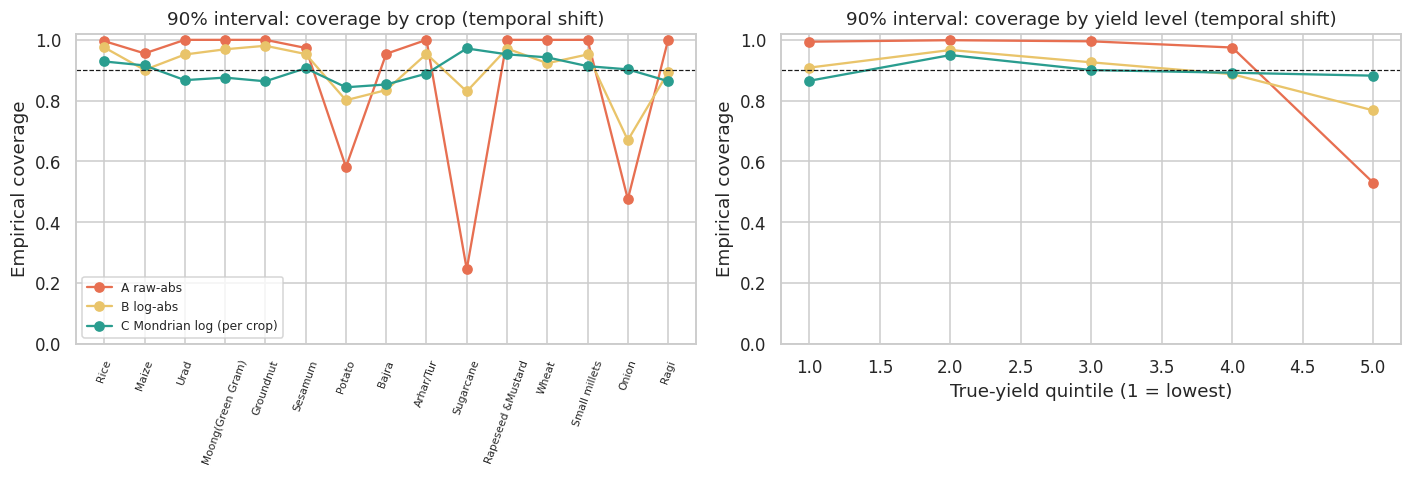

In [47]:
HEAD_PARAMS = TUNED[HEADLINE_MODEL]

def conformal_eval(tr_i, cal_i, te_i, alphas=(0.20, 0.10, 0.05), store=None):
    pipe = make_pipe(HEADLINE_MODEL, HEAD_PARAMS).fit(df.loc[tr_i, NUM_FEATS + CAT_FEATS], df.loc[tr_i, TARGET])
    pc = pipe.predict(df.loc[cal_i, NUM_FEATS + CAT_FEATS]); pt = pipe.predict(df.loc[te_i, NUM_FEATS + CAT_FEATS])
    yc, yt = df.loc[cal_i, 'Yield'].values, df.loc[te_i, 'Yield'].values
    crop_c, crop_t = df.loc[cal_i, 'Crop'].values, df.loc[te_i, 'Crop'].values
    s_raw = np.abs(yc - np.expm1(pc)); s_log = np.abs(np.log1p(yc) - pc)
    out = []
    for a in alphas:
        bands = {}
        q = conformal_q(s_raw, a); bands['A raw-abs'] = (np.clip(np.expm1(pt) - q, 0, None), np.expm1(pt) + q)
        q = conformal_q(s_log, a); bands['B log-abs'] = (np.expm1(pt - q), np.expm1(pt + q))
        qg = conformal_q(s_log, a)
        qc = np.array([conformal_q(s_log[crop_c == c], a) if (crop_c == c).sum() >= 30 else qg for c in crop_t])
        qc = np.where(np.isfinite(qc), qc, qg)
        bands['C Mondrian log (per crop)'] = (np.expm1(pt - qc), np.expm1(pt + qc))
        for meth, (lo, hi) in bands.items():
            cov = (yt >= lo) & (yt <= hi); w = hi - lo
            g = pd.DataFrame({'cov': cov, 'crop': crop_t, 'state': df.loc[te_i, 'State'].values,
                              'yq': pd.qcut(yt, 5, labels=False, duplicates='drop')})
            by_crop = g.groupby('crop')['cov'].agg(['mean', 'size']).query('size >= 20')['mean']
            by_state = g.groupby('state')['cov'].agg(['mean', 'size']).query('size >= 20')['mean']
            by_yq = g.groupby('yq')['cov'].mean()
            out.append({'Target': 1 - a, 'Method': meth, 'Coverage': cov.mean(),
                        'Mean width (raw)': w.mean(), 'Median width (raw)': np.median(w),
                        'Median relative width': np.median(w / np.expm1(pt).clip(1e-6)),
                        'Worst crop cov.': by_crop.min(), 'Crops within 5pp': (by_crop >= (1 - a) - 0.05).mean(),
                        'Worst state cov.': by_state.min(), 'Worst yield-quintile cov.': by_yq.min(),
                        'Best yield-quintile cov.': by_yq.max()})
            if store is not None and a == 0.10:
                store[meth] = g.assign(width=w, y=yt, pred=np.expm1(pt))
    return pd.DataFrame(out)

conf_tables, conf_store = {}, {}
conf_tables['Random (reference)'] = conformal_eval(X_tr3.index, X_cal.index, X_test.index)
conf_tables['Temporal shift'] = conformal_eval(idx_inner_tr, idx_inner_val, idx_temp_test, store=conf_store)
sp = []
for k, (rest_i, te_i) in enumerate(GroupKFold(n_splits=5).split(df, groups=df['State'])):
    rest = df.index[rest_i]
    gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=RANDOM_STATE + k)
    a_i, b_i = next(gss.split(rest, groups=df.loc[rest, 'State']))
    sp.append(conformal_eval(rest[a_i], rest[b_i], df.index[te_i]).assign(Fold=k))
sp = pd.concat(sp)
conf_tables['Spatial shift (5 state folds, mean)'] = sp.groupby(['Target', 'Method'], as_index=False).mean(numeric_only=True).drop(columns='Fold')

conf_all = pd.concat([t.assign(Setting=s) for s, t in conf_tables.items()])
show = ['Setting', 'Target', 'Method', 'Coverage', 'Mean width (raw)', 'Median width (raw)', 'Median relative width',
        'Worst crop cov.', 'Crops within 5pp', 'Worst state cov.', 'Worst yield-quintile cov.', 'Best yield-quintile cov.']
display(conf_all[show].round(3).reset_index(drop=True))

for s in conf_tables:
    for meth in ['B log-abs', 'C Mondrian log (per crop)']:
        r = conf_tables[s].query('Target == 0.95 and Method == @meth').iloc[0]
        CR[f'Conformal 95% [{s}] {meth}: coverage'] = r['Coverage']
        CR[f'Conformal 95% [{s}] {meth}: worst-crop coverage'] = r['Worst crop cov.']
    CR[f'Conformal 95% [{s}] {meth}: median relative width'] = r['Median relative width']

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
top_crops_cov = df.loc[idx_temp_test, 'Crop'].value_counts().head(15).index
for meth, col in [('A raw-abs', '#e76f51'), ('B log-abs', '#e9c46a'), ('C Mondrian log (per crop)', '#2a9d8f')]:
    g = conf_store[meth]
    cc = g[g['crop'].isin(top_crops_cov)].groupby('crop')['cov'].mean().reindex(top_crops_cov)
    axes[0].plot(range(len(cc)), cc.values, marker='o', color=col, label=meth)
    yq = g.groupby('yq')['cov'].mean()
    axes[1].plot(yq.index + 1, yq.values, marker='o', color=col, label=meth)
for ax in axes: ax.axhline(0.9, color='k', ls='--', lw=0.8); ax.set_ylim(0, 1.02); ax.set_ylabel('Empirical coverage')
axes[0].set_xticks(range(len(top_crops_cov))); axes[0].set_xticklabels(top_crops_cov, rotation=70, fontsize=7)
axes[0].set_title('90% interval: coverage by crop (temporal shift)'); axes[0].legend(fontsize=8)
axes[1].set_xlabel('True-yield quintile (1 = lowest)'); axes[1].set_title('90% interval: coverage by yield level (temporal shift)')
plt.tight_layout(); plt.show()

**Interpretation.** Method A meets the marginal target but is too wide for low-yield crops and too narrow for
high-yield crops, so its coverage varies strongly across yield quintiles and it almost never covers Coconut.
Methods B and C give widths proportional to the yield level. C also brings most individual crops close to the
target. Under temporal and spatial shift, exchangeability does not hold, and the table shows the resulting
deviation from the target.

## R10. Local and Group-Wise SHAP

Exact TreeSHAP on the tuned LightGBM trained on years ≤ 2015 (R4). LightGBM is used because TreeSHAP on the
headline tree ensemble is much slower, and R6 shows the tuned tree models are statistically indistinguishable.
One-hot columns are summed back into Crop, Season and State, so all 11 inputs are compared directly.

1. Global mean |SHAP| on the 2016–2020 test rows.
2. Waterfall explanations for four predictions: Rice in Punjab and Wheat in Uttar Pradesh (typical error), a
   typical Coconut row, and the largest error in the test years.
3. Share of mean |SHAP| by crop (12 most frequent), by state (n ≥ 80) and by period (1998–2005, 2006–2010,
   2011–2015 sampled from training years; 2016–2020 test), with Kendall's W for agreement of feature rankings
   across groups.

Global mean |SHAP| on the temporal test years (one-hot groups summed):


,share of total |SHAP|
Yield_lag1,0.4485
Yield_rollmean3,0.4071
Crop,0.0913
State,0.0096
Area_log,0.0093
Crop_Year,0.0091
Annual_Rainfall,0.0075
Season,0.0059
Fertilizer_per_ha,0.0058
Rainfall_x_Fert,0.0041


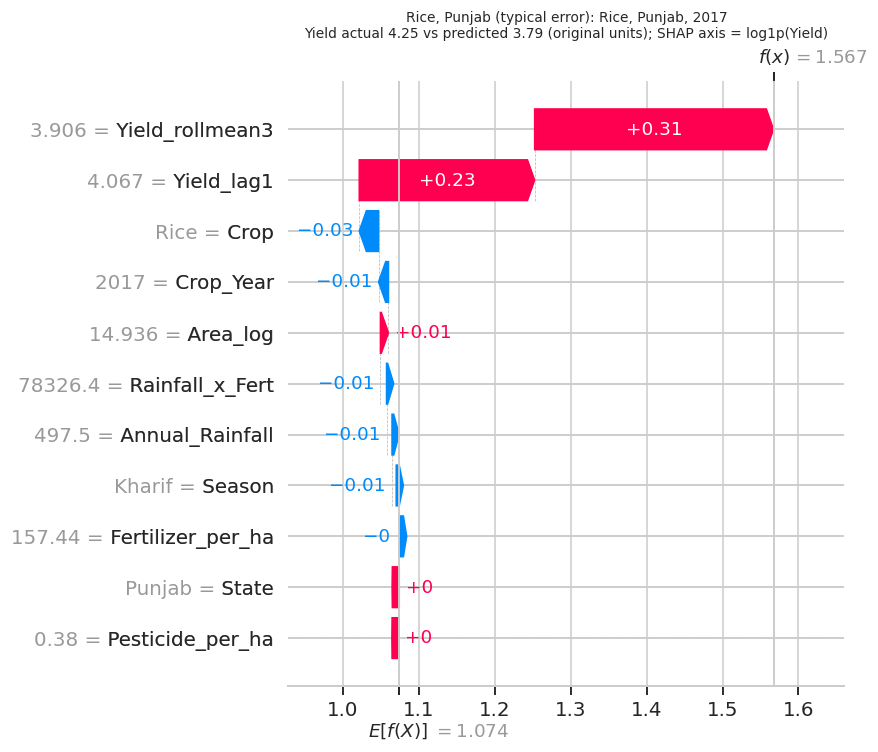

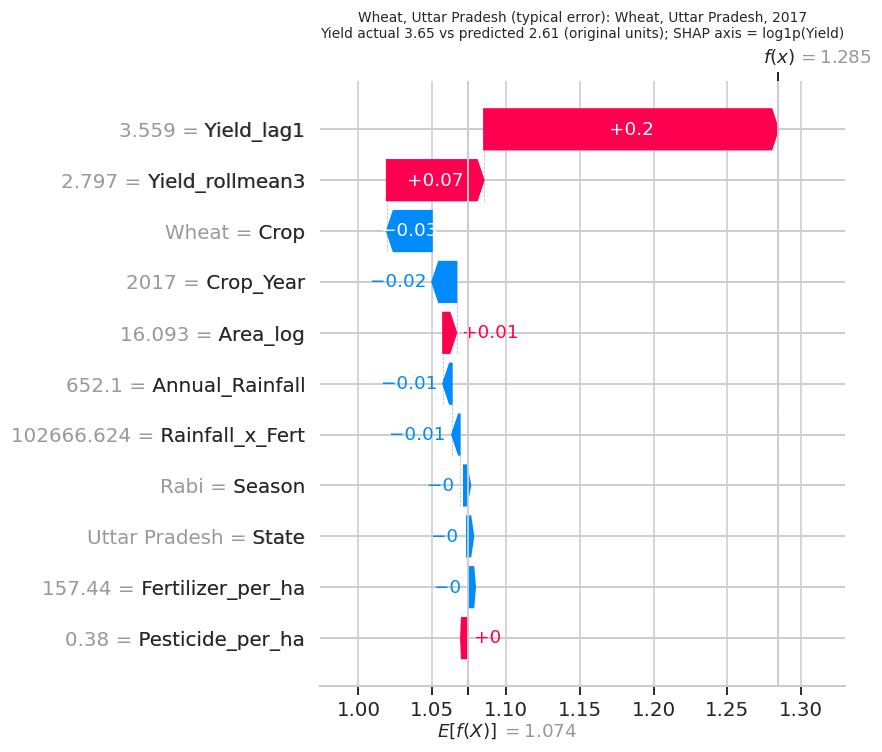

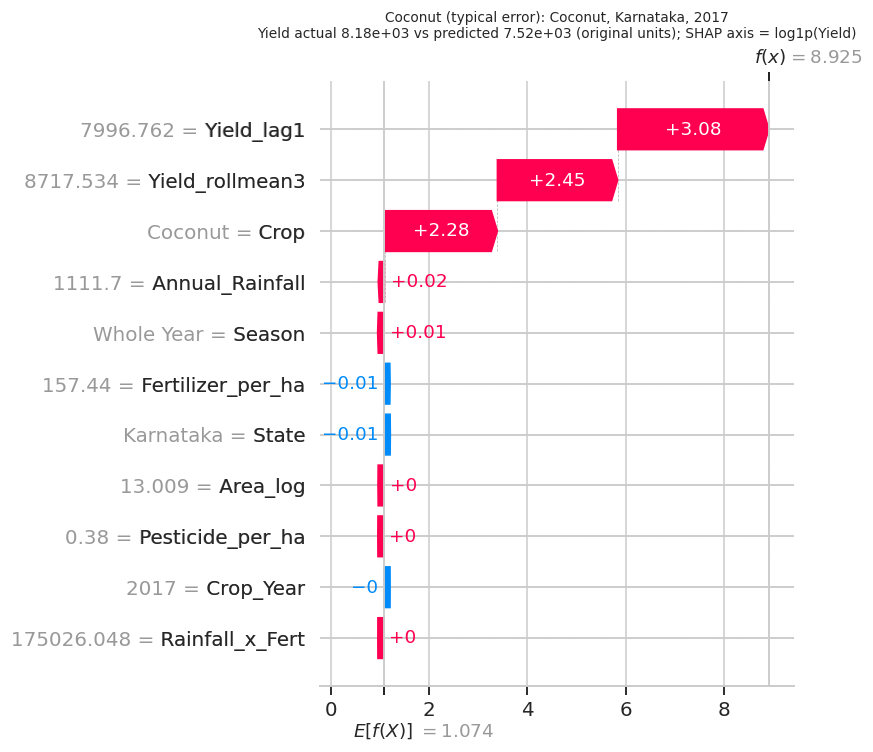

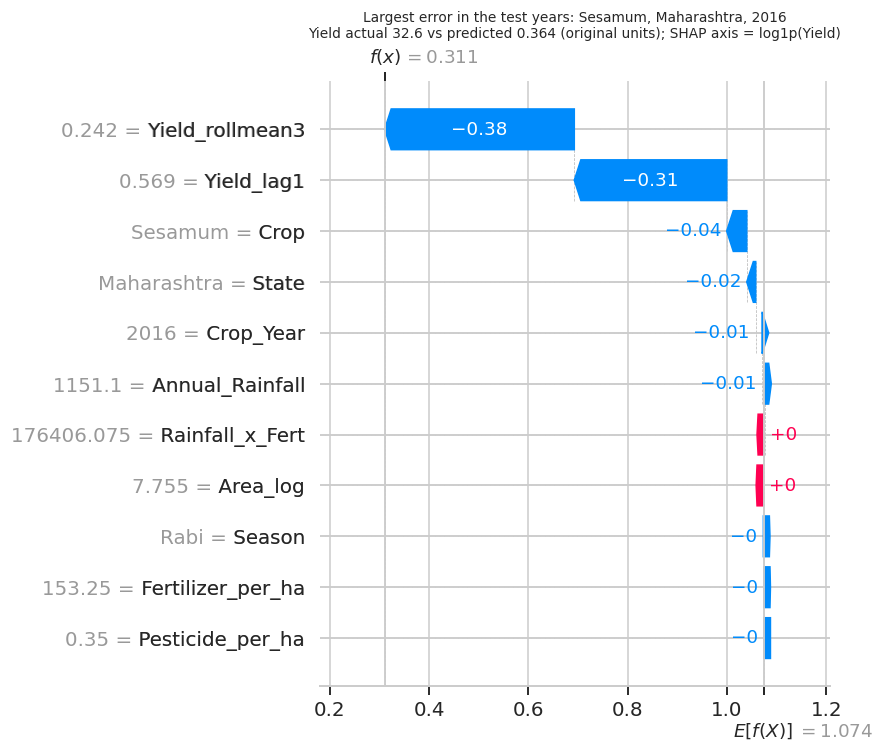

,Grouping,Groups,Kendall's W,Share of groups whose top-2 = lag1 & rollmean3,History share of |SHAP|: min,median,max,Most frequent #3 feature
0,Crops (12 most frequent),12,0.900,1.0,0.750,0.858,0.964,Crop
1,States (n >= 80),24,0.804,1.0,0.807,0.865,0.902,Crop
2,Periods (4),4,0.901,1.0,0.856,0.865,0.870,Crop


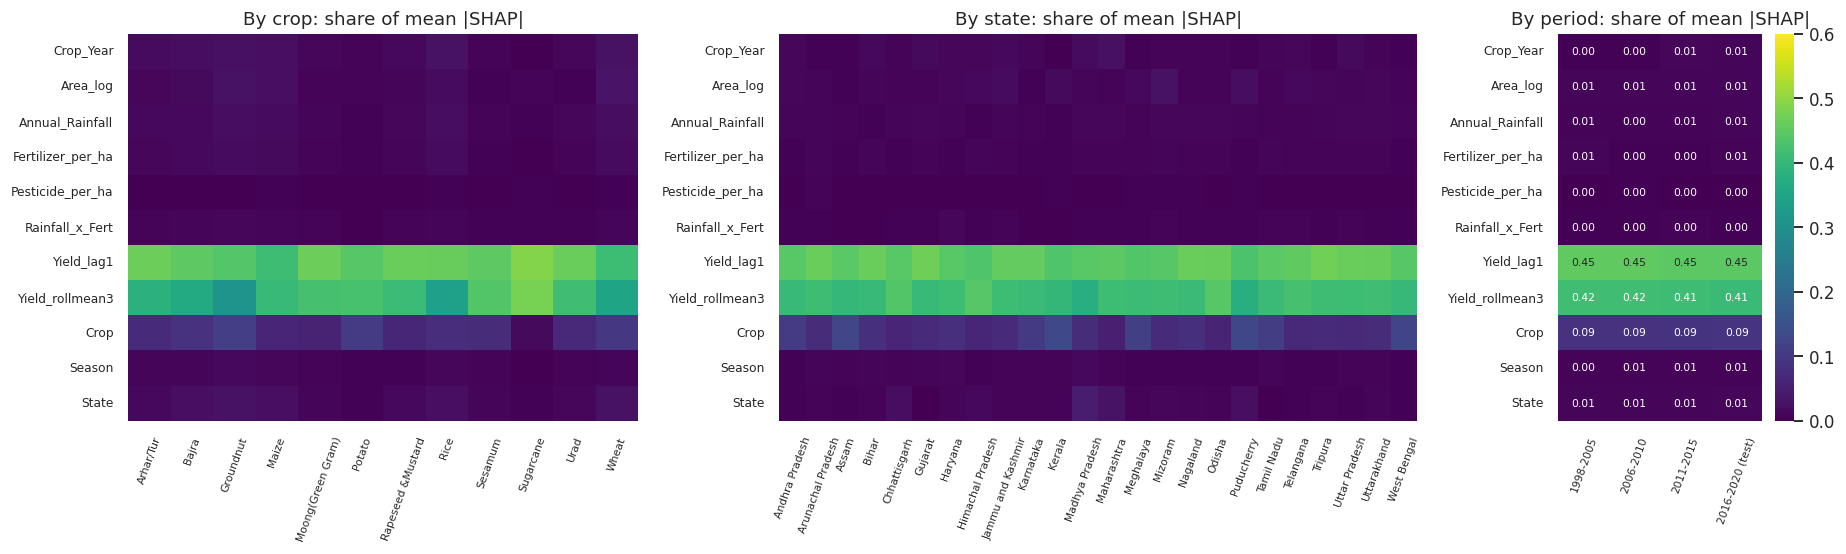

In [48]:
shap_pipe = TUNED_PIPES_T['LightGBM']
pre_s, mdl_s = shap_pipe.named_steps['pre'], shap_pipe.named_steps['mdl']
fn = pre_s.get_feature_names_out()
def orig_feature(f):
    if f.startswith('num__'): return f[5:]
    base = f[5:]
    return next(c for c in CAT_FEATS if base.startswith(c + '_'))
fmap = [orig_feature(f) for f in fn]
FEAT_ORDER = NUM_FEATS + CAT_FEATS
explainer_s = shap.TreeExplainer(mdl_s)
base_value = float(np.ravel(explainer_s.expected_value)[0])

def grouped_shap(idx):
    Xt = pre_s.transform(df.loc[idx, NUM_FEATS + CAT_FEATS])
    Xt = Xt.toarray() if hasattr(Xt, 'toarray') else Xt
    sv = explainer_s.shap_values(Xt)
    return pd.DataFrame(sv, columns=fn, index=idx).T.groupby(fmap).sum().T[FEAT_ORDER]

S_test = grouped_shap(idx_temp_test)
period_bins = {'1998-2005': (1998, 2005), '2006-2010': (2006, 2010), '2011-2015': (2011, 2015)}
S_period = {}
for lab, (a, b) in period_bins.items():
    ix = df.index[(df.Crop_Year >= a) & (df.Crop_Year <= b)]
    S_period[lab] = grouped_shap(pd.Index(np.random.RandomState(RANDOM_STATE).choice(ix, size=min(1500, len(ix)), replace=False)))
S_period['2016-2020 (test)'] = S_test

glob = S_test.abs().mean().sort_values(ascending=False)
print("Global mean |SHAP| on the temporal test years (one-hot groups summed):")
display((glob / glob.sum()).rename('share of total |SHAP|').round(4).to_frame())
CR['SHAP share: Yield_lag1 + Yield_rollmean3 (temporal test)'] = (glob[['Yield_lag1', 'Yield_rollmean3']].sum() / glob.sum())

res_L = df.loc[idx_temp_test, ['Crop', 'State', 'Crop_Year', 'Yield']].copy()
res_L['pred'] = np.expm1(shap_pipe.predict(df.loc[idx_temp_test, NUM_FEATS + CAT_FEATS]))
res_L['abs_log_err'] = np.abs(np.log1p(res_L['pred']) - np.log1p(res_L['Yield']))
def median_error_row(mask):
    d = res_L[mask]; return (d['abs_log_err'] - d['abs_log_err'].median()).abs().idxmin()
cases = {}
for crop_, state_ in [('Rice', 'Punjab'), ('Wheat', 'Uttar Pradesh')]:
    m_ = (res_L.Crop == crop_) & (res_L.State == state_)
    cases[f'{crop_}, {state_} (typical error)'] = median_error_row(m_ if m_.any() else res_L.Crop == crop_)
cases['Coconut (typical error)'] = median_error_row(res_L.Crop == 'Coconut')
cases['Largest error in the test years'] = res_L['abs_log_err'].idxmax()
for title, i in cases.items():
    r = res_L.loc[i]
    expl = shap.Explanation(values=S_test.loc[i].values, base_values=base_value,
                            data=np.array([df.loc[i, f] if f in CAT_FEATS else round(float(df.loc[i, f]), 3) for f in FEAT_ORDER], dtype=object),
                            feature_names=FEAT_ORDER)
    plt.figure()
    shap.plots.waterfall(expl, max_display=11, show=False)
    plt.title(f"{title}: {r.Crop}, {r.State}, {int(r.Crop_Year)}\nYield actual {r.Yield:.3g} vs predicted {r.pred:.3g} "
              f"(original units); SHAP axis = log1p(Yield)", fontsize=9)
    plt.tight_layout(); plt.show()

def share_table(S, key_series, min_n):
    rows = {}
    for g, ix in key_series.groupby(key_series).groups.items():
        if len(ix) >= min_n:
            a = S.loc[ix].abs().mean(); rows[g] = a / a.sum()
    return pd.DataFrame(rows).T[FEAT_ORDER]

def kendall_w(T):
    R = T.rank(axis=1, ascending=False).values; m, n = R.shape
    Rs = R.sum(0); S_ = ((Rs - Rs.mean()) ** 2).sum()
    return 12 * S_ / (m ** 2 * (n ** 3 - n))

top_crop_names = df.loc[idx_temp_test, 'Crop'].value_counts().head(12).index
T_crop = share_table(S_test.loc[df.loc[idx_temp_test].query('Crop in @top_crop_names').index],
                     df.loc[idx_temp_test].query('Crop in @top_crop_names')['Crop'], 50)
T_state = share_table(S_test, df.loc[idx_temp_test, 'State'], 80)
T_period = pd.DataFrame({k: v.abs().mean() / v.abs().mean().sum() for k, v in S_period.items()}).T[FEAT_ORDER]

cons = []
for lab, T in [('Crops (12 most frequent)', T_crop), ('States (n >= 80)', T_state), ('Periods (4)', T_period)]:
    top2 = T.apply(lambda r: set(r.nlargest(2).index) == {'Yield_lag1', 'Yield_rollmean3'}, axis=1).mean()
    hist_share = T[['Yield_lag1', 'Yield_rollmean3']].sum(1)
    cons.append({'Grouping': lab, 'Groups': len(T), "Kendall's W": kendall_w(T),
                 'Share of groups whose top-2 = lag1 & rollmean3': top2,
                 'History share of |SHAP|: min': hist_share.min(), 'median': hist_share.median(), 'max': hist_share.max(),
                 'Most frequent #3 feature': T.apply(lambda r: r.nlargest(3).index[-1], axis=1).mode().iloc[0]})
cons_df = pd.DataFrame(cons)
display(cons_df.round(3))
for _, r in cons_df.iterrows():
    CR[f"SHAP Kendall W across {r['Grouping']}"] = r["Kendall's W"]

fig, axes = plt.subplots(1, 3, figsize=(17, 5.2), gridspec_kw={'width_ratios': [1.2, 1.5, 0.6]})
for ax, (T, ttl) in zip(axes, [(T_crop, 'By crop'), (T_state, 'By state'), (T_period, 'By period')]):
    sns.heatmap(T.T, ax=ax, cmap='viridis', vmin=0, vmax=0.6, cbar=(ttl == 'By period'),
                annot=(ttl == 'By period'), fmt='.2f', annot_kws={'size': 7})
    ax.set_title(f'{ttl}: share of mean |SHAP|'); ax.tick_params(axis='x', rotation=70, labelsize=7); ax.tick_params(axis='y', labelsize=8)
plt.tight_layout(); plt.show()

**Interpretation.** In every crop, state and period, `Yield_lag1` and `Yield_rollmean3` rank first and second,
and crop identity usually ranks third. The agronomic inputs receive a small share of |SHAP| in all groups. The
largest-error case corresponds to a sharp break from the series history that none of the inputs signals.

## R11. Feature Collinearity and Skill-Score Interpretation

### R11.1 Collinearity

`Fertilizer` and `Pesticide` equal Area multiplied by a state × year rate (Section 4), so their raw values are
almost perfectly rank-correlated with `Area`. The model uses the per-hectare rates instead. The section reports
the Spearman matrix of the raw columns, and the Spearman matrix and variance inflation factors of the features
the model uses.

Spearman among the RAW columns (as in Fig. 3):


,Area,Fertilizer,Pesticide
Area,1.000,0.997,0.993
Fertilizer,0.997,1.000,0.993
Pesticide,0.993,0.993,1.000


,VIF (linear),max |Spearman| with another model feature
Area_log,1.067,0.284
Annual_Rainfall,24.908,0.915
Fertilizer_per_ha,7.993,0.855
Pesticide_per_ha,1.929,0.727
Rainfall_x_Fert,27.353,0.915
Crop_Year,7.972,0.855
Yield_lag1,171.129,0.980
Yield_rollmean3,171.121,0.980


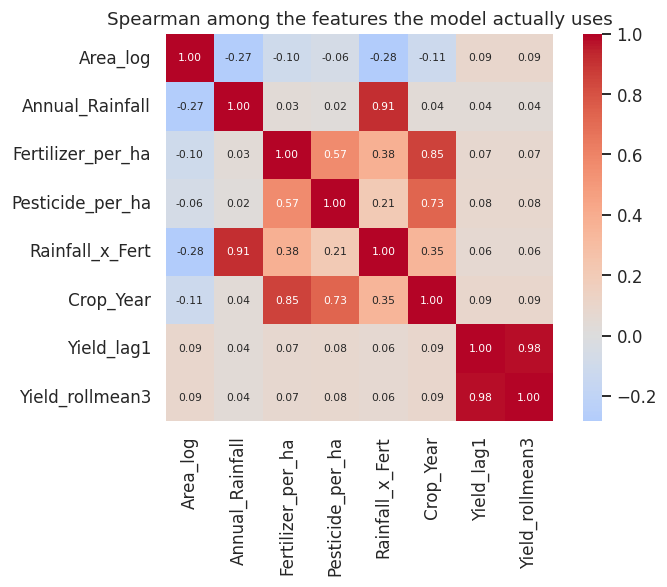

The per-hectare rates are almost independent of Area. The two rates are correlated with each other and with
their rainfall interaction (shared state-year structure, Section 4). Tree models are robust to this for
prediction, but SHAP credit is shared between correlated features, so the agronomic SHAP values should be
read as a group rather than one by one. The lag features are collinear by design (rollmean3 includes lag1).


In [49]:
raw_c = df[['Area', 'Fertilizer', 'Pesticide']].corr(method='spearman')
print("Spearman among the RAW columns (as in Fig. 3):"); display(raw_c.round(3))
model_num = ['Area_log', 'Annual_Rainfall', 'Fertilizer_per_ha', 'Pesticide_per_ha', 'Rainfall_x_Fert',
             'Crop_Year', 'Yield_lag1', 'Yield_rollmean3']
mc = df[model_num].corr(method='spearman')
def vif(frame):
    Z = (frame - frame.mean()) / frame.std(); out = {}
    for c in Z.columns:
        X_ = np.column_stack([np.ones(len(Z)), Z.drop(columns=c).values])
        beta, *_ = np.linalg.lstsq(X_, Z[c].values, rcond=None)
        r2 = 1 - ((Z[c].values - X_ @ beta) ** 2).sum() / ((Z[c].values - Z[c].mean()) ** 2).sum()
        out[c] = 1 / max(1 - r2, 1e-12)
    return pd.Series(out)
vif_df = pd.DataFrame({'VIF (linear)': vif(df[model_num]),
                       'max |Spearman| with another model feature': mc.abs().where(~np.eye(len(mc), dtype=bool)).max()})
display(vif_df.round(3))
fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(mc, annot=True, fmt='.2f', cmap='coolwarm', center=0, square=True, ax=ax, annot_kws={'size': 7})
ax.set_title('Spearman among the features the model actually uses'); plt.tight_layout(); plt.show()
CR['Spearman Area_log vs Fertilizer_per_ha (model features)'] = mc.loc['Area_log', 'Fertilizer_per_ha']
CR['Spearman Fertilizer_per_ha vs Pesticide_per_ha'] = mc.loc['Fertilizer_per_ha', 'Pesticide_per_ha']
print("The per-hectare rates are almost independent of Area. The two rates are correlated with each other and with")
print("their rainfall interaction (shared state-year structure, Section 4). Tree models are robust to this for")
print("prediction, but SHAP credit is shared between correlated features, so the agronomic SHAP values should be")
print("read as a group rather than one by one. The lag features are collinear by design (rollmean3 includes lag1).")

### R11.2 Skill relative to persistence and to the global mean

Skill in Section 10 is 1 − RMSE_model / RMSE_persistence. A negative value means the model is worse than
persistence, not worse than the mean. The table lists skill against both baselines, and an assertion confirms
that every model has positive skill against the global mean.

In [50]:
neg = bench_df[['Model', 'R2', 'RMSE', 'Skill vs baseline', 'Skill vs global mean']].rename(
    columns={'R2': 'R2_raw (random split)', 'RMSE': 'RMSE_raw', 'Skill vs baseline': 'Skill vs persistence'})
display(neg.style.format({'R2_raw (random split)': '{:.4f}', 'RMSE_raw': '{:.2f}',
                          'Skill vs persistence': '{:.1%}', 'Skill vs global mean': '{:.1%}'}))
assert (bench_df['Skill vs global mean'] > 0).all()
print("Suggested sentence: 'Skill is measured against the persistence forecast; negative values indicate models")
print("that do not beat last year's yield, although all models outperform the climatological (global-mean) baseline.'")

,Model,R2_raw (random split),RMSE_raw,Skill vs persistence,Skill vs global mean
0,ExtraTrees,0.9817,121.14,-7.0%,86.5%
1,RandomForest,0.9791,129.61,-14.5%,85.5%
2,KNN,0.9770,135.89,-20.1%,84.8%
3,DecisionTree,0.9753,140.81,-24.4%,84.3%
4,GradientBoost,0.9745,143.11,-26.5%,84.0%
5,XGBoost,0.9715,151.27,-33.7%,83.1%
6,LightGBM,0.9680,160.25,-41.6%,82.1%
7,Ridge,0.9442,211.58,-87.0%,76.4%
8,CatBoost,0.9413,217.04,-91.8%,75.8%
9,MLP,0.9287,239.22,-111.4%,73.3%


Suggested sentence: 'Skill is measured against the persistence forecast; negative values indicate models
that do not beat last year's yield, although all models outperform the climatological (global-mean) baseline.'


### R11.3 Data sources

- Dataset: *Agricultural Crop Yield in Indian States Dataset*, akshatgupta7, Kaggle, 2023.
  https://www.kaggle.com/datasets/akshatgupta7/crop-yield-in-indian-states-dataset
- Official crop-wise Area–Production–Yield statistics for India: Directorate of Economics & Statistics,
  Ministry of Agriculture & Farmers Welfare, Government of India.
- Official rainfall statistics for India: India Meteorological Department.

## R12. Summary of Reported Numbers

All key results of Part B in one table, also saved to `camera_ready_numbers.json`. Headline values refer to the
temporal hold-out (train ≤ 2015, test 2016–2020) with the model selected on the 2013–2015 validation years.

In [51]:
def _fmt(v):
    if isinstance(v, (float, np.floating)): return f"{v:.4f}"
    return str(v)
cr_df = pd.DataFrame({'Quantity': list(CR.keys()), 'Value': [_fmt(v) for v in CR.values()]})
pd.set_option('display.max_rows', 200)
display(cr_df)
with open('camera_ready_numbers.json', 'w') as f:
    json.dump({k: (float(v) if isinstance(v, (float, np.floating, int, np.integer)) else str(v)) for k, v in CR.items()}, f, indent=2)
print("Saved camera_ready_numbers.json")

,Quantity,Value
0,Sharma reconstruction R2 (with Production),0.9782
1,Sharma reconstruction R2 (without Production),0.9646
2,Random split: test targets reused as training lag1,0.7232
3,Permutation test: max R2_log with shuffled targets,-0.0118
4,[default LGBM] Temporal hold-out (<=2015 -> 2016-2020): R2_log,0.9694
5,[default LGBM] Temporal hold-out (<=2015 -> 2016-2020): R2_raw,0.9646
6,[default LGBM] Temporal hold-out (<=2015 -> 2016-2020): RMSE_log,0.1959
7,[default LGBM] Spatial LOSO (30 folds): R2_log,0.9680
8,[default LGBM] Spatial LOSO (30 folds): R2_raw,0.9479
9,[default LGBM] Spatial LOSO (30 folds): RMSE_log,0.2047


Saved camera_ready_numbers.json


## 22. Contribution Ledger and Conclusion <a id='22'></a>

Each contribution of this notebook and the limitation it addresses in the reviewed literature.

In [52]:
ledger = pd.DataFrame([
 (1,  'Formal data-quality/integrity audit (missingness, duplicates, invalid zero targets)',
      'Not reported in the ten papers we reviewed'),
 (2,  'Formal data-leakage audit: Yield = Production/Area identity documented and excluded',
      'Area+Production feature combination used in Sharma et al. 2023 (consistent with, not proof of, inflated accuracy)'),
 (3,  'Feature semantic audit: Fertilizer/Pesticide shown to be State x Year proxies, not crop-specific',
      'Haider 2024, Ennaji 2024, Sanchez 2025 treat these as independent crop-level signals'),
 (4,  'Explicit crop-unit heterogeneity handling (log target + crop as categorical control)',
      'No reviewed paper pools this many heterogeneous crops/units'),
 (5,  'Leakage-free agronomic-intensity feature set',
      'Most reviewed papers lack a documented feature-legitimacy check'),
 (6,  'Causal lag / rolling-mean features per (State, Crop, Season)',
      'No reviewed cross-sectional study uses within-series history'),
 (7,  'Multi-baseline skill-score framework (mean / crop-mean / persistence)',
      'Morales 2023: models showed only limited gain over trivial baseline'),
 (8,  'Random vs temporal vs spatial split comparison on a single, stated scale',
      'Morales 2023: time-based partitioning more realistic than random (extended to spatial)'),
 (9,  'Unified 12-algorithm benchmark spanning linear/kernel/instance/tree/boosting/neural',
      'Sharma, Zhuang, Haider, Ennaji, Sanchez each cover only 2-5 algorithms'),
 (10, 'Bayesian hyperparameter optimization (Optuna) with reported search spaces',
      'No reviewed paper reports principled tuning'),
 (11, 'Heterogeneous OOF stacking ensemble (tree + boosting + Ridge meta-learner)',
      'Extends Zhuang 2023 stacking beyond a single crop / meteorological-only features'),
 (12, 'Rolling-origin paired significance testing (Friedman + Wilcoxon + Holm)',
      'All reviewed papers report single-run point metrics only'),
 (13, 'Exact TreeSHAP incl. interaction values, local explanations and group-wise consistency',
      'Paudel 2023: attribution methods are approximate and miss interactions'),
 (14, 'Split-conformal intervals with conditional coverage and shift analysis',
      'All reviewed papers report point estimates only, no uncertainty'),
 (15, 'Leave-one-state-out and leave-one-crop-out transferability tests',
      'Haider 2024, Ennaji 2024, Zhuang 2023, Menon 2025: single-region/limited-crop scope'),
 (16, 'Crop-family clustering + cluster-specific sub-models vs monolithic model',
      'No reviewed paper tests specialization vs a single global model'),
 (17, 'Data-efficiency / learning-curve analysis',
      'Paudel 2023: neural models flagged as needing large training data'),
 (18, 'Spatio-temporal residual diagnostics (state x year error map)',
      'No reviewed paper localizes error geographically or temporally'),
 (19, 'Bootstrap feature-importance stability analysis',
      'Feature importance reported from a single fit in all reviewed papers'),
 (20, '[Revision] Cross-row leakage quantification for row-level random splits',
      'Random splits on panel data let a test target re-enter training as a lag feature'),
 (21, '[Revision] Target-permutation sanity check of the full pipeline',
      'No reviewed paper verifies its pipeline cannot learn from target-free inputs'),
 (22, '[Revision] Autoregressive-feature ablation against persistence',
      'Separates agronomic signal from series memory'),
 (23, '[Revision] Scale-free (growth-rate) target for cross-crop transfer',
      'Explains and reduces the unseen-crop transfer gap'),
 (24, '[Revision] Mondrian (crop-conditional) log-scale conformal intervals',
      'Marginal coverage can hide under-coverage for specific crops'),
 (25, '[Revision] Group-wise SHAP rank consistency across crops, states and periods',
      'Global attributions can hide heterogeneity'),
], columns=['#', 'Contribution (this notebook)', 'Limitation addressed (reviewed literature)'])

pd.set_option('display.max_colwidth', 110)
display(ledger)

,#,Contribution (this notebook),Limitation addressed (reviewed literature)
0,1,"Formal data-quality/integrity audit (missingness, duplicates, invalid zero targets)",Not reported in the ten papers we reviewed
1,2,Formal data-leakage audit: Yield = Production/Area identity documented and excluded,"Area+Production feature combination used in Sharma et al. 2023 (consistent with, not proof of, inflated ac..."
2,3,"Feature semantic audit: Fertilizer/Pesticide shown to be State x Year proxies, not crop-specific","Haider 2024, Ennaji 2024, Sanchez 2025 treat these as independent crop-level signals"
3,4,Explicit crop-unit heterogeneity handling (log target + crop as categorical control),No reviewed paper pools this many heterogeneous crops/units
4,5,Leakage-free agronomic-intensity feature set,Most reviewed papers lack a documented feature-legitimacy check
5,6,"Causal lag / rolling-mean features per (State, Crop, Season)",No reviewed cross-sectional study uses within-series history
6,7,Multi-baseline skill-score framework (mean / crop-mean / persistence),Morales 2023: models showed only limited gain over trivial baseline
7,8,"Random vs temporal vs spatial split comparison on a single, stated scale",Morales 2023: time-based partitioning more realistic than random (extended to spatial)
8,9,Unified 12-algorithm benchmark spanning linear/kernel/instance/tree/boosting/neural,"Sharma, Zhuang, Haider, Ennaji, Sanchez each cover only 2-5 algorithms"
9,10,Bayesian hyperparameter optimization (Optuna) with reported search spaces,No reviewed paper reports principled tuning


### Conclusion

The framework is evaluated on a real multi-crop (55), multi-region (30 states), 24-year panel with a leakage-safe
protocol. Four findings summarize the results:

1. **Row-level random splits are optimistic on panel data.** Most random-split test targets re-enter training as
   lag features of neighbouring rows (R1.3). The temporal hold-out is therefore the headline evaluation (R2, R4).
2. **Predictive skill comes mainly from yield history.** Agronomic inputs add no measurable accuracy once history
   is available. Gains over persistence are modest (R3, R6).
3. **Unseen-region transfer works well; unseen-crop transfer depends on the yield level.** A scale-free
   growth-rate target reduces the gap for crops whose level lies outside the training range (R2, R8).
4. **Log-scale and crop-conditional conformal intervals give near-nominal conditional coverage.** Their behaviour
   under temporal and spatial shift is quantified (R9).

Future work: remote-sensing covariates, extending the panel beyond 2020, and cross-national transfer.